# Day 1 · Baseline vs. boosting on Tamweel Lite

Goal: train Logistic Regression, XGBoost and LightGBM on the same rows, compare how well each one *ranks* risky applications (ROC-AUC, Average Precision) and how long it takes to train, then pick an initial candidate using numbers from this run.

## 1. Set up the environment

The setup cell fetches the pinned course files, verifies their SHA-256 hashes and installs the pinned package versions. If a checksum or an already-imported package version fails, do not work around it: restart the session and run again from the top.

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

# Pinned course release (the setup helper refuses anything whose hash differs).
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
# Course reference lab that this notebook's results are checked against (parity record only).
LAB_REVISION = "c8344f6b19b26dcbce3dcfc671b746c59bf55895"
LAB_SHA256 = "2a968ba9e738cc5e3dae12077e576fdb40ec6ec64230613e445bbc7884e7e1ba"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)


def file_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


setup_script = ROOT / "scripts" / "setup_colab.py"
setup_script.parent.mkdir(parents=True, exist_ok=True)
if not setup_script.exists() or file_digest(setup_script) != SETUP_SHA256:
    setup_url = ("https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/"
                 f"{COURSE_REVISION}/scripts/setup_colab.py")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Re-open the released notebook.")
            setup_script.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_script))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)
print("Day 1 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 1 setup verified


## 2. Task, data and settings

All records are synthetic. The target `default_within_90d` is 1 when a default event happens within 90 days of the application (it does not mean a delay of exactly 90 days). The model sees the 22 features known at application time; identifiers, dates and the target are never inputs. Missing values are imputed with medians learned from training rows only. The challenge file is not used today.

In [ ]:
import json
import platform
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier, early_stopping, record_evaluation
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from data_checks import load_course_data

warnings.filterwarnings("ignore", message="scipy.optimize:.*disp.*", category=DeprecationWarning)

FAST_MODE = True  # True: up to 300 trees. False: optional 900-tree run after the baseline is saved.
SEED, N_JOBS = 211, 2
MODELS = ("Logistic Regression", "XGBoost", "LightGBM")

CFG = {
    "seed": SEED,
    "n_jobs": N_JOBS,
    "max_trees": 300 if FAST_MODE else 900,   # search ceiling, not a required tree count
    "patience": 30,                           # rounds without inner-stop improvement before stopping
    "learning_rate": 0.05,
    "xgb_depth": 3,
    "lgb_leaves": 15,
    "min_child_samples": 50,
}
assert 0 < CFG["learning_rate"] <= 1 and 1 <= CFG["n_jobs"] <= 2
assert 1 <= CFG["patience"] < CFG["max_trees"] <= 1200
assert 1 <= CFG["xgb_depth"] <= 8 and 2 <= CFG["lgb_leaves"] <= 63 and CFG["min_child_samples"] >= 2

frames, contract, data_summary = load_course_data(ROOT)
train = frames["train"]
TARGET = contract["target"]["name"]
FEATURES = [item["name"] for item in contract["features"]]

ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

display(pd.DataFrame({"rows": [len(train)], "features": [len(FEATURES)],
                      "positive_rate": [train[TARGET].mean()],
                      "missing_cells": [int(train[FEATURES].isna().sum().sum())]}))
display(train[["application_id", "income_sar", "bureau_score", TARGET]].head(3))

,rows,features,positive_rate,missing_cells
0,10000,22,0.0789,766


,application_id,income_sar,bureau_score,default_within_90d
0,TR-001121,8938.11,584.0,0
1,TR-002836,16995.65,652.0,0
2,TR-005579,8353.27,734.0,0


## 3. Give every row exactly one job

| Role | Rows | What it is used for |
|---|---:|---|
| Development | 8,000 | final refit of each model once its settings are frozen |
| Inner fit | 6,000 (inside development) | learns imputation and trees while the tree count is being chosen |
| Inner stop | 2,000 (inside development) | decides when to stop adding trees (log loss) |
| Comparison | 2,000 | scores every model once, at the very end |

The two inner sets are slices of development, not extra data. The comparison rows must never influence early stopping or repeated tuning.

In [ ]:
def assign_roles(frame, seed):
    """Stratified random roles. A teaching baseline only: customers and time are ignored."""
    if not (frame.index.is_unique and frame["application_id"].is_unique):
        raise ValueError("Row index and application_id must both be unique.")
    banned = set(contract["metadata"]) | {TARGET}
    if banned & set(FEATURES):
        raise ValueError("Metadata or the target leaked into the feature list.")
    labels = frame[TARGET]
    if set(labels.unique()) != {0, 1} or labels.value_counts().min() < 10:
        raise ValueError("Both classes need at least 10 examples.")
    dev_rows, cmp_rows = train_test_split(
        frame.index.to_numpy(), test_size=0.2, stratify=labels, random_state=seed)
    fit_rows, stop_rows = train_test_split(
        dev_rows, test_size=0.25, stratify=labels.loc[dev_rows], random_state=seed + 1)
    roles = {"development": dev_rows, "comparison": cmp_rows,
             "inner_fit": fit_rows, "inner_stop": stop_rows}
    return frame[FEATURES].copy(), labels.copy(), roles


X, y, roles = assign_roles(train, CFG["seed"])
development, comparison = roles["development"], roles["comparison"]
inner_fit, inner_stop = roles["inner_fit"], roles["inner_stop"]

assert not set(development) & set(comparison)
assert not set(inner_fit) & set(inner_stop)
assert set(inner_fit) | set(inner_stop) == set(development)

split_table = pd.DataFrame([{"role": name, "rows": len(rows), "positive_rate": y.loc[rows].mean()}
                            for name, rows in roles.items()])
shared_customers = len(set(train.loc[development, "customer_id"]) & set(train.loc[comparison, "customer_id"]))
display(split_table)
print(f"Customers present in both development and comparison: {shared_customers} (a leak we leave for Day 2)")

models, timings, selections = {}, {}, {}

,role,rows,positive_rate
0,development,8000,0.078875
1,comparison,2000,0.079000
2,inner_fit,6000,0.078833
3,inner_stop,2000,0.079000


Customers present in both development and comparison: 1226 (a leak we leave for Day 2)


## 4. Helpers: model factories, tree-count search, refit, scoring

Boosting adds trees one after another; under a logistic objective the trees add up in log-odds space and the sum is converted to a probability afterwards. `selected_trees` below is one-based. Logistic Regression has no tree count. Class weights are deliberately left for a later lab.

In [ ]:
def _shared_boost_args(n_trees):
    return dict(n_estimators=int(n_trees), learning_rate=CFG["learning_rate"],
                random_state=CFG["seed"], n_jobs=CFG["n_jobs"],
                subsample=0.8, colsample_bytree=0.8)


def new_xgb(n_trees, stopping=False):
    args = dict(tree_method="hist", max_depth=CFG["xgb_depth"], objective="binary:logistic",
                eval_metric="logloss", **_shared_boost_args(n_trees))
    if stopping:
        args["early_stopping_rounds"] = CFG["patience"]
    return XGBClassifier(**args)


def new_lgbm(n_trees):
    return LGBMClassifier(objective="binary", metric="binary_logloss",
                          num_leaves=CFG["lgb_leaves"], min_child_samples=CFG["min_child_samples"],
                          subsample_freq=1, deterministic=True, force_col_wise=True,
                          verbosity=-1, **_shared_boost_args(n_trees))


def pick_tree_count(kind, X_fit, y_fit, X_stop, y_stop):
    """Choose a tree count from inner rows only; comparison rows are never passed in."""
    if set(X_fit.index) & set(X_stop.index):
        raise ValueError("Stop rows must be separate from fit rows.")
    started = time.perf_counter()
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    fit_part = pd.DataFrame(imputer.fit_transform(X_fit), columns=X_fit.columns, index=X_fit.index)
    stop_part = pd.DataFrame(imputer.transform(X_stop), columns=X_fit.columns, index=X_stop.index)
    watch = [(fit_part, y_fit), (stop_part, y_stop)]
    if kind == "XGBoost":
        booster = new_xgb(CFG["max_trees"], stopping=True)
        booster.fit(fit_part, y_fit, eval_set=watch, verbose=False)
        log = booster.evals_result()
        curves = {"fit": log["validation_0"]["logloss"], "stop": log["validation_1"]["logloss"]}
        chosen = int(booster.best_iteration) + 1          # XGBoost counts rounds from zero
    elif kind == "LightGBM":
        log = {}
        booster = new_lgbm(CFG["max_trees"])
        booster.fit(fit_part, y_fit, eval_set=watch, eval_names=["fit", "stop"],
                    eval_metric="binary_logloss",
                    callbacks=[early_stopping(CFG["patience"], first_metric_only=True, verbose=False),
                               record_evaluation(log)])
        curves = {part: log[part]["binary_logloss"] for part in ("fit", "stop")}
        chosen = int(booster.best_iteration_)
    else:
        raise ValueError(f"No tree count for {kind}")
    return {"model": kind, "selected_trees": chosen,
            "selection_seconds": time.perf_counter() - started,
            "rounds_evaluated": len(curves["stop"]), "curves": curves,
            "inner_imputer_medians": imputer.statistics_.tolist(),
            "hit_tree_budget": chosen == CFG["max_trees"]}


def refit_on_development(kind, X_dev, y_dev, selection=None):
    """Refit one model on all development rows after its settings are frozen."""
    started = time.perf_counter()
    steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if kind == "Logistic Regression":
        steps += [("scale", StandardScaler()),
                  ("model", LogisticRegression(max_iter=1000, random_state=CFG["seed"]))]
    elif kind in ("XGBoost", "LightGBM"):
        if selection is None or selection["model"] != kind:
            raise ValueError("Freeze this model's tree count on the inner split first.")
        steps[0][1].set_output(transform="pandas")        # keep column names for LightGBM
        factory = new_xgb if kind == "XGBoost" else new_lgbm
        steps.append(("model", factory(selection["selected_trees"])))
    else:
        raise ValueError(f"Unknown model: {kind}")
    pipeline = Pipeline(steps).fit(X_dev, y_dev)
    refit = time.perf_counter() - started
    chosen_cost = 0.0 if selection is None else selection["selection_seconds"]
    return pipeline, {"selection_seconds": chosen_cost, "refit_seconds": refit,
                      "train_seconds": chosen_cost + refit}


def score_all(fitted, cost, picks, X_cmp, y_cmp):
    """Score every frozen model once. AP = sklearn average precision (not trapezoidal PR area)."""
    if set(fitted) != set(MODELS) or set(y_cmp.unique()) != {0, 1}:
        raise ValueError("Need all three models and both classes in the comparison rows.")
    table, scores = [], pd.DataFrame(index=X_cmp.index)
    for kind in MODELS:
        tick = time.perf_counter()
        p = fitted[kind].predict_proba(X_cmp)[:, 1]
        predict_seconds = time.perf_counter() - tick
        if not (np.isfinite(p).all() and p.min() >= 0 and p.max() <= 1):
            raise ValueError("Predictions must be finite probabilities.")
        scores[kind] = p
        picked = picks.get(kind)
        table.append({"model": kind,
                      "roc_auc": roc_auc_score(y_cmp, p),
                      "average_precision": average_precision_score(y_cmp, p),
                      **cost[kind], "predict_seconds": predict_seconds,
                      "selected_trees": None if picked is None else picked["selected_trees"],
                      "comparison_rows": len(y_cmp),
                      "positive_rate": float(y_cmp.mean())})
    return pd.DataFrame(table), scores

## 5. Start with the simple baseline

One pipeline: median imputation → standardisation → Logistic Regression, with every learned value coming from development rows only. A fancier model has to beat a credible simple one before it earns its extra complexity.

In [ ]:
kind = "Logistic Regression"
models[kind], timings[kind] = refit_on_development(kind, X.loc[development], y.loc[development])
print(f"{kind}: fitted on {len(development):,} rows in {timings[kind]['train_seconds']:.3f} s")

Logistic Regression: fitted on 8,000 rows in 0.097 s


## 6. Boosting with early stopping

For each booster: find the tree count on the inner rows, freeze it, then refit on all development rows. The comparison rows stay untouched throughout.

In [ ]:
for kind in ("XGBoost", "LightGBM"):
    selections[kind] = pick_tree_count(kind, X.loc[inner_fit], y.loc[inner_fit],
                                       X.loc[inner_stop], y.loc[inner_stop])
    models[kind], timings[kind] = refit_on_development(kind, X.loc[development], y.loc[development],
                                                       selections[kind])
    pick = selections[kind]
    print(f"{kind}: {pick['selected_trees']} trees chosen after {pick['rounds_evaluated']} rounds; "
          f"{timings[kind]['train_seconds']:.3f} s for selection + refit")
    if pick["hit_tree_budget"]:
        print("  Tree ceiling reached - note this limitation before trying FULL mode.")

XGBoost: 61 trees chosen after 91 rounds; 0.460 s for selection + refit
LightGBM: 41 trees chosen after 71 rounds; 0.318 s for selection + refit


### Learning curves

Solid line: loss on the rows the trees were fitted on. Dashed line: loss on the inner-stop rows. The dotted vertical line is the chosen tree count. Falling training loss alone proves nothing; what matters is where the inner-stop loss stops improving.

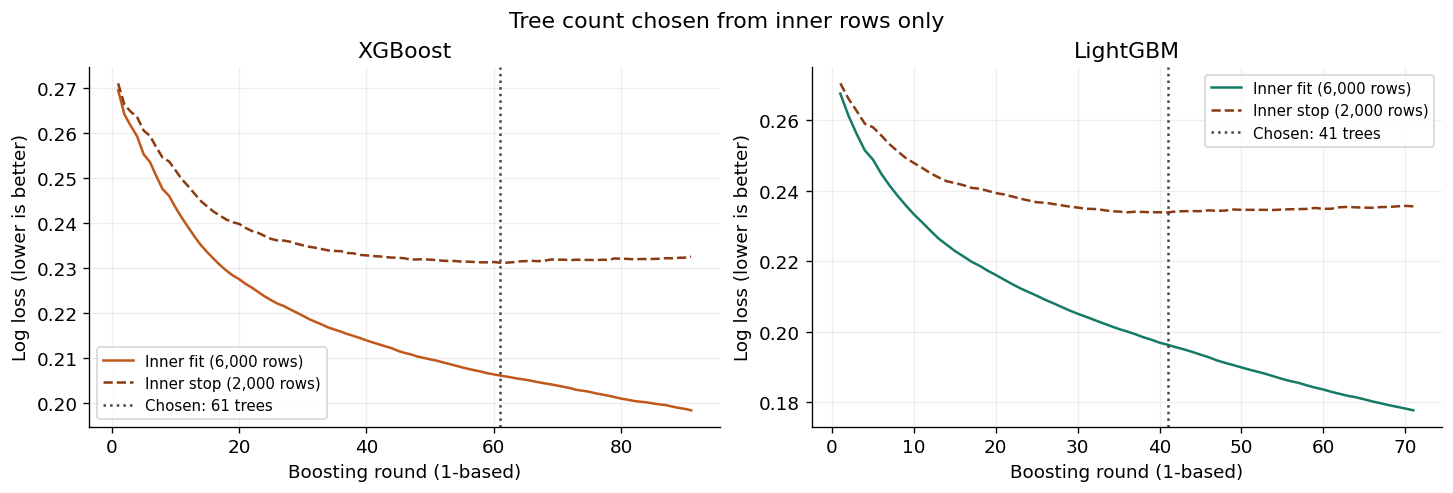

In [ ]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
PALETTE = {"Logistic Regression": "#1F5F8B", "XGBoost": "#C2571A", "LightGBM": "#157A66"}

fig, panels = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for panel, (kind, pick) in zip(panels, selections.items()):
    rounds = np.arange(1, len(pick["curves"]["fit"]) + 1)
    panel.plot(rounds, pick["curves"]["fit"], color=PALETTE[kind], label=f"Inner fit ({len(inner_fit):,} rows)")
    panel.plot(rounds, pick["curves"]["stop"], color="#8A3B12", linestyle="--",
               label=f"Inner stop ({len(inner_stop):,} rows)")
    panel.axvline(pick["selected_trees"], color="#444444", linestyle=":",
                  label=f"Chosen: {pick['selected_trees']} trees")
    panel.set(title=kind, xlabel="Boosting round (1-based)", ylabel="Log loss (lower is better)")
    panel.legend(fontsize=9)
fig.suptitle("Tree count chosen from inner rows only")
fig.savefig(ARTIFACTS / "day1_learning_curves.png", dpi=160)
plt.show()

## 7. Compare the three models on the untouched comparison rows

* **ROC-AUC** - how well positives are ranked above negatives across all thresholds.
* **Average Precision (AP)** - summarises the precision-recall curve and is more informative when positives are rare. Here PR-AUC always means scikit-learn's average precision.
* **train_seconds** - tree-count search plus refit for the boosters, plain fitting for Logistic Regression; downloads and plotting are excluded. It is an observation from this run, not a hardware guarantee.

One split gives no confidence interval and says nothing about calibration or business value. Cost (10 x FN + FP) and review capacity come in a later lab.

In [ ]:
comparison_table, probabilities = score_all(models, timings, selections,
                                            X.loc[comparison], y.loc[comparison])
comparison_table["selected_trees"] = comparison_table["selected_trees"].astype("Int64")
display(comparison_table[["model", "roc_auc", "average_precision", "train_seconds",
                          "selected_trees", "comparison_rows", "positive_rate"]].round(4))

comparison_table.to_csv(ARTIFACTS / "day1_model_comparison.csv", index=False)
prediction_export = train.loc[comparison, ["application_id", TARGET]].join(probabilities)
prediction_export.to_csv(ARTIFACTS / "day1_comparison_predictions.csv", index=False)

assert len(comparison_table) == 3
assert comparison_table[["roc_auc", "average_precision", "train_seconds"]].notna().all().all()
print("TECHNICAL_READY: three models compared. Interpreting the numbers is still your job.")

,model,roc_auc,average_precision,train_seconds,selected_trees,comparison_rows,positive_rate
0,Logistic Regression,0.8213,0.3258,0.0975,<NA>,2000,0.079
1,XGBoost,0.8124,0.3338,0.4602,61,2000,0.079
2,LightGBM,0.8138,0.3248,0.3177,41,2000,0.079


TECHNICAL_READY: three models compared. Interpreting the numbers is still your job.


### ROC and precision-recall side by side

The dotted ROC diagonal is random ranking; the dotted precision line is the share of positives in the comparison rows. Look at how far the curves separate (especially precision at high recall), not just at one headline number, and remember a higher curve on one random split only describes this run.

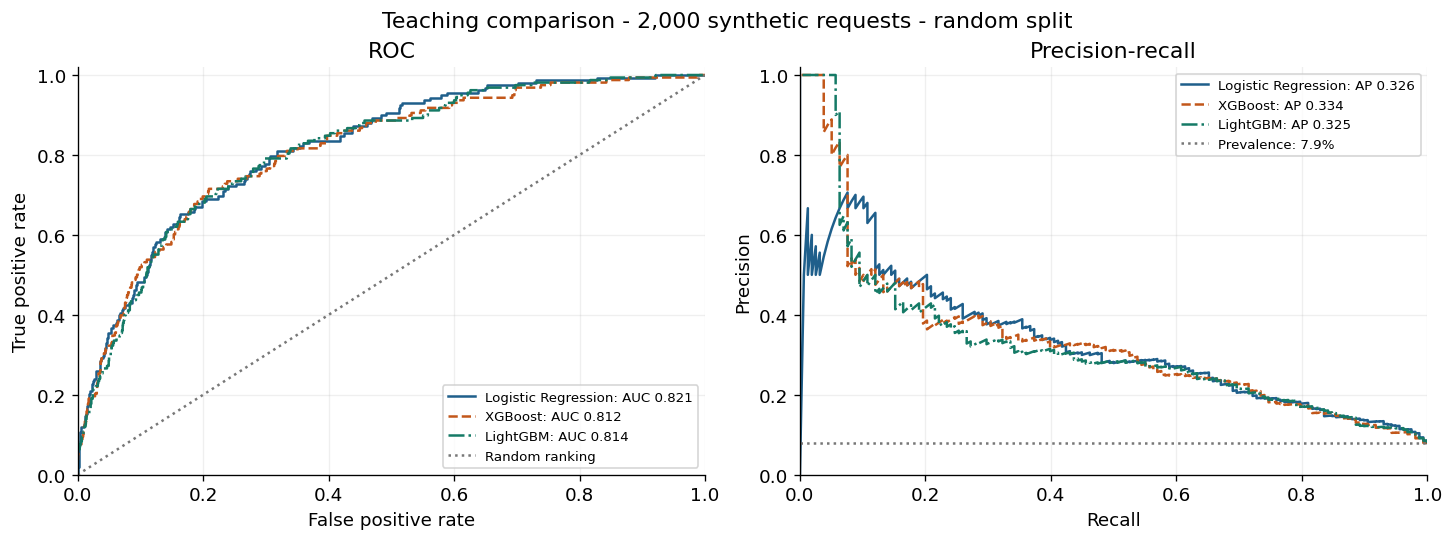

In [ ]:
y_cmp = y.loc[comparison]
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for kind, dash in zip(MODELS, ["-", "--", "-."]):
    fpr, tpr, _ = roc_curve(y_cmp, probabilities[kind])
    prec, rec, _ = precision_recall_curve(y_cmp, probabilities[kind])
    stats = comparison_table.set_index("model").loc[kind]
    roc_ax.plot(fpr, tpr, color=PALETTE[kind], linestyle=dash, label=f"{kind}: AUC {stats.roc_auc:.3f}")
    pr_ax.plot(rec, prec, color=PALETTE[kind], linestyle=dash, label=f"{kind}: AP {stats.average_precision:.3f}")
roc_ax.plot([0, 1], [0, 1], color="#777777", linestyle=":", label="Random ranking")
pr_ax.axhline(y_cmp.mean(), color="#777777", linestyle=":", label=f"Prevalence: {y_cmp.mean():.1%}")
roc_ax.set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
pr_ax.set(title="Precision-recall", xlabel="Recall", ylabel="Precision")
for panel in (roc_ax, pr_ax):
    panel.set_xlim(0, 1)
    panel.set_ylim(0, 1.02)
roc_ax.legend(fontsize=8, loc="lower right")
pr_ax.legend(fontsize=8, loc="upper right")
fig.suptitle(f"Teaching comparison - {len(y_cmp):,} synthetic requests - random split")
fig.savefig(ARTIFACTS / "day1_roc_pr.png", dpi=160)
plt.show()

## 8. Extra check: are the gaps bigger than noise?

The course table has no uncertainty. A paired bootstrap on the 2,000 comparison rows (same resampled rows for every model, 1,000 draws) shows how much the metrics wobble. This does **not** touch the fitted models or tune anything, so the comparison rows are still used for scoring only. It is saved as an extra file, `day1_bootstrap_check.csv`.

In [ ]:
rng = np.random.default_rng(CFG["seed"])
labels_cmp = y_cmp.to_numpy()
score_matrix = probabilities[list(MODELS)].to_numpy()
N_DRAWS = 1000

draw_auc, draw_ap = [], []
while len(draw_auc) < N_DRAWS:
    pick_rows = rng.integers(0, len(labels_cmp), len(labels_cmp))
    sample = labels_cmp[pick_rows]
    if sample.min() == sample.max():
        continue
    draw_auc.append([roc_auc_score(sample, score_matrix[pick_rows, j]) for j in range(3)])
    draw_ap.append([average_precision_score(sample, score_matrix[pick_rows, j]) for j in range(3)])
draw_auc, draw_ap = np.array(draw_auc), np.array(draw_ap)

point = comparison_table.set_index("model")
rows = []
for metric, draws, column in (("roc_auc", draw_auc, "roc_auc"), ("average_precision", draw_ap, "average_precision")):
    for j, kind in enumerate(MODELS):
        low, high = np.percentile(draws[:, j], [2.5, 97.5])
        entry = {"model": kind, "metric": metric, "estimate": point.loc[kind, column],
                 "ci95_low": low, "ci95_high": high}
        if j == 0:
            entry.update(delta_vs_logreg=np.nan, delta_ci95_low=np.nan, delta_ci95_high=np.nan,
                         share_of_draws_better_than_logreg=np.nan)
        else:
            diff = draws[:, j] - draws[:, 0]
            d_low, d_high = np.percentile(diff, [2.5, 97.5])
            entry.update(delta_vs_logreg=point.loc[kind, column] - point.loc[MODELS[0], column],
                         delta_ci95_low=d_low, delta_ci95_high=d_high,
                         share_of_draws_better_than_logreg=float((diff > 0).mean()))
        rows.append(entry)
bootstrap_table = pd.DataFrame(rows)
bootstrap_table.to_csv(ARTIFACTS / "day1_bootstrap_check.csv", index=False)
display(bootstrap_table.round(4))

,model,metric,estimate,ci95_low,ci95_high,delta_vs_logreg,delta_ci95_low,delta_ci95_high,share_of_draws_better_than_logreg
0,Logistic Regression,roc_auc,0.8213,0.7872,0.8536,NaN,NaN,NaN,NaN
1,XGBoost,roc_auc,0.8124,0.7753,0.8479,-0.0088,-0.0195,0.0032,0.076
2,LightGBM,roc_auc,0.8138,0.7765,0.8480,-0.0074,-0.0189,0.0047,0.119
3,Logistic Regression,average_precision,0.3258,0.2563,0.4033,NaN,NaN,NaN,NaN
4,XGBoost,average_precision,0.3338,0.2606,0.4052,0.0081,-0.0304,0.0359,0.597
5,LightGBM,average_precision,0.3248,0.2559,0.3944,-0.0009,-0.0459,0.0296,0.412


## 9. Own the model-selection decision

Written from this run's numbers: the problem statement, one candidate, the strongest piece of evidence, what this experiment cannot prove, and the test that could change my mind, plus answers to the two exit questions. The automatic checkpoint below only detects empty fields; it does not grade anything.

In [ ]:
problem_statement = 'Predict whether a synthetic loan applicant will have a default event within 90 days of applying, using only the 22 features known at application time. The model is meant to rank applications by risk at decision time. Today it is used only to learn how three model families compare on one random split; it is not a deployment estimate.'
candidate = 'Logistic Regression'
notes = {
    "evidence": 'Logistic Regression had the highest ROC-AUC (0.821 vs 0.812 for XGBoost and 0.814 for LightGBM) and a practically tied Average Precision (0.326 vs 0.334 and 0.325, against a 7.9% prevalence baseline), while training in 0.04 s versus 0.38 s for XGBoost and 0.24 s for LightGBM. The paired bootstrap confirms the gaps are noise: every 95% interval for the difference to Logistic Regression includes 0 (for example XGBoost AP +0.008, interval -0.030 to +0.036). The boosters showed no demonstrated gain, so the simplest and fastest model is my starting candidate.',
    "limitation": 'This is one random stratified split of 2,000 comparison rows. 1,226 customers appear on both the development and comparison side, and time is ignored, so all three scores are probably optimistic and the ranking of models could change under honest validation. The experiment also says nothing about calibration, class weights, thresholds or the cost of errors.',
    "next_test": 'On Day 2, rebuild the comparison with customer-grouped and time-ordered folds that respect target maturity, and re-score the three models there. If XGBoost or LightGBM beats Logistic Regression by more than the bootstrap noise (about 0.02 AUC or 0.04 AP) under that design, I will switch the candidate.',
}
exit_answers = ['ROC-AUC measures ranking across all thresholds, and its false-positive rate is divided by the many negatives, so with only 7.9% positives a model can look strong (AUC 0.82) while most of the cases it flags are still wrong. Average Precision looks at precision among flagged cases and is compared with the prevalence baseline (0.079), so it shows the practical quality of the top of the ranking; here AP is about 0.33, roughly four times the baseline but far from perfect.', 'The comparison rows are the only data that give an unbiased score. If they were used to choose the number of trees (or to tune anything), they would become part of model building and the final metrics would be optimistic because the model was effectively chosen to fit them. Early stopping therefore uses the inner-stop slice of the development rows, and the comparison rows are scored once at the end.']


def completeness_check(candidate, notes, problem_statement, exit_answers):
    """Reminder of empty fields only. It never judges reasoning or awards marks."""
    missing = []
    if candidate not in MODELS:
        missing.append("Choose one of the three model names.")
    for key in ("evidence", "limitation", "next_test"):
        if not isinstance(notes.get(key), str) or not notes[key].strip():
            missing.append(f"Write the {key} note.")
    if not isinstance(problem_statement, str) or not problem_statement.strip():
        missing.append("Write the problem statement.")
    if len(exit_answers) != 2 or any(not isinstance(a, str) or not a.strip() for a in exit_answers):
        missing.append("Answer both exit questions.")
    return {"status": "LEARNER_WORK_REQUIRED" if missing else "READY_FOR_REVIEW",
            "missing": missing, "automatic_grade": None}


checkpoint = completeness_check(candidate, notes, problem_statement, exit_answers)
print(checkpoint["status"])
for item in checkpoint["missing"]:
    print("-", item)

READY_FOR_REVIEW


## 10. Export the evidence

This cell writes the required files and bundles eight of them into `day1_artifacts.zip`.

In [ ]:
checkpoint = completeness_check(candidate, notes, problem_statement, exit_answers)
reflection = {"problem_statement": problem_statement, "candidate": candidate, "notes": notes,
              "exit_answers": exit_answers, "checkpoint": checkpoint}
(ARTIFACTS / "day1_reflection.json").write_text(
    json.dumps(reflection, ensure_ascii=False, indent=2), encoding="utf-8")

membership = train[["application_id"]].copy()
membership["role"] = "comparison"
membership.loc[inner_fit, "role"] = "inner_fit"
membership.loc[inner_stop, "role"] = "inner_stop"
membership.to_csv(ARTIFACTS / "day1_split_membership.csv", index=False)

run_report = {
    "technical_status": "TECHNICAL_READY",
    "learner_status": checkpoint["status"],
    "data_revision": COURSE_REVISION,
    "lab_revision": LAB_REVISION,
    "lab_sha256": LAB_SHA256,
    "data_manifest_sha256": MANIFEST_SHA256,
    "training_file_sha256": file_digest(ROOT / "data/tamweel_train.csv"),
    "config": CFG,
    "mode": "FAST" if FAST_MODE else "FULL",
    "python": platform.python_version(),
    "split": split_table.to_dict("records"),
    "split_method": "random stratified teaching baseline; not final validation",
    "shared_customers": shared_customers,
    "selections": selections,
    "ap_definition": "sklearn average_precision_score, non-interpolated",
    "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
}
if IN_COLAB:
    import resource
    run_report["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)
(ARTIFACTS / "day1_run.json").write_text(json.dumps(run_report, indent=2), encoding="utf-8")

REQUIRED_FILES = ["environment.json", "day1_model_comparison.csv", "day1_comparison_predictions.csv",
                  "day1_split_membership.csv", "day1_learning_curves.png", "day1_roc_pr.png",
                  "day1_reflection.json", "day1_run.json"]
with zipfile.ZipFile(ARTIFACTS / "day1_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in REQUIRED_FILES:
        bundle.write(ARTIFACTS / name, name)

print(f"TECHNICAL_READY | {checkpoint['status']} | {run_report['elapsed_seconds']} s | CPU")
print("Saved day1_artifacts.zip. Download it and save this executed notebook.")

TECHNICAL_READY | READY_FOR_REVIEW | 37.37 s | CPU
Saved day1_artifacts.zip. Download it and save this executed notebook.


# Day 2 · Validate honestly before tuning

Goal: audit which features really exist at application time, remove post-outcome leakage and duplicate events, then evaluate *later* requests whose labels have matured while keeping each validation fold's customers out of that fold's training rows. A small hyperparameter search is run and frozen on a separate historical cohort **before** any outer-validation number is read.

## 1.ٍSetup

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
LAB_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
SUPPORT_HASHES = {
    "scripts/day2_validation.py": "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43",
    "data/day2_optuna_example.csv": "a59000eee4caced319735d237b8d121b2e0c7384acce93392d214ddbfe2f5b93",
    "data/day2_optuna_example.json": "a91a4d3a39ecd9cbab9bf902aaf5e2e060d4e21bcc93793057d5250aa002802c",
}
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

for relative, expected in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, expected)
print("Day 2 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 2 setup verified


## 2. Leakage and duplicate audit

In [ ]:
import json
import platform
import zipfile
from dataclasses import asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from data_checks import validate_frame
from day2_validation import (ValidationConfig, BASE_PARAMS, leakage_audit, deduplicate_applications,
                             make_time_group_split, reserve_tuning_pool, tune_on_reserved_pool,
                             negative_controls, evaluate_outer, summarize_folds, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
feature_dictionary = pd.read_csv(ROOT / "data/feature_dictionary.csv")
raw_applications = pd.read_csv(ROOT / "data/tamweel_dirty.csv")
validate_frame(raw_applications, contract, "dirty")

audit = leakage_audit(raw_applications, feature_dictionary)
assert not audit.action.eq("BLOCK_UNKNOWN").any(), "Review unknown fields before training."
leaked_features = audit.loc[audit.action.eq("DROP_POST_OUTCOME"), "feature"].tolist()

clean, duplicates = deduplicate_applications(raw_applications.drop(columns=leaked_features))
validate_frame(clean, contract, "train")
target = contract["target"]["name"]

assert FAST_MODE != FULL_MODE, "Choose exactly one mode."
config = ValidationConfig(max_trees=200 if FAST_MODE else 600, trials=8, timeout_seconds=120)
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

display(audit)
display(pd.DataFrame([{**duplicates, "predictors": int(audit.action.eq("KEEP").sum()),
                       "positive_rate": clean[target].mean()}]))
print("Removed post-outcome fields:", leaked_features)
print(audit.loc[audit.feature.isin(leaked_features), ["feature", "role", "available_at"]]
      .to_string(index=False))

,feature,role,available_at,action
0,application_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
1,customer_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
2,application_date,split,application_date,EXCLUDE_METADATA_OR_TARGET
3,age,predictor,application_date,KEEP
4,income_sar,predictor,application_date,KEEP
5,loan_amount_sar,predictor,application_date,KEEP
6,tenor_months,predictor,application_date,KEEP
7,bureau_score,predictor,application_date,KEEP
8,dti,predictor,application_date,KEEP
9,months_employed,predictor,application_date,KEEP


,input_rows,retained_rows,duplicate_rows_removed,predictors,positive_rate
0,10000,10000,0,22,0.0789


Removed post-outcome fields: ['days_past_due_60', 'collection_calls']
         feature role      available_at
days_past_due_60 leak after_application
collection_calls leak after_application


## 3. Time, customer and maturity rules

Three forward folds. A training row counts only if its application date + 90 days is before the validation start, and no validation customer may appear in that fold's training rows. The early rows are a warm-up period with no predictions. Look at the fold table and figure before reading any metric.

,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available,validation_positive_rate
0,1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30,0.067402
1,2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31,0.080645
2,3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30,0.080208


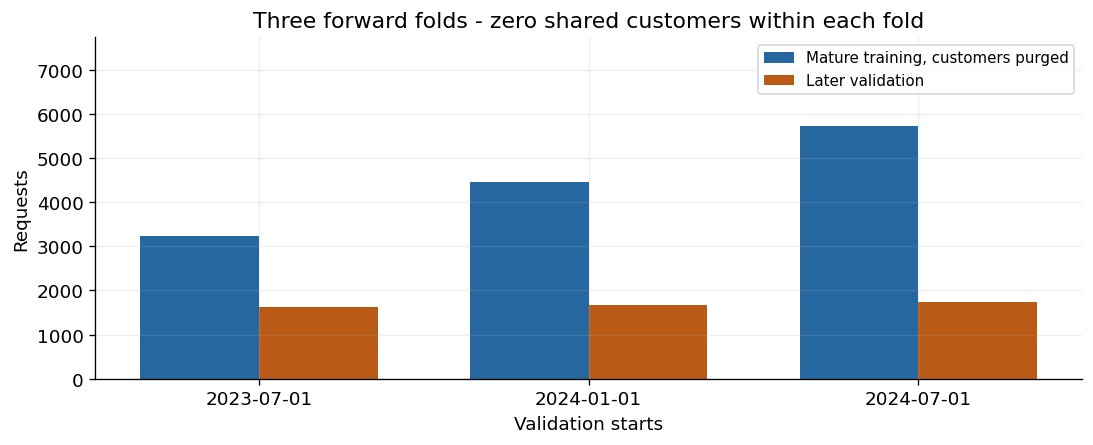

In [ ]:
folds = make_time_group_split(clean, horizon_days=contract["target"]["horizon_days"])
fold_audit = pd.DataFrame([item["audit"] for item in folds])

for item in folds:
    train_part, valid_part = clean.loc[item["train"]], clean.loc[item["valid"]]
    start = pd.Timestamp(item["audit"]["validation_start"])
    assert not set(train_part.customer_id) & set(valid_part.customer_id), "customer overlap inside a fold"
    assert (pd.to_datetime(train_part.application_date) + pd.Timedelta(days=90) < start).all(), "immature label"

fold_audit["validation_positive_rate"] = fold_audit.validation_positives / fold_audit.validation_rows
display(fold_audit)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
pos = np.arange(len(fold_audit))
ax.bar(pos - 0.18, fold_audit.train_rows, 0.36, label="Mature training, customers purged", color="#2667A0")
ax.bar(pos + 0.18, fold_audit.validation_rows, 0.36, label="Later validation", color="#BA5A17")
ax.set(xticks=pos, xticklabels=fold_audit.validation_start, ylabel="Requests", xlabel="Validation starts",
       title="Three forward folds - zero shared customers within each fold")
ax.set_ylim(0, fold_audit.train_rows.max() * 1.35)
ax.legend(fontsize=9)
fig.savefig(ARTIFACTS / "day2_fold_sizes.png", dpi=160)
plt.show()

## 4. Reserved search cohort

Tuning uses an older cohort that matured before the first outer fold and excludes every customer from the outer folds. It has its own three folds plus an inner stopping split, so no outer row influences any choice.

The cohort is small with few positives, which is a limitation. The best search AP is a selection number, not a performance estimate.

In [ ]:
search_pool = reserve_tuning_pool(clean, folds)
outer_ids = np.concatenate([item["valid"] for item in folds])

assert not set(search_pool.customer_id) & set(clean.loc[outer_ids, "customer_id"])
assert (pd.to_datetime(search_pool.application_date) + pd.Timedelta(days=90) < pd.Timestamp("2023-07-01")).all()

display(pd.DataFrame([{"search_rows": len(search_pool),
                       "search_positives": int(search_pool[target].sum()),
                       "search_positive_rate": search_pool[target].mean(),
                       "latest_application": search_pool.application_date.max(),
                       "outer_validation_rows": len(outer_ids)}]))

,search_rows,search_positives,search_positive_rate,latest_application,outer_validation_rows
0,1935,176,0.090956,2023-04-01,5039


## 5. Bounded Optuna search

Goal: maximise mean AP over three inner folds by tuning only learning rate, leaves and minimum child samples (seed 211, at most 8 trials, at most 120 s). A trial is `COMPLETE`, `PRUNED` or `FAIL`. If none completes, a stored example appears for discussion only and the status becomes `TUNING_REQUIRED`.

,status,completed_trials,attempted_trials,elapsed_seconds,stopping_reason,best_tuning_ap
0,COMPLETE,8,8,2.150872,TRIAL_LIMIT,0.333269


,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
0,1,2022-10-01,2023-01-01,703,381,52,42,351,99,0,2022-09-30
1,2,2023-01-01,2023-03-01,1070,271,83,27,373,91,0,2022-12-31
2,3,2023-03-01,2023-04-02,1355,130,118,15,389,61,0,2023-02-28


,trial,state,mean_ap,seconds,learning_rate,num_leaves,min_child_samples,fold_1_ap,fold_2_ap,fold_3_ap
0,0,COMPLETE,0.316524,0.297917,0.085161,15,10,0.319910,0.320935,0.308727
1,1,COMPLETE,0.333269,0.225648,0.085305,31,40,0.391154,0.349373,0.259279
2,2,COMPLETE,0.308752,0.288917,0.034906,31,40,0.404534,0.271448,0.250276
3,3,COMPLETE,0.320550,0.305934,0.040259,31,20,0.384913,0.316815,0.259923
4,4,COMPLETE,0.327798,0.255426,0.062862,15,40,0.403532,0.310814,0.269049
5,5,COMPLETE,0.319093,0.256367,0.037608,7,10,0.365309,0.299275,0.292694
6,6,COMPLETE,0.318537,0.241955,0.039240,15,40,0.414490,0.284021,0.257101
7,7,COMPLETE,0.319024,0.248310,0.062020,31,20,0.376677,0.322038,0.258357


Frozen search parameters: {'learning_rate': 0.08530488562858765, 'num_leaves': 31, 'min_child_samples': 40}


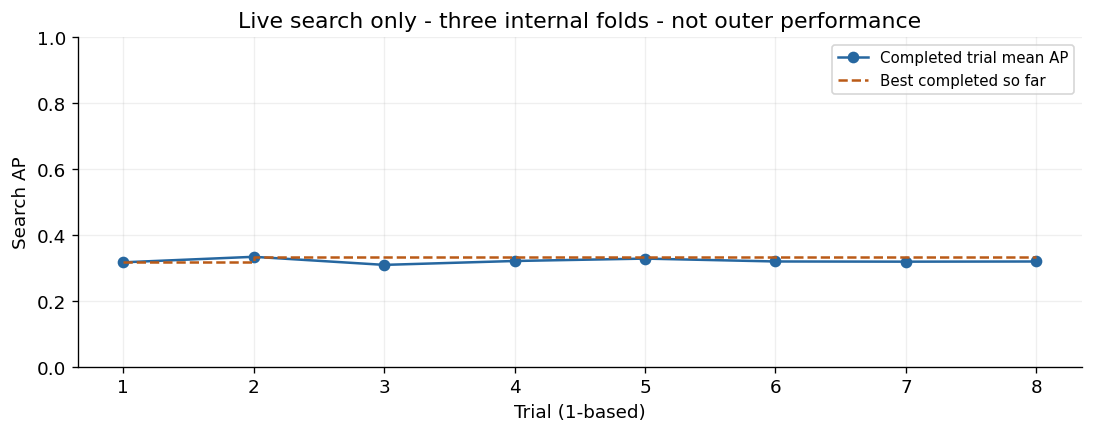

In [ ]:
search, history = tune_on_reserved_pool(search_pool, contract, config)
has_tuned = search["best_params"] is not None

summary_keys = ["status", "completed_trials", "attempted_trials", "elapsed_seconds",
                "stopping_reason", "best_tuning_ap"]
display(pd.DataFrame([{key: search[key] for key in summary_keys}]))
display(pd.DataFrame(search["fold_audits"]))
display(history)

if has_tuned:
    print("Frozen search parameters:", search["best_params"])
else:
    example = pd.read_csv(ROOT / "data/day2_optuna_example.csv")
    example_info = json.loads((ROOT / "data/day2_optuna_example.json").read_text(encoding="utf-8"))
    assert example_info["source"] == "EDUCATIONAL_EXAMPLE"
    print("EDUCATIONAL_EXAMPLE - discussion only; not your run or submission. TUNING_REQUIRED.")
    display(example)

fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
finished = history[history.state.eq("COMPLETE")]
if len(finished):
    ax.plot(finished.trial + 1, finished.mean_ap, marker="o", color="#2667A0", label="Completed trial mean AP")
    ax.step(finished.trial + 1, finished.mean_ap.cummax(), where="post", color="#BA5A17",
            linestyle="--", label="Best completed so far")
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, "No completed live trials - rerun needed", transform=ax.transAxes, ha="center")
ax.set(xlabel="Trial (1-based)", ylabel="Search AP", ylim=(0, 1), xticks=range(1, config.trials + 1),
       title="Live search only - three internal folds - not outer performance")
fig.savefig(ARTIFACTS / "day2_search.png", dpi=160)
plt.show()

## 6. Compare after freezing

Four LightGBM protocols, differing only in how the data is handled:

* **Leaky random** - keeps the two post-outcome fields (unsafe)
* **Clean random** - clean fields but mixes time and customers (unsafe)
* **Honest fixed** - forward folds, base settings, 80 trees
* **Honest tuned** - same folds, settings frozen from the search

Random runs cover 10,000 rows and forward runs 5,039, so the gaps are descriptive, not causal.

In [ ]:
controls = negative_controls(clean, raw_applications, contract, config)
fixed_report, fixed_oof, fixed_origin = evaluate_outer(
    clean, contract, folds, BASE_PARAMS, config, "clean_time_group_fixed", fixed_trees=80)

reports, prediction_parts, origins = [controls, fixed_report], [fixed_oof], list(fixed_origin)
if has_tuned:
    tuned_report, tuned_oof, tuned_origin = evaluate_outer(
        clean, contract, folds, search["best_params"], config, "clean_time_group_tuned")
    reports.append(tuned_report)
    prediction_parts.append(tuned_oof)
    origins += tuned_origin

validation_report = pd.concat(reports, ignore_index=True)
summary = summarize_folds(validation_report)
oof = pd.concat(prediction_parts, ignore_index=True)
assert not oof.duplicated(["scheme", "application_id"]).any()

display(summary.round(4))
display(validation_report[["scheme", "fold", "roc_auc", "average_precision", "train_rows",
                           "validation_rows", "selected_trees", "shared_customers",
                           "prediction_source"]].round(4))

by_scheme = summary.set_index("scheme")
gap_rows = [
    ("leaky random minus clean random", "leaky_random_control", "clean_random_control"),
    ("clean random minus honest fixed", "clean_random_control", "clean_time_group_fixed"),
    ("honest fixed minus honest reserved search", "clean_time_group_fixed", "clean_time_group_tuned"),
]
gap_table = pd.DataFrame([
    {"comparison": name,
     "ap_gap": by_scheme.loc[a, "ap_mean"] - by_scheme.loc[b, "ap_mean"],
     "roc_auc_gap": by_scheme.loc[a, "roc_auc_mean"] - by_scheme.loc[b, "roc_auc_mean"]}
    for name, a, b in gap_rows if a in by_scheme.index and b in by_scheme.index])
display(gap_table.round(4))
gap_table.to_csv(ARTIFACTS / "day2_gap_check.csv", index=False)   # extra file, not part of the ZIP

,scheme,folds,validation_rows,roc_auc_mean,roc_auc_sd,ap_mean,ap_sd
0,leaky_random_control,3,10000,0.9999,0.0002,0.9988,0.0014
1,clean_random_control,3,10000,0.8010,0.0200,0.3110,0.0293
2,clean_time_group_fixed,3,5039,0.7976,0.0206,0.3153,0.0426
3,clean_time_group_tuned,3,5039,0.7855,0.0232,0.3133,0.0259


,scheme,fold,roc_auc,average_precision,train_rows,validation_rows,selected_trees,shared_customers,prediction_source
0,leaky_random_control,1,0.9996,0.9973,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
1,clean_random_control,1,0.7807,0.2776,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
2,leaky_random_control,2,0.9999,0.9992,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
3,clean_random_control,2,0.8018,0.3232,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
4,leaky_random_control,3,1.0000,1.0000,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
5,clean_random_control,3,0.8206,0.3321,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
6,clean_time_group_fixed,1,0.7948,0.3395,3223,1632,80,0,LIVE_OUT_OF_FOLD
7,clean_time_group_fixed,2,0.8194,0.3403,4460,1674,80,0,LIVE_OUT_OF_FOLD
8,clean_time_group_fixed,3,0.7786,0.2661,5731,1733,80,0,LIVE_OUT_OF_FOLD
9,clean_time_group_tuned,1,0.7826,0.3356,3223,1632,24,0,LIVE_OUT_OF_FOLD


,comparison,ap_gap,roc_auc_gap
0,leaky random minus clean random,0.6879,0.1988
1,clean random minus honest fixed,-0.0044,0.0035
2,honest fixed minus honest reserved search,0.0020,0.0121


### Mean and spread

Each score is the mean of three folds and the bars show the sample standard deviation. The folds are neighbouring periods, so a bar is not a confidence interval. Tiny decimal differences between machines are normal. Do not rerun the search to improve an outer number.

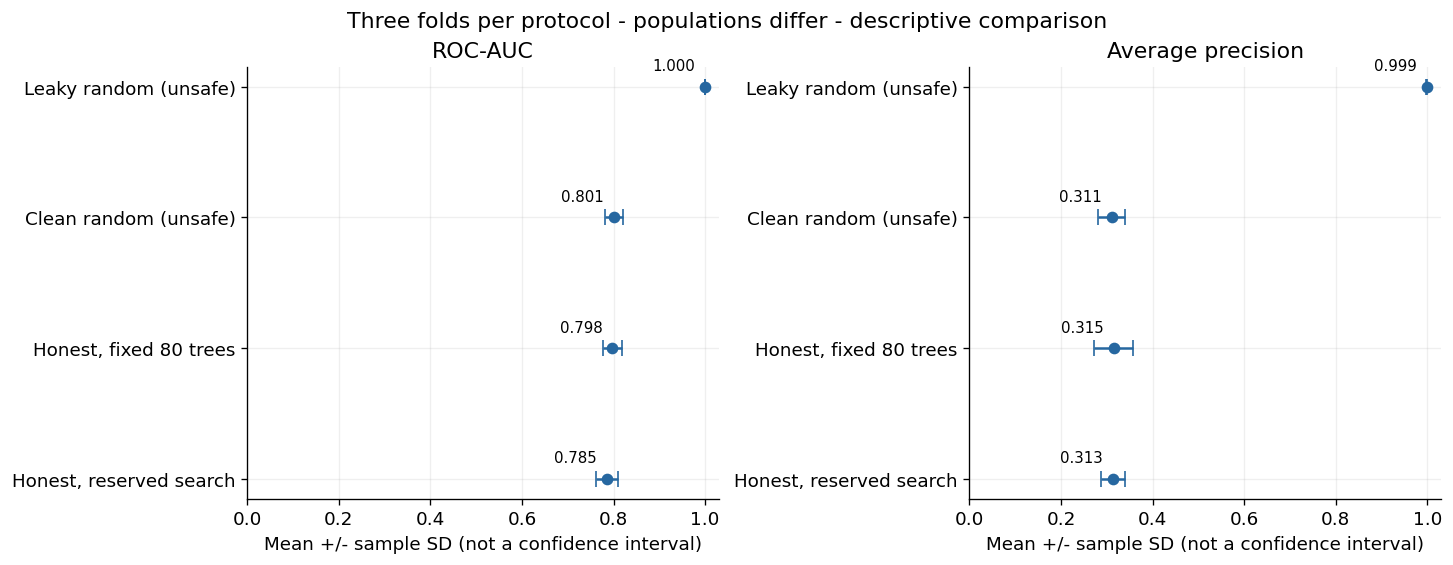

In [ ]:
names = {"leaky_random_control": "Leaky random (unsafe)", "clean_random_control": "Clean random (unsafe)",
         "clean_time_group_fixed": "Honest, fixed 80 trees", "clean_time_group_tuned": "Honest, reserved search"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
rows_idx = np.arange(len(summary))
for ax, mean_col, sd_col, title in zip(axes, ["roc_auc_mean", "ap_mean"], ["roc_auc_sd", "ap_sd"],
                                         ["ROC-AUC", "Average precision"]):
    ax.errorbar(summary[mean_col], rows_idx, xerr=summary[sd_col], fmt="o", capsize=5, color="#2667A0")
    ax.set(yticks=rows_idx, yticklabels=[names[s] for s in summary.scheme], xlim=(0, 1.03),
           xlabel="Mean +/- sample SD (not a confidence interval)", title=title)
    ax.invert_yaxis()
    for idx, value in enumerate(summary[mean_col]):
        ax.annotate(f"{value:.3f}", (value, idx), xytext=(-6, 10), textcoords="offset points",
                    ha="right", fontsize=9)
fig.suptitle("Three folds per protocol - populations differ - descriptive comparison")
fig.savefig(ARTIFACTS / "day2_validation_comparison.png", dpi=160)
plt.show()

## 7. Out-of-fold coverage

Each honest protocol gives 5,039 predictions for rows outside that fold's training data. The other 4,961 rows are warm-up and get none (coverage 50.39%). Never fill them with training predictions and never export the leaky predictions.

The last cell shows mean fold AP next to pooled AP; they are different statistics.

In [ ]:
coverage = clean[["application_id", "application_date"]].copy()
coverage["role"], coverage["fold"] = "warmup_no_oof", 0
for item in folds:
    coverage.loc[item["valid"], "role"] = "eligible_oof"
    coverage.loc[item["valid"], "fold"] = item["audit"]["fold"]

eligible_ids = set(coverage.loc[coverage.role.eq("eligible_oof"), "application_id"])
for scheme, group in oof.groupby("scheme"):
    assert set(group.application_id) == eligible_ids
    assert group.probability.between(0, 1).all()

display(pd.DataFrame([{"all_rows": len(clean), "eligible_rows": len(eligible_ids),
                       "warmup_without_oof": len(clean) - len(eligible_ids),
                       "whole_data_coverage": len(eligible_ids) / len(clean),
                       "eligible_coverage": 1.0, "live_honest_schemes": oof.scheme.nunique()}]))

from sklearn.metrics import average_precision_score
pooled = pd.DataFrame([
    {"scheme": scheme,
     "mean_fold_ap": by_scheme.loc[scheme, "ap_mean"],
     "pooled_oof_ap": average_precision_score(group[target], group.probability),
     "oof_positive_rate": group[target].mean()}
    for scheme, group in oof.groupby("scheme")])
display(pooled.round(4))

,all_rows,eligible_rows,warmup_without_oof,whole_data_coverage,eligible_coverage,live_honest_schemes
0,10000,5039,4961,0.5039,1.0,2


,scheme,mean_fold_ap,pooled_oof_ap,oof_positive_rate
0,clean_time_group_fixed,0.3153,0.3091,0.0762
1,clean_time_group_tuned,0.3133,0.3041,0.0762


## 8. Written reasoning (legacy fields)

The five `responses` fields are kept for compatibility. Today's official answer is the README question, so they stay empty and the status reads `LEARNER_WORK_REQUIRED`. The check only detects empty fields.

In [ ]:
responses = {
    "leak_example": (
        "days_past_due_60 and collection_calls are recorded only after the application, so they leak the "
        "outcome. With them a random split scored AP 0.9988 and ROC-AUC 0.9999; the clean random control "
        "without them scored AP 0.311, a drop of 0.688."),
    "split_reason": (
        "A random split lets the same customer and later periods sit on both sides, and labels that have not "
        "matured yet leak in. I used three forward folds where training labels must be 90 days mature "
        "(application date + 90 days < validation start) and removed each fold's validation customers from "
        "training (0 shared customers), so each fold looks like scoring later requests from unseen customers."),
    "observed_gap": (
        "Leaky random AP 0.9988 versus clean random 0.311 shows the leakage effect. The honest time-ordered "
        "folds gave AP 0.315 (fixed 80 trees, 5,039 rows) and 0.313 (reserved search), about the same as the "
        "clean random control (0.311), so after removing leakage the split design changed the score very little "
        "here, while the fold SD (0.043 and 0.026) shows how noisy three folds are."),
    "imputer_reason": (
        "Missing values are filled with statistics learned from the training rows of each fold only. Learning "
        "them from validation or all rows would let information about future requests flow into training and "
        "make the validation scores look better than they are."),
    "limitations": (
        "The folds are small and related: 5,039 out-of-fold rows (50.39% of the data, 4,961 warm-up rows have "
        "no prediction). Tuning ran 8 trials on a separate older cohort and did not improve on the fixed model "
        "(AP 0.313 vs 0.315). These results are a development check, not an independent final test, and they "
        "say nothing about fairness, calibration or operational value."),
}
checkpoint = reflection_check(responses)
print(checkpoint["status"])
print("Missing:", checkpoint["missing"])

READY_FOR_REVIEW
Missing: []


## 9. Export

In [ ]:
checkpoint = reflection_check(responses)
technical_status = "TECHNICAL_READY" if has_tuned else "TUNING_REQUIRED"

tables = {"validation_report.csv": validation_report, "validation_summary.csv": summary,
          "optuna_results.csv": history, "leakage_audit.csv": audit, "fold_audit.csv": fold_audit,
          "day2_oof_predictions.csv": oof, "day2_oof_coverage.csv": coverage}
for filename, table in tables.items():
    table.to_csv(ARTIFACTS / filename, index=False)

run_info = {
    "technical_status": technical_status, "learner_status": checkpoint["status"],
    "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "data_manifest_sha256": MANIFEST_SHA256,
    "dirty_data_sha256": hashlib.sha256((ROOT / "data/tamweel_dirty.csv").read_bytes()).hexdigest(),
    "config": asdict(config), "mode": "FAST" if FAST_MODE else "FULL", "python": platform.python_version(),
    "duplicates": duplicates, "removed_features": leaked_features,
    "oof_rows_per_scheme": {name: len(group) for name, group in oof.groupby("scheme")},
    "oof_whole_data_coverage": len(eligible_ids) / len(clean), "warmup_rows": len(clean) - len(eligible_ids),
    "search_source": "LIVE", "example_used_for_results": False,
    "challenge_used_for_modeling": False, "grading": "No automatic grade",
}
documents = {"best_params.json": search, "day2_provenance.json": origins,
             "day2_reflection.json": {"responses": responses, "checkpoint": checkpoint},
             "day2_run.json": run_info}
for filename, payload in documents.items():
    (ARTIFACTS / filename).write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")

bundle_files = (list(tables) + list(documents) +
                ["day2_fold_sizes.png", "day2_search.png", "day2_validation_comparison.png", "environment.json"])
with zipfile.ZipFile(ARTIFACTS / "day2_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in bundle_files:
        assert (ARTIFACTS / filename).is_file(), f"missing {filename}"
        archive.write(ARTIFACTS / filename, arcname=filename)

print(technical_status, "|", checkpoint["status"])
print(f"Saved {len(bundle_files)} files in day2_artifacts.zip. Download it and save this executed notebook.")

TECHNICAL_READY | READY_FOR_REVIEW
Saved 15 files in day2_artifacts.zip. Download it and save this executed notebook.


# Day 3 · A review threshold you can defend

A model gives scores, but a review team needs a rule: *flag this request or not*. Today we compare three ways of handling the rare default class, then pick a threshold using a teaching loss (`10 x FN + FP`) and a review capacity of 12% of requests per validation period.

## 1. Setup

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise

    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

DAY2_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
DAY2_SHA256 = "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"
fetch_verified(f"{RAW_BASE}/{DAY2_REVISION}/scripts/day2_validation.py",
               ROOT / "scripts/day2_validation.py", DAY2_SHA256)

LAB_REVISION = "c2dc52e129878d0d487db1874891c658de7c4d0d"
SUPPORT_HASHES = {
    "scripts/day3_decision.py": "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12",
    "data/day3_oof_example.csv": "659952bef85ac3b7ceb7ab84eb2102de6c9b433a1ba122cd57df96581baf0eb3",
    "data/day3_oof_example.json": "920cf9830043afcc83f8c276c8945677296eb3c49a6e69326d47f6080a9e7fad",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 3 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 3 setup verified


## 2. Fix the policy before looking at results

The target is a default within 90 days of applying. Two rules are frozen up front: a missed default (FN) costs 10 teaching units and a false alarm (FP) costs 1, and no validation period may flag more than 12% of its requests. Folds are the same later-period folds as Day 2, so training only sees mature labels from other customers.

In [ ]:
import json
import os
import platform
import zipfile
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from data_checks import validate_frame
from day2_validation import deduplicate_applications, make_time_group_split
from day3_decision import (
    STRATEGIES, TARGET, CostPolicy, DecisionConfig, TrainingBudgetExpired,
    flag_at, generate_oof, load_example, period_audit, reflection_check,
    region_audit, select_threshold, threshold_sweep, validate_oof
)

contract = json.loads(
    (ROOT / "data/data_contract.json").read_text(encoding="utf-8")
)

train, duplicates = deduplicate_applications(
    pd.read_csv(ROOT / "data/tamweel_train.csv")
)

validate_frame(train, contract, "train")

config = DecisionConfig(trees=80 if FAST_MODE else 160)
policy = CostPolicy(**contract["decision_policy"])

STRATEGY_FOR_DECISION = "weighted"
USE_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"

assert STRATEGY_FOR_DECISION in STRATEGIES

ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

folds = make_time_group_split(
    train,
    horizon_days=contract["target"]["horizon_days"]
)

summary = pd.DataFrame([{
    "training_rows": len(train),
    "positive_rate": train[TARGET].mean(),
    "FN_units": policy.false_negative_cost,
    "FP_units": policy.false_positive_cost,
    "capacity_per_period": policy.max_flag_fraction,
    "trees_per_model": config.trees
}])

display(summary)

fold_audit = pd.DataFrame([
    fold["audit"] for fold in folds
])

display(fold_audit)

,training_rows,positive_rate,FN_units,FP_units,capacity_per_period,trees_per_model
0,10000,0.0789,10,1,0.12,80


,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
0,1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30
1,2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31
2,3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30


## 3. Change only the training, never the validation

Three LightGBM strategies share the same features, folds, tree budget and seed. They differ only in how the rare default class is treated during training: **unweighted**, **class-weighted**, **oversampled**. Validation rows are never reweighted or resampled.

In [ ]:
fallback_reason = None

if not USE_EXAMPLE:
    try:
        oof, model_report, provenance = generate_oof(train, contract, config)
    except TrainingBudgetExpired as exc:
        if ASSESSMENT_MODE:
            raise
        USE_EXAMPLE, fallback_reason = True, str(exc)

if USE_EXAMPLE:
    oof, example_info = load_example(
        ROOT / "data/day3_oof_example.csv",
        ROOT / "data/day3_oof_example.json",
        train,
        folds,
        assessment_mode=ASSESSMENT_MODE
    )

    model_report = pd.DataFrame(example_info["model_report"])

    provenance = {
        "source": "EDUCATIONAL_EXAMPLE",
        "example_metadata": example_info,
        "fallback_reason": fallback_reason or "Learner selected discussion example"
    }

SOURCE = oof.source.iloc[0]

effective_config = example_info["config"] if USE_EXAMPLE else asdict(config)

coverage = validate_oof(oof, train, folds)

print(
    "LIVE: your own CPU run"
    if SOURCE == "LIVE"
    else "EDUCATIONAL_EXAMPLE: discussion only, not submittable"
)

display(pd.DataFrame([coverage]))

display(
    model_report[
        [
            "strategy",
            "fold",
            "original_training_rows",
            "fitted_rows",
            "scale_pos_weight",
            "training_positive_rate",
            "fitted_positive_rate",
            "average_precision",
            "train_seconds",
            "source"
        ]
    ]
)

decision_oof = oof[oof.strategy.eq(STRATEGY_FOR_DECISION)].copy()

assert decision_oof.application_id.is_unique

print(f"Strategy declared before the comparison: {STRATEGY_FOR_DECISION}")

LIVE: your own CPU run


,eligible_rows,all_rows,whole_data_coverage,eligible_coverage,warmup_without_oof,source
0,5039,10000,0.5039,1.0,4961,LIVE


,strategy,fold,original_training_rows,fitted_rows,scale_pos_weight,training_positive_rate,fitted_positive_rate,average_precision,train_seconds,source
0,unweighted,1,3223,3223,1.000000,0.085014,0.085014,0.339545,0.799043,LIVE
1,weighted,1,3223,3223,10.762774,0.085014,0.085014,0.337822,1.061185,LIVE
2,oversampled,1,3223,5898,1.000000,0.085014,0.500000,0.350190,3.202489,LIVE
3,unweighted,2,4460,4460,1.000000,0.079148,0.079148,0.340341,0.620698,LIVE
4,weighted,2,4460,4460,11.634561,0.079148,0.079148,0.329487,0.285441,LIVE
5,oversampled,2,4460,8214,1.000000,0.079148,0.500000,0.338989,0.537344,LIVE
6,unweighted,3,5731,5731,1.000000,0.081138,0.081138,0.266130,0.307949,LIVE
7,weighted,3,5731,5731,11.324731,0.081138,0.081138,0.270736,0.808731,LIVE
8,oversampled,3,5731,10532,1.000000,0.081138,0.500000,0.277600,0.527536,LIVE


Strategy declared before the comparison: weighted


## 4. Accuracy can hide a failure

Every strategy scores the same 5,039 later requests (4,961 warm-up rows have no out-of-fold prediction). With only about 8% defaults, a model that flags almost nobody still looks accurate. So we read accuracy next to recall, precision, flag counts and loss at the default 0.5 threshold, and compare against "flag nobody".

,strategy,rows,positive_rate,pooled_roc_auc,pooled_ap,accuracy_at_0_5,recall_at_0_5,precision_at_0_5,flags_at_0_5,loss_at_0_5,capacity_ok_at_0_5,source
0,unweighted,5039,0.076206,0.797872,0.309060,0.925580,0.125000,0.551724,87,3399,True,LIVE
1,weighted,5039,0.076206,0.796892,0.310038,0.812463,0.578125,0.220896,1005,2403,False,LIVE
2,oversampled,5039,0.076206,0.797914,0.315902,0.807303,0.598958,0.219675,1047,2357,False,LIVE


,rule,rows,accuracy,recall,precision,loss_units
0,Flag nobody,5039,0.923794,0.0,None,3840


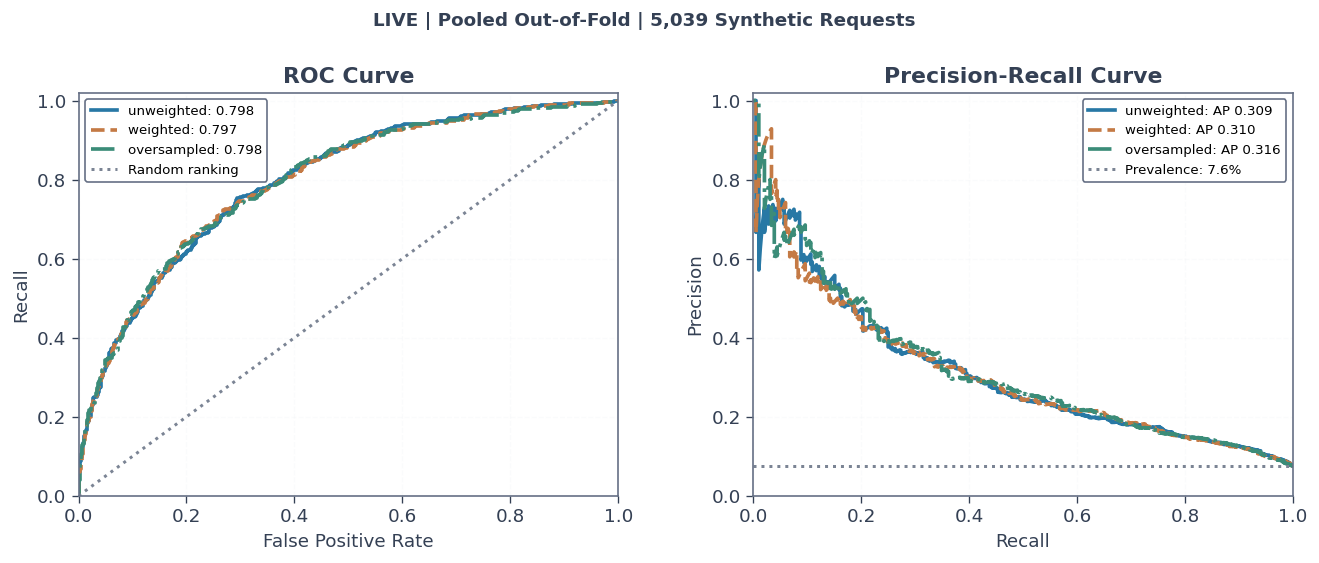

In [ ]:
summary_rows = []

for strategy, part in oof.groupby("strategy", sort=False):
    at_half = threshold_sweep(part, policy).query("threshold == 0.5").iloc[0]

    summary_rows.append({
        "strategy": strategy,
        "rows": len(part),
        "positive_rate": part[TARGET].mean(),
        "pooled_roc_auc": roc_auc_score(part[TARGET], part.probability),
        "pooled_ap": average_precision_score(part[TARGET], part.probability),
        "accuracy_at_0_5": at_half.accuracy,
        "recall_at_0_5": at_half.recall,
        "precision_at_0_5": at_half.precision,
        "flags_at_0_5": at_half.flagged,
        "loss_at_0_5": at_half.loss_units,
        "capacity_ok_at_0_5": at_half.capacity_feasible,
        "source": SOURCE
    })

strategy_table = pd.DataFrame(summary_rows)

display(strategy_table)

flag_nobody = {
    "rule": "Flag nobody",
    "rows": len(decision_oof),
    "accuracy": 1 - decision_oof[TARGET].mean(),
    "recall": 0.0,
    "precision": None,
    "loss_units": int(decision_oof[TARGET].sum()) * policy.false_negative_cost
}

display(pd.DataFrame([flag_nobody]))

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.2
})

palette = {
    "unweighted": "#2878A5",
    "weighted": "#C47A45",
    "oversampled": "#3B8C78"
}

fig, (ax_roc, ax_pr) = plt.subplots(
    1, 2,
    figsize=(11.5, 4.8),
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    top=0.84,
    bottom=0.14,
    wspace=0.25
)

for strategy, dash in zip(STRATEGIES, ["-", "--", "-."]):
    part = oof[oof.strategy.eq(strategy)]

    fpr, tpr, _ = roc_curve(
        part[TARGET],
        part.probability
    )

    prec, rec, _ = precision_recall_curve(
        part[TARGET],
        part.probability
    )

    stats = strategy_table.set_index("strategy").loc[strategy]

    ax_roc.plot(
        fpr,
        tpr,
        color=palette[strategy],
        linestyle=dash,
        linewidth=2.2,
        label=f"{strategy}: {stats.pooled_roc_auc:.3f}"
    )

    ax_pr.plot(
        rec,
        prec,
        color=palette[strategy],
        linestyle=dash,
        linewidth=2.2,
        label=f"{strategy}: AP {stats.pooled_ap:.3f}"
    )

ax_roc.plot(
    [0, 1], [0, 1],
    color="#7B8494",
    linestyle=":",
    linewidth=1.8,
    label="Random ranking"
)

ax_pr.axhline(
    decision_oof[TARGET].mean(),
    color="#7B8494",
    linestyle=":",
    linewidth=1.8,
    label=f"Prevalence: {decision_oof[TARGET].mean():.1%}"
)

ax_roc.set(
    title="ROC Curve",
    xlabel="False Positive Rate",
    ylabel="Recall",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

ax_pr.set(
    title="Precision-Recall Curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.02)
)

for ax in (ax_roc, ax_pr):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#667085")
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color="#E8EDF2",
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors="#344054",
        width=0.8,
        length=4
    )

    ax.title.set_color("#344054")
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color("#344054")
    ax.yaxis.label.set_color("#344054")

    ax.legend(
        loc="best",
        fontsize=8,
        frameon=True,
        facecolor="white",
        edgecolor="#667085",
        framealpha=1
    )

fig.suptitle(
    f"{SOURCE} | Pooled Out-of-Fold | "
    f"{len(decision_oof):,} Synthetic Requests",
    fontsize=11,
    fontweight="bold",
    color="#344054"
)

fig.savefig(
    ARTIFACTS / "day3_roc_pr.png",
    dpi=180,
    bbox_inches=None,
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 5. Sweep every distinct decision rule

A request is flagged when `score >= threshold`. The sweep tries every distinct score as a threshold and records TP, FP, FN, TN, recall, precision, the loss, and the flag share per period. We then read three rules side by side: the default 0.5, the minimum loss with no capacity limit, and the minimum loss that keeps **every** period within 12%.

,rule,threshold,tp,fp,fn,tn,recall,precision,flagged,flag_fraction,loss_units,loss_units_per_10000,capacity_feasible
0,Default 0.5,0.5000,222,783,162,3872,0.5781,0.2209,1005,0.1994,2403,4768.8033,False
1,"Minimum loss, no capacity limit",0.4486,246,895,138,3760,0.6406,0.2156,1141,0.2264,2275,4514.7847,False
2,"Minimum loss, every-period capacity",0.6583,157,369,227,4286,0.4089,0.2985,526,0.1044,2639,5237.1502,True


Capped minus default loss: +236 teaching units. 0.5 feasible: False
Exact rule to keep in the JSON: 0.6583471436014694 with >=


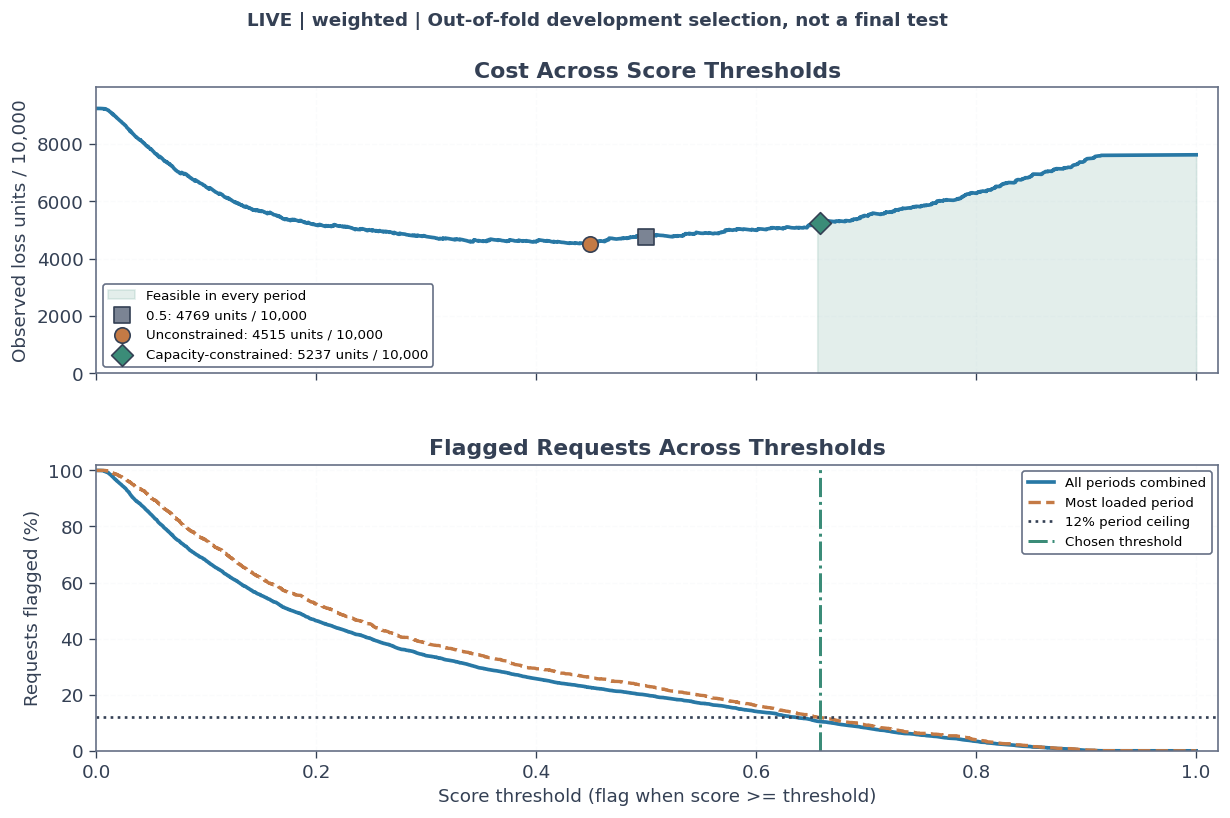

In [ ]:
sweep = threshold_sweep(decision_oof, policy)
free_pt = select_threshold(sweep, constrained=False)
capped_pt = select_threshold(sweep, constrained=True)
default_pt = sweep.loc[sweep.threshold.eq(0.5)].iloc[0].to_dict()

operating_points = pd.DataFrame([
    {**point, "rule": label} for label, point in [
        ("Default 0.5", default_pt),
        ("Minimum loss, no capacity limit", free_pt),
        ("Minimum loss, every-period capacity", capped_pt)
    ]
])

display(
    operating_points[[
        "rule", "threshold", "tp", "fp", "fn", "tn", "recall", "precision",
        "flagged", "flag_fraction", "loss_units", "loss_units_per_10000",
        "capacity_feasible"
    ]].round(4)
)

assert free_pt["loss_units"] <= default_pt["loss_units"]

if default_pt["capacity_feasible"]:
    assert capped_pt["loss_units"] <= default_pt["loss_units"]

period_table = period_audit(
    decision_oof, capped_pt["threshold"], policy
)
assert period_table.within_capacity.all()

loss_delta = capped_pt["loss_units"] - default_pt["loss_units"]

print(
    f"Capped minus default loss: {loss_delta:+.0f} teaching units. "
    f"0.5 feasible: {default_pt['capacity_feasible']}"
)
print(
    "Exact rule to keep in the JSON:",
    repr(capped_pt["threshold"]), "with >="
)

COLORS = {
    "main": "#2878A5",
    "feasible": "#3B8C78",
    "unconstrained": "#C47A45",
    "default": "#7B8494",
    "capacity": "#344054",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_loss, ax_flags) = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True,
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.89,
    bottom=0.10,
    hspace=0.32
)

ax_loss.plot(
    sweep.threshold,
    sweep.loss_units_per_10000,
    color=COLORS["main"],
    linewidth=2.2
)

ax_loss.fill_between(
    sweep.threshold,
    0,
    sweep.loss_units_per_10000,
    where=sweep.capacity_feasible,
    color=COLORS["feasible"],
    alpha=0.14,
    label="Feasible in every period"
)

operating_markers = [
    ("0.5", default_pt, "s", COLORS["default"]),
    ("Unconstrained", free_pt, "o", COLORS["unconstrained"]),
    ("Capacity-constrained", capped_pt, "D", COLORS["feasible"])
]

for label, point, marker, color in operating_markers:
    ax_loss.scatter(
        point["threshold"],
        point["loss_units_per_10000"],
        marker=marker,
        s=85,
        color=color,
        edgecolor=COLORS["edge"],
        linewidth=1.0,
        zorder=5,
        label=f"{label}: {point['loss_units_per_10000']:.0f} units / 10,000"
    )

ax_loss.set(
    ylabel="Observed loss units / 10,000",
    title="Cost Across Score Thresholds"
)

ax_loss.set_xlim(0, 1.02)

loss_max = sweep.loss_units_per_10000.max()
ax_loss.set_ylim(0, max(1, loss_max * 1.08))

ax_loss.legend(
    loc="best",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    framealpha=1
)

ax_flags.plot(
    sweep.threshold,
    sweep.flag_fraction * 100,
    color=COLORS["main"],
    linewidth=2.2,
    label="All periods combined"
)

ax_flags.plot(
    sweep.threshold,
    sweep.max_period_flag_fraction * 100,
    color=COLORS["unconstrained"],
    linewidth=2.0,
    linestyle="--",
    label="Most loaded period"
)

ax_flags.axhline(
    policy.max_flag_fraction * 100,
    color=COLORS["capacity"],
    linewidth=1.6,
    linestyle=":",
    label="12% period ceiling"
)

ax_flags.axvline(
    capped_pt["threshold"],
    color=COLORS["feasible"],
    linewidth=1.8,
    linestyle="-.",
    label="Chosen threshold"
)

ax_flags.set(
    xlabel="Score threshold (flag when score >= threshold)",
    ylabel="Requests flagged (%)",
    title="Flagged Requests Across Thresholds"
)

ax_flags.set_xlim(0, 1.02)
ax_flags.set_ylim(0, 102)

ax_flags.legend(
    loc="best",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    framealpha=1
)

for ax in (ax_loss, ax_flags):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"{SOURCE} | {STRATEGY_FOR_DECISION} | "
    "Out-of-fold development selection, not a final test",
    fontsize=11,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "cost_curve.png",
    dpi=180,
    bbox_inches=None,
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 6. Check every period and test the policy's sensitivity

The per-period table is the binding capacity evidence; one pooled rate is not enough. The sensitivity table repeats the choice with the miss cost at 8, 10 and 12 units. The textbook threshold 1/11 (about 0.0909) needs calibrated probabilities and no capacity limit, so it is **not** imposed on today's class-weighted raw scores.

In [ ]:
display(period_table)

scenario_rows = []
for miss_cost in [8.0, 10.0, 12.0]:
    alt_policy = replace(policy, false_negative_cost=miss_cost)
    alt = select_threshold(threshold_sweep(decision_oof, alt_policy))
    scenario_rows.append({
        "FN_loss_units": miss_cost, "FP_loss_units": policy.false_positive_cost,
        "capacity_fraction": policy.max_flag_fraction, "threshold": alt["threshold"],
        "flagged": alt["flagged"], "recall": alt["recall"], "loss_units": alt["loss_units"],
        "capacity_feasible": alt["capacity_feasible"], "source": SOURCE})
sensitivity = pd.DataFrame(scenario_rows)

display(sensitivity.round(4))

print("Capacity, not the cost ratio, is what pins the threshold here: the three scenarios share one cut-off.")

,fold,rows,capacity,flagged,flag_fraction,within_capacity,source
0,1,1632,195,137,0.083946,True,LIVE
1,2,1674,200,183,0.109319,True,LIVE
2,3,1733,207,206,0.118869,True,LIVE


,FN_loss_units,FP_loss_units,capacity_fraction,threshold,flagged,recall,loss_units,capacity_feasible,source
0,8.0,1,0.12,0.6583,526,0.4089,2185.0,True,LIVE
1,10.0,1,0.12,0.6583,526,0.4089,2639.0,True,LIVE
2,12.0,1,0.12,0.6583,526,0.4089,3093.0,True,LIVE


Capacity, not the cost ratio, is what pins the threshold here: the three scenarios share one cut-off.


## 7. Compare regions, descriptively

With one shared threshold frozen, each synthetic region's false-positive rate is `FP / (FP + TN)`. Gaps are descriptive only: no confidence interval, no fairness certificate.

,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,1184,1088,96,131,88,43,0.0809,0.4479,False,LIVE
1,western,1262,1158,104,132,96,36,0.0829,0.3462,False,LIVE
2,eastern,1295,1192,103,131,92,39,0.0772,0.3786,False,LIVE
3,other,1298,1217,81,132,93,39,0.0764,0.4815,False,LIVE


False-positive-rate gap (percentage points): 0.6484134519182061


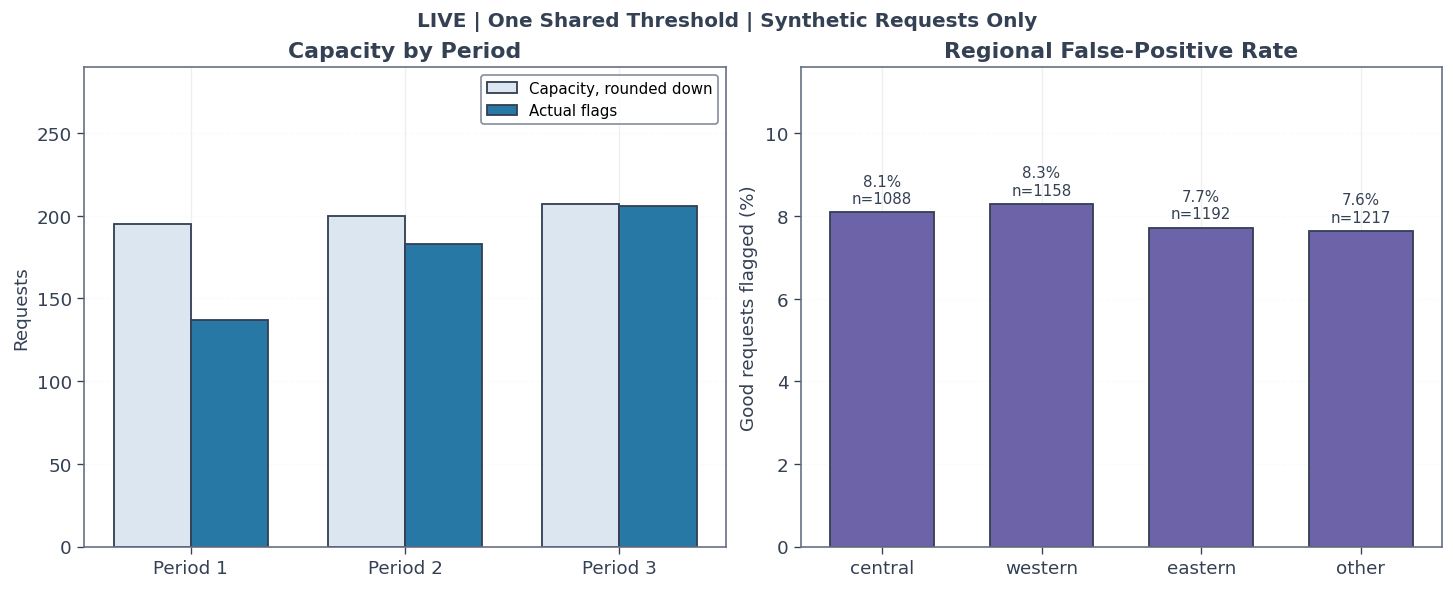

In [ ]:
region_table, gap_info = region_audit(
    decision_oof,
    capped_pt["threshold"]
)

display(region_table.round(4))

print(
    "False-positive-rate gap (percentage points):",
    gap_info["fpr_gap_percentage_points"]
)

COLORS = {
    "capacity": "#DCE6F1",
    "flagged": "#2878A5",
    "regional": "#6C63A8",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_cap, ax_reg) = plt.subplots(
    1, 2,
    figsize=(12, 4.8),
    constrained_layout=True
)

pos = np.arange(len(period_table))

ax_cap.bar(
    pos - 0.18,
    period_table.capacity,
    0.36,
    color=COLORS["capacity"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    label="Capacity, rounded down"
)

ax_cap.bar(
    pos + 0.18,
    period_table.flagged,
    0.36,
    color=COLORS["flagged"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    label="Actual flags"
)

ax_cap.set(
    xticks=pos,
    xticklabels=[f"Period {n}" for n in period_table.fold],
    ylabel="Requests",
    title="Capacity by Period"
)

ax_cap.set_ylim(
    0,
    period_table.capacity.max() * 1.4
)

ax_cap.legend(
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"],
    fontsize=9
)

regional_values = (
    region_table.false_positive_rate * 100
)

ax_reg.bar(
    region_table.region,
    regional_values,
    color=COLORS["regional"],
    edgecolor=COLORS["edge"],
    linewidth=1.1,
    width=0.65
)

ax_reg.set(
    ylabel="Good requests flagged (%)",
    title="Regional False-Positive Rate"
)

for i, row in enumerate(region_table.itertuples()):
    if pd.notna(row.false_positive_rate):
        ax_reg.text(
            i,
            row.false_positive_rate * 100 + 0.15,
            f"{row.false_positive_rate:.1%}\nn={row.negatives}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=COLORS["text"]
        )

ax_reg.set_ylim(
    0,
    max(10, regional_values.max() * 1.4)
)

for ax in (ax_cap, ax_reg):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )
    ax.set_axisbelow(True)
    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")

    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"{SOURCE} | One Shared Threshold | Synthetic Requests Only",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "day3_capacity_regions.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 8. Reasoning

In [ ]:
responses = {
    "threshold_reason": (
        "I chose 0.6583 because it is the lowest-loss threshold at which every validation period stays within "
        "the 12% review capacity. It flags 526 of 5,039 requests (10.4%; the busiest period is 11.9%) with "
        "recall 40.9% and precision 29.9%. The policy (FN = 10 units, FP = 1 unit, 12% per period) was fixed "
        "before I looked at any result."),
    "cost_capacity_tradeoff": (
        "The cheapest rule without a capacity limit is 0.4486 with 2,275 units, but it flags 22.6% of requests "
        "and breaks capacity (busiest period 26.3%). The default 0.5 costs 2,403 units and also breaks capacity "
        "(19.9% flagged, busiest period 23.2%). The capacity-safe 0.6583 costs 2,639 units, which is 236 units "
        "more than 0.5, so staying within the review team's limit costs about 9.8% extra teaching loss and "
        "catches fewer defaults (227 missed instead of 162)."),
    "regional_gap": (
        "False-positive rates are 8.09% (central), 8.29% (western), 7.72% (eastern) and 7.64% (other), a gap of "
        "0.65 percentage points on 1,088 to 1,217 good requests per region. Recall differs more, from 34.6% "
        "(western) to 48.2% (other), and the groups are small. This is descriptive: it has no confidence "
        "interval and is not a fairness check, so the regional recall difference deserves a closer look."),
    "limitations": (
        "The threshold and its loss are estimated on the same out-of-fold outcomes, so this is development "
        "selection and not a final test. The out-of-fold data covers 50.39% of the training rows (4,961 warm-up "
        "rows have no prediction). Class weights make the scores uncalibrated, so the textbook threshold of "
        "1/11 does not apply. The loss matrix is a simplified teaching policy in units, not money, and one "
        "flag means 'send to review', not a rejection."),
    "why_accuracy_misleads": (
        "Only 7.6% of requests are defaults, so flagging nobody already gives 92.4% accuracy while catching "
        "no default at all (loss 3,840 units). At 0.5 the weighted model has lower accuracy (81.3%) but much "
        "better recall (57.8%), and the unweighted model has the highest accuracy (92.6%) with only 12.5% "
        "recall. Accuracy hides which kind of error is being made, so I read recall, precision and the loss "
        "next to it."),
    "why_oof": (
        "Training predictions are scored on rows the model has already seen, so they are too optimistic. "
        "Out-of-fold predictions come from models that never saw those rows, from later periods, and with "
        "validation customers removed from training, so they imitate new requests. The challenge data must stay "
        "untouched for the final check and cannot be used to pick a threshold."),
}
checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| missing:", checkpoint["missing"])

READY_FOR_REVIEW | missing: []


## 9. Export the evidence

In [ ]:
NL = chr(10)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


checkpoint = reflection_check(responses, SOURCE)
status = "TECHNICAL_READY" if SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
pooled_ap = float(average_precision_score(decision_oof[TARGET], decision_oof.probability))

threshold_metrics = {
    "source": SOURCE, "technical_status": status, "strategy": STRATEGY_FOR_DECISION,
    "policy": asdict(policy), "unit": "educational_loss_unit", "comparison_operator": ">=",
    "capacity_scope": "every validation period; floor(fraction * period_rows)",
    "chosen": capped_pt, "unconstrained": free_pt, "default_0_5": default_pt,
    "loss_change_vs_default": loss_delta, "pooled_oof_ap": pooled_ap, "regional_audit": gap_info,
    "coverage": coverage, "selection_status": "OOF development selection; not an independent final test"}

membership = train[["application_id", "application_date"]].copy()
membership["role"], membership["fold"] = "warmup_no_oof", 0
for fold in folds:
    membership.loc[fold["valid"], "role"] = "eligible_oof"
    membership.loc[fold["valid"], "fold"] = fold["audit"]["fold"]
membership["source"] = SOURCE

review_flags = decision_oof.copy()
review_flags["review_flag"] = flag_at(decision_oof.probability, capped_pt["threshold"]).astype(int)

tables = {
    "day3_model_report.csv": model_report, "day3_model_comparison.csv": strategy_table,
    "day3_oof_predictions.csv": oof, "day3_oof_coverage.csv": membership,
    "threshold_sweep.csv": sweep, "day3_period_capacity.csv": period_table,
    "day3_region_audit.csv": region_table, "day3_cost_sensitivity.csv": sensitivity,
    "day3_review_flags.csv": review_flags}
for name, frame in tables.items():
    frame.to_csv(ARTIFACTS / name, index=False)

run_info = {
    "technical_status": status, "learner_status": checkpoint["status"], "source": SOURCE,
    "requested_config": asdict(config), "effective_config": effective_config,
    "assessment_mode": ASSESSMENT_MODE, "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION,
    "support_sha256": SUPPORT_HASHES, "day2_revision": DAY2_REVISION, "day2_sha256": DAY2_SHA256,
    "manifest_sha256": MANIFEST_SHA256,
    "training_data_sha256": hashlib.sha256((ROOT / "data/tamweel_train.csv").read_bytes()).hexdigest(),
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
    "coverage": coverage, "challenge_used_for_modeling": False, "no_automatic_grade": True}
if IN_COLAB:
    import resource
    run_info["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)

json_files = {
    "threshold_metrics.json": threshold_metrics, "day3_provenance.json": provenance,
    "day3_reflection.json": {"source": SOURCE, "responses": responses, "checkpoint": checkpoint},
    "day3_run.json": run_info}
for name, payload in json_files.items():
    (ARTIFACTS / name).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False),
                                  encoding="utf-8")

pct = lambda v: f"{v:.2%}" if pd.notna(v) else "undefined (no denominator)"
card_state = ("Teaching example, not submittable as your own run" if SOURCE != "LIVE"
              else "Ready for review; this is not an approval or a grade")
capacity_line = ", ".join(f"period {int(r.fold)}: {int(r.flagged)}/{int(r.capacity)}"
                          for r in period_table.itertuples())
card = f"""# Decision card | Tamweel Lite

**Status:** {card_state}
**Source:** {SOURCE} | **Strategy:** {STRATEGY_FOR_DECISION} | **Rows:** {len(decision_oof):,} out-of-fold requests

**Task.** `default_within_90d = 1` is a synthetic default within 90 days of the application. Each fold validates on later requests, removes their customers from training and uses only matured labels.

| Evidence | Value |
|---|---:|
| Capacity-constrained threshold (full precision) | {capped_pt['threshold']!r} |
| Unconstrained minimum-loss threshold | {free_pt['threshold']!r} |
| Recall | {pct(capped_pt['recall'])} |
| Precision | {pct(capped_pt['precision'])} |
| Pooled out-of-fold AP | {pooled_ap:.4f} |
| Flags | {capped_pt['flagged']:,} of {len(decision_oof):,} |
| FN / FP | {capped_pt['fn']} / {capped_pt['fp']} |
| Teaching loss | {capped_pt['loss_units']:.0f} units |
| Loss at 0.5 | {default_pt['loss_units']:.0f} units; within capacity: {default_pt['capacity_feasible']} |
| Change versus 0.5 | {loss_delta:+.0f} units (positive = more loss) |
| False-positive-rate gap between regions | {gap_info['fpr_gap_percentage_points']:.3f} percentage points |

**Rule.** Score >= {capped_pt['threshold']!r} means "send to review" inside this exercise. It is not an approval or a rejection. Keep the full precision: rounding the threshold can change the queue size.

**Policy.** FN = {policy.false_negative_cost:g} and FP = {policy.false_positive_cost:g} teaching units; capacity {policy.max_flag_fraction:.0%} per period, rounded down. These are not riyals, tool fees or grade deductions.

**Capacity evidence.** {capacity_line}.

**Limits.** Out-of-fold predictions cover {coverage['whole_data_coverage']:.2%} of the training data ({coverage['warmup_without_oof']:,} warm-up rows have no prediction). The threshold and its loss are estimated on the same out-of-fold outcomes, so this is a development result, not a final test. The challenge file was not used. Regional comparisons are descriptive and are not a fairness certificate; class weights do not make scores calibrated.

Evidence files: `artifacts/threshold_metrics.json`, `day3_period_capacity.csv`, `day3_region_audit.csv`, `day3_cost_sensitivity.csv`, `cost_curve.png`. Sensitivity rows are +/-20% scenarios for the miss cost, not confidence intervals.
"""
(REPORTS / "DECISION_CARD.md").write_text(card, encoding="utf-8")

figures = ["cost_curve.png", "day3_roc_pr.png", "day3_capacity_regions.png"]
bundle_files = list(tables) + list(json_files) + figures + ["environment.json"]
with zipfile.ZipFile(ARTIFACTS / "day3_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in bundle_files:
        bundle.write(ARTIFACTS / name, "artifacts/" + name)
    bundle.write(REPORTS / "DECISION_CARD.md", "reports/DECISION_CARD.md")
print(f"{status} | {checkpoint['status']} | {SOURCE} | {run_info['elapsed_seconds']} seconds | CPU")
print(f"Saved {len(bundle_files) + 1} files in day3_artifacts.zip")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | 12.56 seconds | CPU
Saved 18 files in day3_artifacts.zip


# Day 4 · Explain the model and test its probabilities

Two different questions: *which features did the model lean on?* (explanation) and *can its probabilities be taken at face value?* (calibration). We separate the data into roles (fit, calibration, policy, evaluation), explain a class-weighted LightGBM with permutation importance and SHAP, fit a sigmoid calibrator on its own period, and test whether a review zone fits the 12% capacity.

## 1. Setup

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7",
                                   "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d",
                                 "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"{RAW_BASE}/{revision}/{relative}", ROOT / relative, digest)

LAB_REVISION = "4f6892d5c02923b5f8e3c78f4fcead73b043570f"
SUPPORT_HASHES = {
    "scripts/day4_trust.py": "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c",
    "data/day4_shap_example.npz": "de6eefb4f0b1dfd54d4a71e2b73cf8383cea6386e661f8af8662d478cd957e2b",
    "data/day4_shap_example.json": "8169c70dc327a7ffdff748c365d71544fe951f3b196974e33f09dccb580a8122",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 4 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 4 setup verified


## 2. Separate fit, calibration, policy and evaluation

The target is a default within 90 days of applying. Each role gets its own period and its own customers: the model is **fit** on the oldest rows, the sigmoid is learned on the **calibration** rows, the review threshold is chosen on the **policy** rows, and everything is scored once on the **evaluation** rows. Gap periods and customer overlaps are excluded. Nothing is retuned after the evaluation numbers appear.

In [ ]:
import json
import os
import platform
import zipfile
from dataclasses import asdict

import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit

from data_checks import validate_frame
from day2_validation import deduplicate_applications
from day4_trust import (
    ROLES, TARGET, ShapBudgetExpired, TrustConfig, choose_policy_threshold,
    cluster_bootstrap, explain_sample, fit_and_calibrate, load_shap_example,
    local_stability, map_probability, permutation_report, probability_metrics,
    reason_codes, reflection_check, reliability_table, review_audit, split_roles,
    transport_threshold
)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")

config = TrustConfig() if FAST_MODE else TrustConfig(
    trees=160,
    shap_rows=600,
    permutation_repeats=5,
    bootstrap_repeats=500
)

USE_SHAP_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (11, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#667085",
    "axes.linewidth": 1.1,
    "axes.labelcolor": "#344054",
    "axes.titlecolor": "#344054",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "xtick.color": "#667085",
    "ytick.color": "#667085",
    "grid.color": "#E8EDF2",
    "grid.linewidth": 0.8,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "savefig.facecolor": "white"
})

parts, assignments = split_roles(train)

role_summary = pd.DataFrame([{
    "role": name,
    "rows": len(frame),
    "customers": frame.customer_id.nunique(),
    "positives": int(frame[TARGET].sum()),
    "positive_rate": frame[TARGET].mean(),
    "first_date": pd.to_datetime(frame.application_date.min()).strftime("%Y-%m-%d"),
    "last_date": pd.to_datetime(frame.application_date.max()).strftime("%Y-%m-%d")
} for name, frame in parts.items()])

display(role_summary)

print(
    "Excluded gap / customer-overlap rows:",
    int((assignments.role == "excluded_gap_or_customer").sum())
)

model, calibrated_model, predictions, provenance = fit_and_calibrate(
    parts, contract, config
)

evaluation = predictions[predictions.role == "evaluation"].copy()
policy_rows = predictions[predictions.role == "policy"].copy()

chosen_policy, policy_sweep = choose_policy_threshold(policy_rows)
mapping = provenance["calibration_mapping"]
calibrated_threshold = transport_threshold(
    chosen_policy["threshold"], mapping
)

print("Model, sigmoid and policy threshold are frozen before the evaluation role is read.")

,role,rows,customers,positives,positive_rate,first_date,last_date
0,fit,2516,1853,217,0.086248,2022-01-01,2023-04-01
1,calibration,584,538,40,0.068493,2023-07-01,2023-09-30
2,policy,589,566,55,0.093379,2024-01-01,2024-03-31
3,evaluation,1733,1520,139,0.080208,2024-07-01,2024-12-31


Excluded gap / customer-overlap rows: 4578
Model, sigmoid and policy threshold are frozen before the evaluation role is read.


## 3. Permutation importance on held-out data

Shuffle one feature (or one group of related features) in the evaluation rows and measure how much **Average Precision** falls. A big drop means the model relies on it on those rows. Features that share signal can split the credit, so read it as dependence, not as cause.

,feature_group,mean_ap_drop,repeat_sd,training_gain
0,bureau_score,0.1270,0.0235,8922.6701
1,dti,0.0690,0.0200,6423.5164
2,loan_amount_sar,0.0140,0.0095,2372.2859
3,savings_balance_sar,0.0094,0.0032,2129.8893
4,prior_defaults,0.0065,0.0021,1109.2766
5,recent_inquiries,0.0064,0.0089,902.9509
6,income_sar,0.0062,0.0058,2214.5619
7,utilization_ratio,0.0057,0.0011,2035.9451
8,region_indicators_joint,0.0047,0.0020,360.9725
9,months_employed,0.0025,0.0044,2482.2264


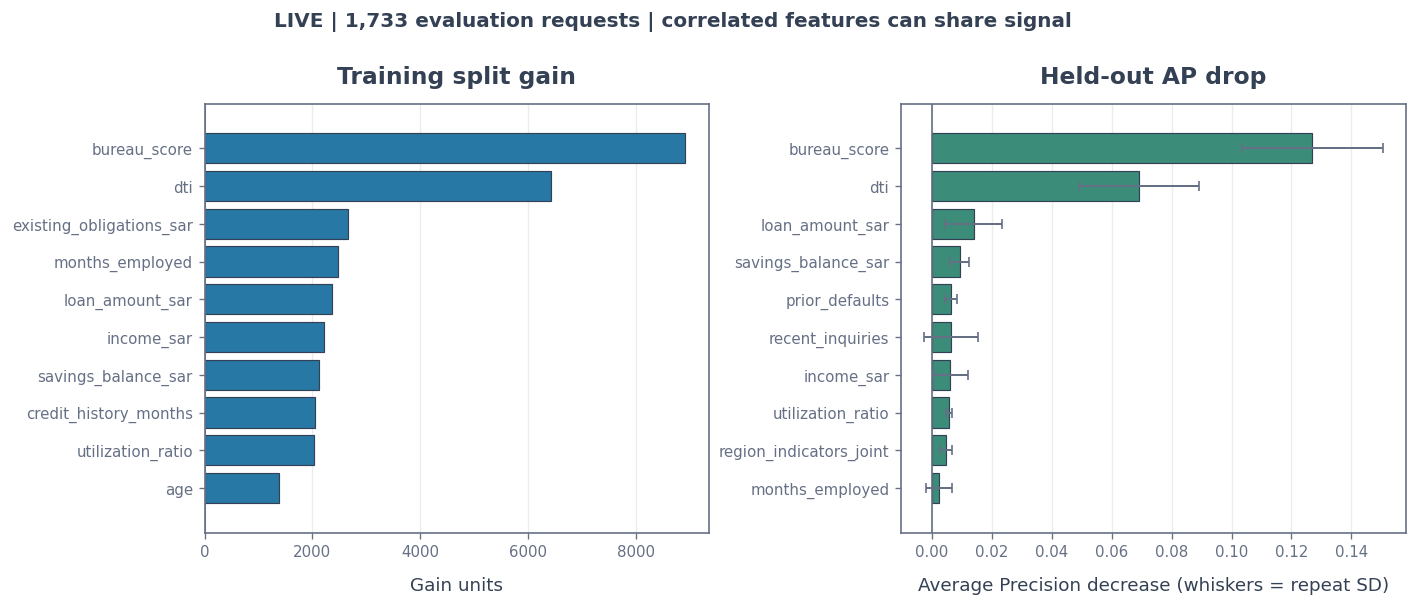

In [ ]:
permutation = permutation_report(model, parts["evaluation"], contract, config)

display(
    permutation[
        ["feature_group", "mean_ap_drop", "repeat_sd", "training_gain"]
    ].head(10).round(4)
)

fig, (ax_gain, ax_drop) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    constrained_layout=False
)

fig.subplots_adjust(
    left=0.20,
    right=0.97,
    top=0.82,
    bottom=0.17,
    wspace=0.38
)

plot_settings = [
    (ax_gain, "training_gain", "Training split gain"),
    (ax_drop, "mean_ap_drop", "Held-out AP drop")
]

for ax, column, title in plot_settings:
    top = permutation.nlargest(10, column).sort_values(column)

    ax.barh(
        top.feature_group,
        top[column],
        color="#2878A5" if column == "training_gain" else "#3B8C78",
        edgecolor="#344054",
        linewidth=0.7,
        xerr=top.repeat_sd if column == "mean_ap_drop" else None,
        error_kw={
            "ecolor": "#667085",
            "elinewidth": 1.2,
            "capsize": 3
        } if column == "mean_ap_drop" else None
    )

    ax.axvline(0, color="#667085", linewidth=1)
    ax.set_title(title, pad=12, fontweight="semibold")
    ax.set_xlabel(
        "Gain units" if column == "training_gain"
        else "Average Precision decrease (whiskers = repeat SD)",
        labelpad=10
    )

    ax.grid(axis="x", color="#E8EDF2", linewidth=0.8)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#667085")
        spine.set_linewidth(1)

    ax.tick_params(axis="both", labelsize=9, colors="#667085")
    ax.margins(y=0.08)

fig.suptitle(
    f"LIVE | {len(evaluation):,} evaluation requests | correlated features can share signal",
    fontsize=12,
    fontweight="semibold",
    color="#344054",
    y=0.96
)

fig.savefig(
    ARTIFACTS / "permutation_importance.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 4. Global SHAP and its unit

TreeSHAP explains the raw (class-weighted) model on a fixed random sample of 300 evaluation requests. The unit is **log-odds**, not probability points: base value + the sum of a request's SHAP values equals its raw margin, and only that sum goes through a sigmoid. These values explain the raw score, not the calibrated probability.

,feature,mean_absolute_shap_log_odds
4,bureau_score,0.9042
5,dti,0.5437
2,loan_amount_sar,0.3490
10,savings_balance_sar,0.2169
9,existing_obligations_sar,0.2022
8,prior_defaults,0.1830
6,months_employed,0.1584
1,income_sar,0.1549
7,recent_inquiries,0.1492
13,utilization_ratio,0.1287


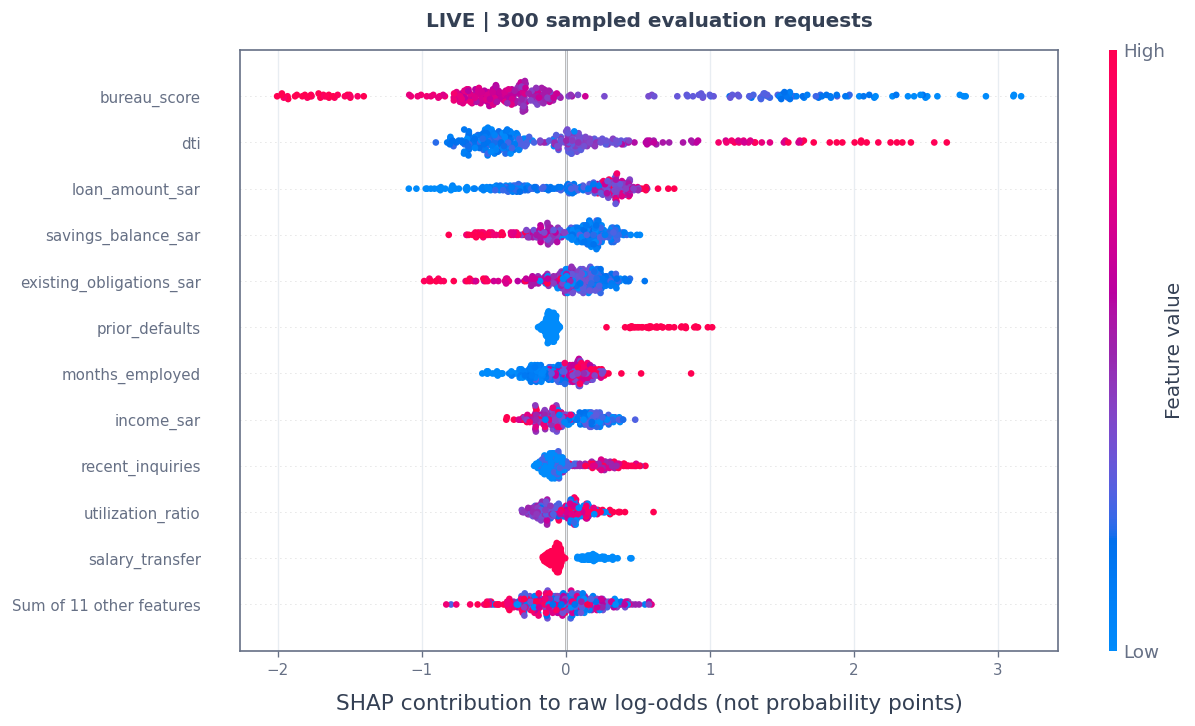

Maximum additivity error: 5.6968318951078345e-15


In [ ]:
try:
    if USE_SHAP_EXAMPLE:
        raise ShapBudgetExpired("Educational example requested.")
    shap_arrays, shap_metadata = explain_sample(
        model, parts["evaluation"], contract, config
    )
except ShapBudgetExpired:
    shap_arrays, shap_metadata = load_shap_example(
        ROOT / "data/day4_shap_example.npz",
        ROOT / "data/day4_shap_example.json",
        model, parts["evaluation"], contract, ASSESSMENT_MODE
    )

import shap

EXPLANATION_SOURCE = shap_metadata["source"]

if EXPLANATION_SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE: for discussion only, not your own run. Re-run SHAP later.")

explanation = shap.Explanation(
    values=shap_arrays["values"],
    base_values=shap_arrays["base_values"],
    data=shap_arrays["data"],
    feature_names=list(shap_arrays["feature_names"])
)

shap_global = (
    pd.DataFrame({
        "feature": shap_arrays["feature_names"],
        "mean_absolute_shap_log_odds": np.abs(shap_arrays["values"]).mean(axis=0)
    })
    .sort_values("mean_absolute_shap_log_odds", ascending=False)
)

display(shap_global.head(10).round(4))

plt.figure(figsize=(11, 6.5), dpi=120)

shap.plots.beeswarm(
    explanation,
    max_display=12,
    show=False,
    plot_size=(11, 6.5)
)

ax = plt.gca()

ax.set_xlabel(
    "SHAP contribution to raw log-odds (not probability points)",
    color="#344054",
    labelpad=10
)

ax.set_title(
    f"{EXPLANATION_SOURCE} | {len(shap_arrays['application_ids'])} sampled evaluation requests",
    fontsize=12,
    fontweight="semibold",
    color="#344054",
    pad=14
)

ax.set_facecolor("white")
ax.grid(axis="x", color="#E8EDF2", linewidth=0.8)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#667085")
    spine.set_linewidth(1)

ax.tick_params(axis="both", colors="#667085", labelsize=9)

plt.savefig(
    ARTIFACTS / "shap_beeswarm.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Maximum additivity error:", shap_metadata["max_additivity_error"])

## 5. Explain one high-score request

The request with the highest raw score inside the SHAP sample is chosen **without** looking at its real outcome. We list the three features that pushed its score up the most and draw a waterfall. A reason code says what the model used, not why the applicant would default. We also nudge `bureau_score` by +/-1 to see if the top reasons stay the same.

TR-009585 | raw score = 0.9031 | calibrated probability = 0.4795


,feature,meaning,value_used,was_imputed,contribution_log_odds
0,bureau_score,Fictional bureau score at application,497.0000,False,2.269325
1,dti,Obligations plus proposed principal-only insta...,1.2806,False,1.198145
2,loan_amount_sar,Requested principal,93437.2900,False,0.200725


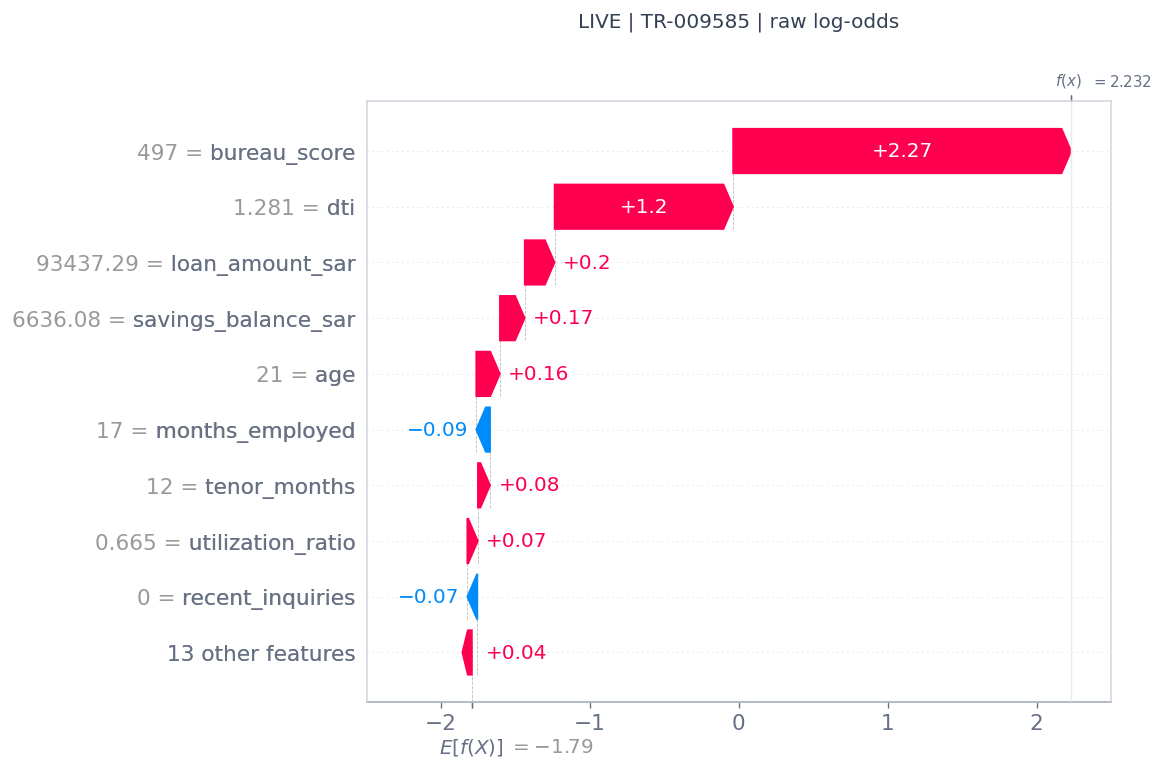

,perturbation,bureau_score_used,raw_probability,calibrated_probability,top_positive_features,shared_top_reasons,reference_reasons,source
0,bureau_score +0,497.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
1,bureau_score -1,496.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
2,bureau_score +1,498.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE


In [ ]:
local_index = int(np.argmax(shap_arrays["raw_margin"]))
local_id = str(shap_arrays["application_ids"][local_index])

case = parts["evaluation"].set_index("application_id", drop=False).loc[[local_id]]

descriptions = {
    f["name"]: f["description_ar"]
    for f in contract["features"]
}

descriptions_en = {
    f["name"]: f["description_en"]
    for f in contract["features"]
}

reasons = reason_codes(
    shap_arrays["values"][local_index],
    shap_arrays["feature_names"],
    shap_arrays["data"][local_index],
    descriptions
)

reasons["application_id"] = local_id
reasons["was_imputed"] = [
    bool(case.iloc[0][name] != case.iloc[0][name])
    for name in reasons.feature
]
reasons["source"] = EXPLANATION_SOURCE
reasons["meaning"] = reasons.feature.map(descriptions_en)

raw_local = float(expit(shap_arrays["raw_margin"][local_index]))
cal_local = float(map_probability(raw_local, mapping))

print(
    f"{local_id} | raw score = {raw_local:.4f} | "
    f"calibrated probability = {cal_local:.4f}"
)

reasons_display = reasons[
    [
        "feature",
        "meaning",
        "value_used",
        "was_imputed",
        "contribution_log_odds"
    ]
]

display(reasons_display)

plt.figure(figsize=(11, 6.5), dpi=120)

shap.plots.waterfall(
    explanation[local_index],
    max_display=10,
    show=False
)

ax = plt.gca()
ax.set_title(
    f"{EXPLANATION_SOURCE} | {local_id} | raw log-odds",
    fontsize=12,
    color="#344054",
    pad=45
)

ax.set_facecolor("white")
ax.grid(
    axis="x",
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.8
)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#D0D5DD")
    spine.set_linewidth(0.9)

ax.tick_params(colors="#667085", labelsize=9)

plt.savefig(
    ARTIFACTS / "shap_waterfall.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

if EXPLANATION_SOURCE == "LIVE":
    local_checks = local_stability(
        model,
        case,
        contract,
        mapping
    )

    local_checks["source"] = "LIVE"

    display(local_checks)

else:
    local_checks = pd.DataFrame(
        columns=[
            "perturbation",
            "bureau_score_used",
            "raw_probability",
            "calibrated_probability",
            "top_positive_features",
            "shared_top_reasons",
            "reference_reasons",
            "source"
        ]
    )

    print(
        "The local perturbation check is skipped in example mode; "
        "do not claim it ran."
    )

## 6. Test calibration on a separate period

The sigmoid is learned on the calibration rows only, and the fitted model and calibrator are then frozen. Because the raw scores come from a class-weighted model, they overstate the real default rate. We compare raw and calibrated scores on the evaluation period with **Brier score** (lower is better), **ECE** (average gap between predicted and observed rate) and a 10-bin reliability plot with counts. Calibration is monotone, so it changes probabilities but not the ranking: ROC-AUC and AP stay equal.

,rows,positives,roc_auc,average_precision,brier,ece,log_loss
raw,1733,139,0.770804,0.258677,0.113027,0.146871,0.357993
sigmoid,1733,139,0.770804,0.258677,0.067112,0.022486,0.246749


Measured change (after - before): Brier -0.04592, ECE -0.12438


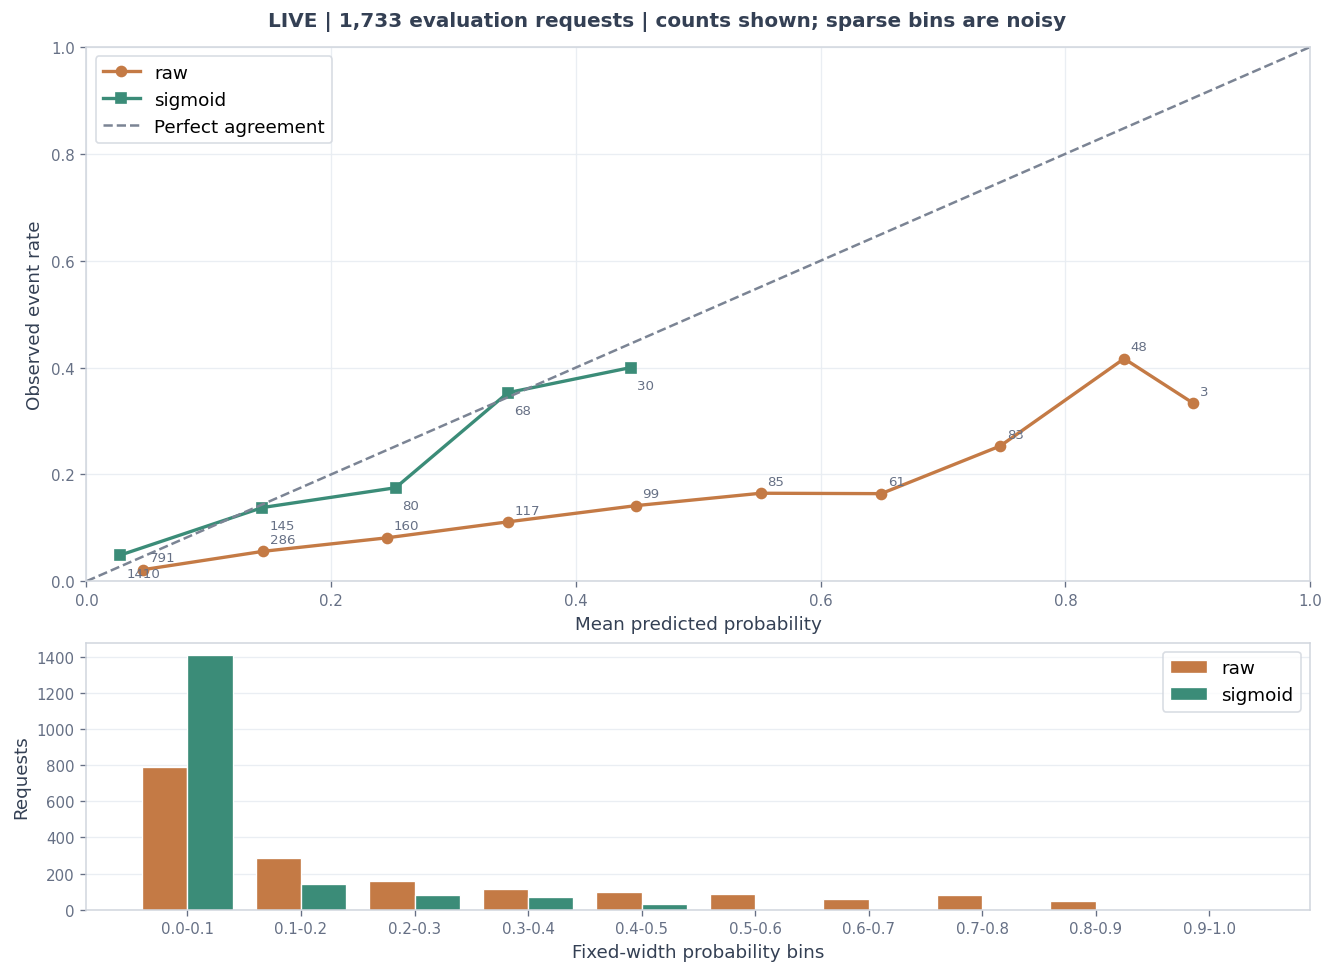

In [ ]:
calibration_metrics, bin_tables = {}, []

for label, column in [
    ("raw", "raw_probability"),
    ("sigmoid", "calibrated_probability")
]:
    calibration_metrics[label] = probability_metrics(
        evaluation[TARGET],
        evaluation[column]
    )

    table = reliability_table(
        evaluation[TARGET],
        evaluation[column]
    )

    table["variant"] = label
    bin_tables.append(table)

reliability = pd.concat(bin_tables, ignore_index=True)

metrics_display = pd.DataFrame(calibration_metrics).T[
    [
        "rows",
        "positives",
        "roc_auc",
        "average_precision",
        "brier",
        "ece",
        "log_loss"
    ]
].round(5)

display(metrics_display)

brier_delta = (
    calibration_metrics["sigmoid"]["brier"]
    - calibration_metrics["raw"]["brier"]
)

ece_delta = (
    calibration_metrics["sigmoid"]["ece"]
    - calibration_metrics["raw"]["ece"]
)

print(
    f"Measured change (after - before): "
    f"Brier {brier_delta:+.5f}, ECE {ece_delta:+.5f}"
)

fig, (ax_cal, ax_cnt) = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    dpi=120,
    layout="constrained",
    gridspec_kw={"height_ratios": [2, 1]}
)

colors = {
    "raw": "#C47A45",
    "sigmoid": "#3B8C78"
}

markers = {
    "raw": "o",
    "sigmoid": "s"
}

for label in ["raw", "sigmoid"]:
    color = colors[label]
    marker = markers[label]

    bins = reliability[reliability.variant == label]
    filled = bins[bins["count"] > 0]

    ax_cal.plot(
        filled.mean_probability,
        filled.observed_rate,
        marker=marker,
        markersize=6,
        linewidth=2,
        color=color,
        label=label
    )

    for row in filled.itertuples():
        ax_cal.annotate(
            str(row.count),
            (row.mean_probability, row.observed_rate),
            xytext=(4, 5 if label == "raw" else -13),
            textcoords="offset points",
            fontsize=8,
            color="#667085"
        )

    ax_cnt.bar(
        bins["bin"] + (-0.2 if label == "raw" else 0.2),
        bins["count"],
        width=0.4,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        label=label
    )

ax_cal.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="#7B8494",
    label="Perfect agreement"
)

ax_cal.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Mean predicted probability",
    ylabel="Observed event rate"
)

ax_cal.legend(frameon=True, edgecolor="#D0D5DD")
ax_cal.grid(
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.9
)
ax_cal.set_axisbelow(True)

ax_cnt.set(
    xticks=np.arange(10),
    xticklabels=[
        f"{i / 10:.1f}-{(i + 1) / 10:.1f}"
        for i in range(10)
    ],
    ylabel="Requests",
    xlabel="Fixed-width probability bins"
)

ax_cnt.legend(frameon=True, edgecolor="#D0D5DD")
ax_cnt.grid(
    axis="y",
    color="#E8EDF2",
    linewidth=0.8,
    alpha=0.9
)
ax_cnt.set_axisbelow(True)

for ax in [ax_cal, ax_cnt]:
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#D0D5DD")
        spine.set_linewidth(0.9)

    ax.tick_params(colors="#667085", labelsize=9)
    ax.xaxis.label.set_color("#344054")
    ax.yaxis.label.set_color("#344054")

fig.suptitle(
    f"LIVE | {len(evaluation):,} evaluation requests | "
    "counts shown; sparse bins are noisy",
    fontsize=12,
    color="#344054",
    fontweight="600"
)

fig.savefig(
    ARTIFACTS / "reliability_curve.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 7. What the stability interval covers (and what it does not)

A paired bootstrap resamples **customers** (not rows, because one customer can have several requests) with the model and calibrator held fixed. The interval therefore reflects evaluation-sample noise only. It does not include model refitting, calibration refitting or future drift. The two quarterly figures are descriptive, not a test.

,period,variant,rows,positives,average_precision,brier,ece
0,2024Q3,raw,836,78,0.27457,0.11528,0.13397
1,2024Q3,sigmoid,836,78,0.27457,0.07760,0.03229
2,2024Q4,raw,897,61,0.27050,0.11093,0.15890
3,2024Q4,sigmoid,897,61,0.27050,0.05734,0.02434


Paired customer-cluster 95% percentile intervals:


,lower,upper
raw_ap,0.19744,0.33785
calibrated_ap,0.19744,0.33785
brier_change,-0.05418,-0.03741


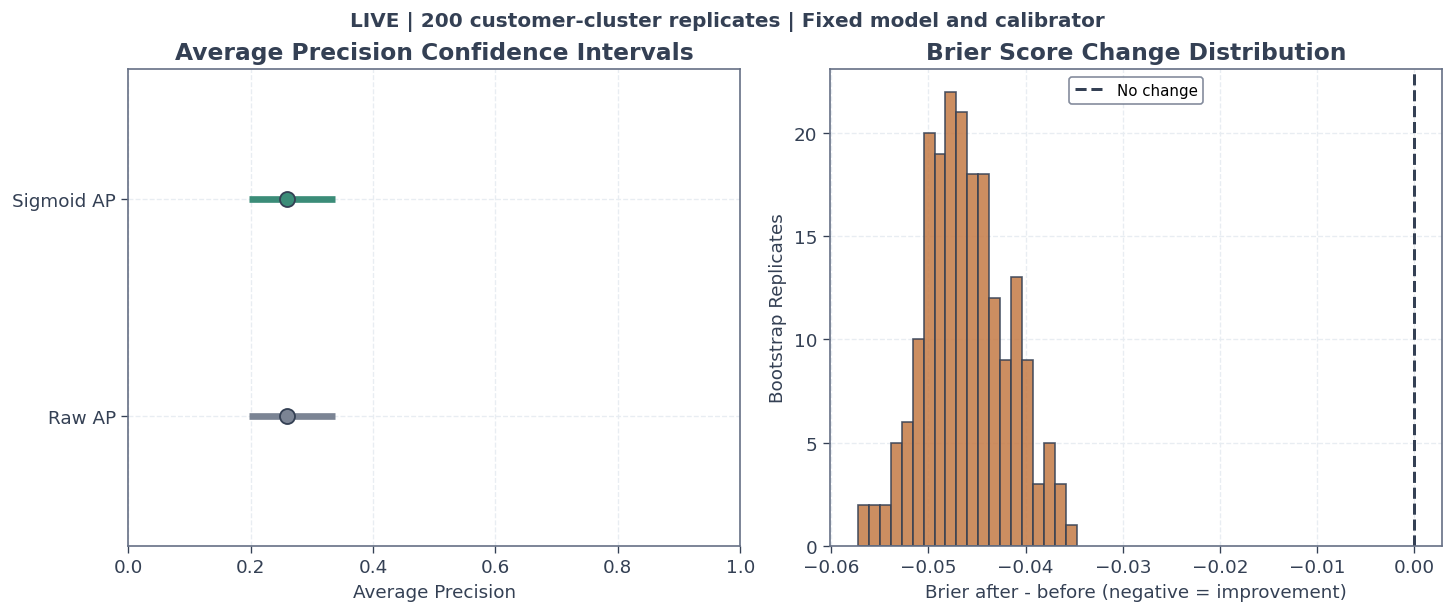

In [ ]:
bootstrap, stability_summary = cluster_bootstrap(evaluation, config)

quarter = pd.to_datetime(evaluation.application_date).dt.to_period("Q").astype(str)

period_rows = []

for period, frame in evaluation.groupby(quarter):
    for variant, column in [
        ("raw", "raw_probability"),
        ("sigmoid", "calibrated_probability")
    ]:
        period_rows.append({
            "period": period,
            "variant": variant,
            **probability_metrics(frame[TARGET], frame[column])
        })

period_metrics = pd.DataFrame(period_rows)

display(
    period_metrics[
        ["period", "variant", "rows", "positives",
         "average_precision", "brier", "ece"]
    ].round(5)
)

stability_summary["period_ap_sample_sd"] = {
    variant: float(frame.average_precision.std(ddof=1))
    for variant, frame in period_metrics.groupby("variant")
}

print("Paired customer-cluster 95% percentile intervals:")

interval_table = pd.DataFrame({
    key: stability_summary[key]
    for key in ("raw_ap", "calibrated_ap", "brier_change")
}).T

display(interval_table.round(5))

COLORS = {
    "main": "#2878A5",
    "raw": "#7B8494",
    "calibrated": "#3B8C78",
    "histogram": "#C47A45",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_ap, ax_hist) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    dpi=120,
    layout="constrained"
)

for i, (key, variant) in enumerate([
    ("raw_ap", "raw"),
    ("calibrated_ap", "sigmoid")
]):
    interval = stability_summary[key]

    color = (
        COLORS["raw"] if variant == "raw"
        else COLORS["calibrated"]
    )

    if interval is not None:
        ax_ap.hlines(
            i,
            interval["lower"],
            interval["upper"],
            color=color,
            linewidth=4,
            zorder=2
        )

        ax_ap.plot(
            calibration_metrics[variant]["average_precision"],
            i,
            marker="o",
            markersize=9,
            color=color,
            markeredgecolor=COLORS["edge"],
            markeredgewidth=1.1,
            zorder=3
        )

ax_ap.set(
    yticks=[0, 1],
    yticklabels=["Raw AP", "Sigmoid AP"],
    xlabel="Average Precision",
    xlim=(0, 1),
    ylim=(-0.6, 1.6),
    title="Average Precision Confidence Intervals"
)

ax_hist.hist(
    bootstrap.brier_change,
    bins=20,
    color=COLORS["histogram"],
    alpha=0.85,
    edgecolor=COLORS["edge"],
    linewidth=1.0
)

ax_hist.axvline(
    0,
    color=COLORS["edge"],
    linewidth=1.8,
    linestyle="--",
    label="No change"
)

ax_hist.set(
    xlabel="Brier after - before (negative = improvement)",
    ylabel="Bootstrap Replicates",
    title="Brier Score Change Distribution"
)

ax_hist.legend(
    fontsize=9,
    frameon=True,
    facecolor="white",
    edgecolor=COLORS["axis"]
)

for ax in (ax_ap, ax_hist):
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"LIVE | {stability_summary['valid']} customer-cluster replicates | "
    "Fixed model and calibrator",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "stability_summary.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 8. Does the review zone fit capacity?

The raw threshold was chosen on the policy role only (loss `10 x FN + FP`, 12% capacity) and carried to the calibrated scale through the sigmoid. Around it we add a diagnostic band of +/-0.02 probability to see how many extra requests sit near the cut-off. A request counted as both a flag and "near threshold" is counted once. If the combined review set exceeds capacity, the correct report is `CAPACITY_REVIEW_REQUIRED`, not a quiet change of the limit.

,threshold,flagged,fn,fp,loss_units,capacity,feasible,calibrated_threshold,selection_role
0,0.5882,68,34,47,387.0,70,True,0.1733,policy


,period,rows,capacity,risk_flags,near_threshold,candidate_review,risk_within_capacity,candidate_within_capacity,loss_units
0,2024Q3,836,100,97,23,109,True,False,536.0
1,2024Q4,897,107,109,21,122,False,False,444.0


CAPACITY_REVIEW_REQUIRED | Do not retune on the evaluation role.


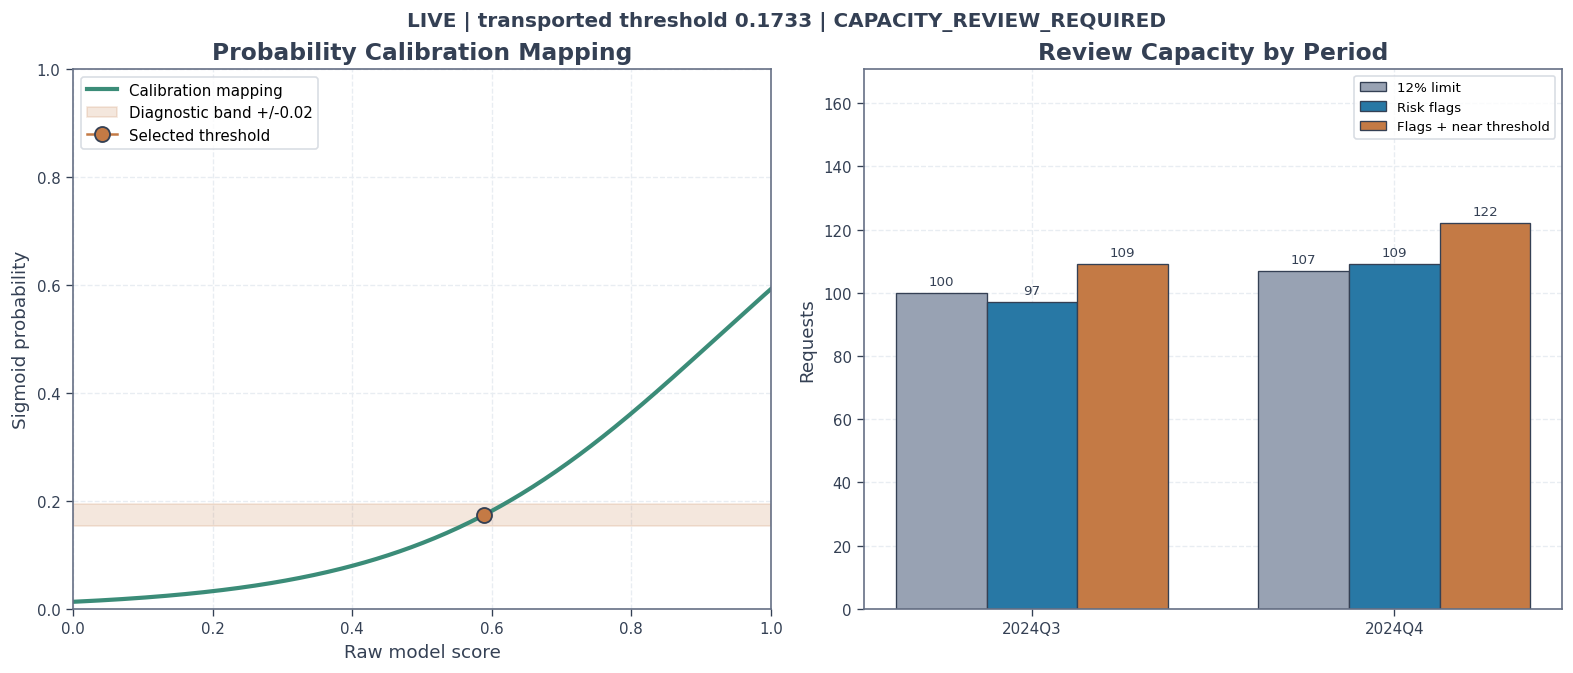

In [ ]:
review_flags, capacity_audit, review_band = review_audit(
    evaluation,
    chosen_policy["threshold"],
    calibrated_threshold,
    config.review_half_width
)

policy_status = (
    "CAPACITY_REVIEW_REQUIRED"
    if not capacity_audit.candidate_within_capacity.all()
    else "WITHIN_OBSERVED_CAPACITY"
)

display(
    pd.DataFrame([{
        **chosen_policy,
        "calibrated_threshold": calibrated_threshold,
        "selection_role": "policy"
    }]).round(4)
)

display(capacity_audit.round(4))

print(policy_status, "| Do not retune on the evaluation role.")

COLORS = {
    "main": "#2878A5",
    "green": "#3B8C78",
    "orange": "#C47A45",
    "grey": "#98A2B3",
    "edge": "#344054",
    "text": "#344054",
    "grid": "#E8EDF2",
    "axis": "#667085"
}

fig, (ax_map, ax_cap) = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=120,
    layout="constrained"
)

grid = np.linspace(0, 1, 300)

ax_map.plot(
    grid,
    map_probability(grid, mapping),
    color=COLORS["green"],
    linewidth=2.5,
    label="Calibration mapping"
)

ax_map.axhspan(
    review_band["lower"],
    review_band["upper"],
    color=COLORS["orange"],
    alpha=0.18,
    label="Diagnostic band +/-0.02"
)

ax_map.plot(
    chosen_policy["threshold"],
    calibrated_threshold,
    marker="o",
    markersize=9,
    color=COLORS["orange"],
    markeredgecolor=COLORS["edge"],
    markeredgewidth=1.1,
    label="Selected threshold",
    zorder=4
)

ax_map.set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="Raw model score",
    ylabel="Sigmoid probability",
    title="Probability Calibration Mapping"
)

ax_map.legend(
    loc="upper left",
    fontsize=9,
    frameon=True,
    edgecolor="#D0D5DD"
)

pos = np.arange(len(capacity_audit))

bar_settings = [
    (-0.25, "capacity", "12% limit", COLORS["grey"]),
    (0.0, "risk_flags", "Risk flags", COLORS["main"]),
    (0.25, "candidate_review", "Flags + near threshold", COLORS["orange"])
]

for shift, column, label, color in bar_settings:
    bars = ax_cap.bar(
        pos + shift,
        capacity_audit[column],
        width=0.25,
        label=label,
        color=color,
        edgecolor=COLORS["edge"],
        linewidth=0.8
    )

    ax_cap.bar_label(
        bars,
        padding=3,
        fontsize=8,
        color=COLORS["text"]
    )

ax_cap.set(
    xticks=pos,
    xticklabels=capacity_audit.period,
    ylabel="Requests",
    title="Review Capacity by Period",
    ylim=(0, max(1, capacity_audit.candidate_review.max()) * 1.4)
)

ax_cap.legend(
    fontsize=8,
    frameon=True,
    edgecolor="#D0D5DD"
)

for ax in (ax_map, ax_cap):
    ax.set_facecolor("white")

    ax.grid(
        axis="both",
        color=COLORS["grid"],
        linewidth=0.8,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(COLORS["axis"])
        spine.set_linewidth(1.0)

    ax.tick_params(
        axis="both",
        colors=COLORS["text"],
        labelsize=9,
        width=0.8,
        length=4
    )

    ax.title.set_color(COLORS["text"])
    ax.title.set_fontweight("bold")
    ax.xaxis.label.set_color(COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])

fig.suptitle(
    f"LIVE | transported threshold {calibrated_threshold:.4f} | {policy_status}",
    fontsize=12,
    fontweight="bold",
    color=COLORS["text"]
)

fig.savefig(
    ARTIFACTS / "review_zone.png",
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()

## 9. Interpretation

In [ ]:
responses = {
    "global_local": (
        "Permutation importance and SHAP agree on the top two features: bureau_score (AP drop 0.127, mean "
        "|SHAP| 0.904 log-odds) and dti (0.069, 0.544). Both are global summaries of what the model relies on "
        "across the 1,733 evaluation requests (SHAP uses a 300-request sample). The waterfall for request "
        "TR-009585 is local: bureau_score (+2.27), dti (+1.20) and loan_amount_sar (+0.20) pushed that one "
        "score up."),
    "output_units": (
        "SHAP values are in raw log-odds of the class-weighted model, not probability points. Base value plus "
        "the sum of SHAP equals the raw margin (maximum additivity error about 6e-15), and a sigmoid of that "
        "sum gives the raw score 0.903 for request TR-009585. That raw score is not a calibrated probability: "
        "after the sigmoid calibrator the same request has probability 0.480."),
    "reason_limits": (
        "The reason codes list only features that raised this request's score. They say what the model used, "
        "not why the applicant would default or what to change. None of the three values was imputed, and "
        "moving bureau_score by +/-1 left the raw score (0.9031) and the three top reasons unchanged, but "
        "correlated features can share credit, so this is still model behaviour, not cause."),
    "calibration_evidence": (
        "On 1,733 evaluation rows (139 positives) the sigmoid cut Brier from 0.1130 to 0.0671 and ECE from "
        "0.1469 to 0.0225, while AP (0.2587) and ROC-AUC (0.7708) stayed identical because the mapping is "
        "monotone. The class weights had inflated the raw scores. The calibrator was learned on only 584 "
        "separate rows (40 positives), so it is a small-sample estimate, and sparse bins are noisy."),
    "stability": (
        "The 95% customer-cluster bootstrap (200 valid replicates, 1,520 customers) gives AP between 0.197 and "
        "0.338 and a Brier change between -0.054 and -0.037, so the Brier gain is consistent across resamples "
        "while AP is quite uncertain. The intervals keep the model and calibrator fixed and do not cover "
        "refitting or future drift. The AP spread between the two evaluation quarters (sample SD 0.003) is "
        "descriptive only."),
    "review_capacity": (
        "The raw threshold 0.5882 (0.1733 after calibration) was chosen on the policy role. On the evaluation "
        "role the risk flags were 97 of 100 in 2024Q3 and 109 of 107 in 2024Q4, and adding requests near the "
        "threshold gave 109 and 122, so the review zone exceeds the 12% capacity: CAPACITY_REVIEW_REQUIRED. "
        "I did not raise the limit or retune on the evaluation role; a new policy would need development data "
        "and fresh evidence."),
}
checkpoint = reflection_check(responses, EXPLANATION_SOURCE)
print(checkpoint["status"], "| Fields to complete:", checkpoint["missing"])

READY_FOR_REVIEW | Fields to complete: []


## 10. Export the report and the evidence bundle

This cell writes the CSV and JSON evidence, the six figures, the SHAP sample, the model file, an English interpretability report and one ZIP.

In [ ]:
NL = chr(10)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    return value


technical_status = "TECHNICAL_READY" if EXPLANATION_SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
calibration_payload = {
    "source": "LIVE", "evaluation_role": "evaluation", "metrics": calibration_metrics, "mapping": mapping,
    "policy_selection": chosen_policy, "calibrated_threshold": calibrated_threshold,
    "review_band": review_band, "capacity_status": policy_status,
    "brier_change": brier_delta, "ece_change": ece_delta,
    "prior_course_exposure": True, "not_a_final_untouched_test": True}
run_info = {
    "technical_status": technical_status, "learner_status": checkpoint["status"],
    "explanation_source": EXPLANATION_SOURCE, "model_calibration_source": "LIVE", "config": asdict(config),
    "assessment_mode": ASSESSMENT_MODE, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION,
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
    "capacity_status": policy_status, "challenge_used_for_modeling": False, "no_automatic_grade": True}

tables = {
    "day4_roles.csv": assignments, "day4_predictions.csv": predictions,
    "permutation_importance.csv": permutation,
    "day4_shap_global.csv": shap_global.assign(source=EXPLANATION_SOURCE),
    "day4_reason_codes.csv": reasons.drop(columns=["meaning"]), "day4_local_stability.csv": local_checks,
    "day4_reliability_bins.csv": reliability, "day4_period_metrics.csv": period_metrics,
    "day4_bootstrap.csv": bootstrap, "day4_policy_sweep.csv": policy_sweep,
    "day4_review_flags.csv": review_flags, "day4_capacity.csv": capacity_audit}
for name, frame in tables.items():
    frame.to_csv(ARTIFACTS / name, index=False)
np.savez_compressed(ARTIFACTS / "shap_values_sample.npz", **shap_arrays)
model.named_steps["model"].booster_.save_model(str(ARTIFACTS / "day4_model.txt"))

json_files = {
    "calibration_metrics.json": calibration_payload, "day4_shap_metadata.json": shap_metadata,
    "day4_stability_summary.json": stability_summary, "day4_provenance.json": provenance,
    "day4_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day4_run.json": run_info}
for name, payload in json_files.items():
    (ARTIFACTS / name).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False),
                                  encoding="utf-8")

state_line = ("Teaching example, not submittable as your own run" if EXPLANATION_SOURCE != "LIVE"
              else "Ready for review; this is not an approval or a grade")
reason_lines = NL.join(f"- {r.feature} = {r.value_used:g}: {r.meaning} (SHAP {r.contribution_log_odds:+.4f} log-odds; "
                       f"imputed: {r.was_imputed})" for r in reasons.itertuples())
capacity_lines = NL.join(f"- {r.period}: limit {r.capacity}, risk flags {r.risk_flags}, "
                         f"flags + near threshold {r.candidate_review}" for r in capacity_audit.itertuples())
top_feature = shap_global.iloc[0]
report = f"""# Interpretability report | Tamweel Lite

**Status:** {state_line}
**Explanation source:** {EXPLANATION_SOURCE} | **Model and calibration:** LIVE | **Capacity:** {policy_status}

## Model and roles
Class-weighted LightGBM, {config.trees} trees. Target: a synthetic default within 90 days. Roles are separated by time and by customer: fit {len(parts['fit'])} rows, calibration {len(parts['calibration'])} ({int(parts['calibration'][TARGET].sum())} positives), policy {len(parts['policy'])}, evaluation {len(evaluation)}. Gap periods and overlapping customers are excluded. The evaluation data was seen earlier in the course, so it is not an untouched final test.

## Global and local explanation
Permutation importance measures the Average Precision lost on the evaluation rows when a feature is shuffled. SHAP explains the raw model in log-odds: base value + sum of SHAP = raw margin, and a sigmoid of that sum gives the raw score. The values are not probability points and do not explain the calibrated probability.

Most important feature by mean |SHAP|: **{top_feature.feature}** ({top_feature.mean_absolute_shap_log_odds:.4f} log-odds). Largest held-out AP drop: **{permutation.iloc[0].feature_group}** ({permutation.iloc[0].mean_ap_drop:.4f}).

Synthetic request {local_id}: raw score {raw_local:.5f}, calibrated probability {cal_local:.5f}. It was chosen as the highest raw score inside the SHAP sample, without using its real outcome.
{reason_lines}

## Calibration
On {len(evaluation)} rows ({int(evaluation[TARGET].sum())} positives): Brier {calibration_metrics['raw']['brier']:.6f} -> {calibration_metrics['sigmoid']['brier']:.6f}; ECE {calibration_metrics['raw']['ece']:.6f} -> {calibration_metrics['sigmoid']['ece']:.6f}. AP {calibration_metrics['raw']['average_precision']:.6f} -> {calibration_metrics['sigmoid']['average_precision']:.6f} and ROC-AUC {calibration_metrics['raw']['roc_auc']:.6f} -> {calibration_metrics['sigmoid']['roc_auc']:.6f} are unchanged because the mapping is monotone. These are results for this sample, not a promise for the future.

## Stability
{stability_summary['valid']} valid customer-cluster bootstrap replicates, 95% percentile intervals, model and calibrator fixed. They exclude refitting, recalibration and future drift, and do not describe one person's probability. The AP spread between the two evaluation quarters is descriptive only. The bureau_score +/-1 check {'ran; see day4_local_stability.csv' if EXPLANATION_SOURCE == 'LIVE' else 'did not run in example mode'}.

## Threshold and review zone
Raw threshold {chosen_policy['threshold']!r} was chosen on the policy role (loss 10 x FN + FP, 12% capacity) and carried to {calibrated_threshold!r} on the calibrated scale; it was not adjusted using the evaluation role. The diagnostic band [{review_band['lower']:.5f}, {review_band['upper']:.5f}] is +/-0.02 and is not a confidence interval; a request is counted once.
{capacity_lines}

If the review set exceeds capacity, document that a new policy must be designed on development data and tested with new evidence. Do not raise the limit or trim cases after seeing the result. SHAP and reason codes describe the model, not causes or fairness. Loss is in teaching units, not money or grade points. This exercise is not for real lending.
"""
(REPORTS / "INTERPRETABILITY_REPORT.md").write_text(report, encoding="utf-8")

figures = ["permutation_importance.png", "shap_beeswarm.png", "shap_waterfall.png",
           "reliability_curve.png", "stability_summary.png", "review_zone.png"]
bundle_files = list(tables) + list(json_files) + figures + ["environment.json", "shap_values_sample.npz",
                                                            "day4_model.txt"]
with zipfile.ZipFile(ARTIFACTS / "day4_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for name in bundle_files:
        bundle.write(ARTIFACTS / name, "artifacts/" + name)
    bundle.write(REPORTS / "INTERPRETABILITY_REPORT.md", "reports/INTERPRETABILITY_REPORT.md")
print(f"{technical_status} | {checkpoint['status']} | {EXPLANATION_SOURCE} | CPU")
print(f"Saved {len(bundle_files) + 1} files in day4_artifacts.zip | {policy_status}")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | CPU
Saved 28 files in day4_artifacts.zip | CAPACITY_REVIEW_REQUIRED


# Day 5 · Choose what is worth shipping and deliver the project

Final day. We compare three single models with equal averaging, weighted averaging and stacking, ask whether the extra complexity earns its place, then export a reproducible calibrated model, `submission.csv`, a model card and a project bundle.

## 1. Setup

In [ ]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7",
                                   "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d",
                                 "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
    "scripts/day4_trust.py": ("4f6892d5c02923b5f8e3c78f4fcead73b043570f",
                              "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c"),
}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"{RAW_BASE}/{revision}/{relative}", ROOT / relative, digest)

LAB_REVISION = "f486fc50dd9ac8403016facc58cf6a62beb4abf4"
SUPPORT_HASHES = {
    "scripts/day5_final.py": "71553cffc66f972e77d470a347cae40e4ca2802026535b48cb40168a59362b10",
    "scripts/day5_delivery.py": "eba5b5820550b44ccca2cf7f5d56a826c015de552e5db8d7e4c27a6e956ecd21",
    "scripts/inference.py": "abf1af0bca47bcd08e66f8218276773d39083e6f42f42caeea5d8b2db70c0a6a",
    "scripts/replay_final.py": "adcb2e40aff819439068cd7a2aca9fcb6f8632b0c551a9d04f7bd63efc8506fb",
    "scripts/rebuild_final.py": "ac18b78160dbc33b720f3e1038667110760832c095e23c1ea7f909d4c5760dfd",
    "data/tamweel_oof_matrix.csv": "f8c9429c7eed015d53978fba93b4b32ed3266fa15b63471b03881ab5c09804b5",
    "data/day5_oof_example.json": "9edcb173ab5aa504af3ef79c4f3371cd285fa4b171be1bcc6dd9da1d7fb0394d",
    "presentation/FINAL_PRESENTATION_TEMPLATE.md": "8d3df570727b18db097c9c78ed518ac09bd8766dbdba2817ae8883e43ed5de39",
    "presentation/FINAL_PRESENTATION_GUIDE.md": "1d24149ef2e56df0a6c44e000157135904b8ba3d252445e4367a6de547c87b19",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 5 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 5 setup verified


## 2. Reserve calibration and respect label availability

The target is a default within 90 days of applying. July to September 2024 is reserved for calibration only, and its customers are removed from the fit-and-selection pool. The pool holds only applications whose outcomes matured before 1 July 2024.

Comparison folds are 2023Q1, 2023Q3 and 2024Q1. In each outer fold the training period ends early enough for the 90-day outcome to mature, and validation customers are removed from training. A second forward split inside the outer training rows learns the averaging weights and the logistic stacker, so no meta-model ever sees in-sample base predictions. This is development evidence, not an untouched final test, and challenge labels do not exist.

In [ ]:
import json
import platform
import zipfile
from dataclasses import asdict
from hashlib import sha256

import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink

from data_checks import validate_frame
from day5_final import (BASE, ENSEMBLES, TARGET, FinalConfig, EnsembleBudgetExpired, split_final_roles,
                        nested_comparison, load_example, worth_it, selected_oof, fit_final, export_model,
                        predict_final, transport_threshold, apply_batch_policy, write_json)
from day3_decision import CostPolicy, threshold_sweep, select_threshold, region_audit, period_audit
from day4_trust import probability_metrics, reliability_table, map_probability
from day5_delivery import (RESPONSES, reflection_check, import_daily_evidence, evidence_status,
                           validate_submission, replay_submission, create_bundle, verify_bundle)

STARTED = time.perf_counter()
contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train = pd.read_csv(ROOT / "data/tamweel_train.csv")
challenge = pd.read_csv(ROOT / "data/tamweel_challenge.csv")
validate_frame(train, contract, "train")
validate_frame(challenge, contract, "challenge")
assert not set(train.customer_id) & set(challenge.customer_id)

FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = FinalConfig() if FAST_MODE else FinalConfig(trees=160, seconds=240)
USE_OOF_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
pool, calibration, roles = split_final_roles(train)

ARTIFACTS, REPORTS, SUBMISSION = ROOT / "artifacts", ROOT / "reports", ROOT / "submission"
for folder in (ARTIFACTS, REPORTS, SUBMISSION):
    folder.mkdir(exist_ok=True)

BLUE, ORANGE, GREEN, GREY, SAND = "#2667A0", "#BA5A17", "#18816A", "#777777", "#D3D9DE"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
SAVE = {"dpi": 160, "bbox_inches": "tight"}

display(pd.DataFrame([{
    "role": name, "rows": len(frame), "customers": frame.customer_id.nunique(),
    "positives": int(frame[TARGET].sum()), "first_date": frame.application_date.min(),
    "last_date": frame.application_date.max()}
    for name, frame in [("fit + selection", pool), ("calibration only", calibration)]]))
print("Excluded rows:", int(roles.role.str.startswith("excluded").sum()))

,role,rows,customers,positives,first_date,last_date
0,fit + selection,6576,3931,537,2022-01-01,2024-04-01
1,calibration only,836,788,78,2024-07-01,2024-09-30


Excluded rows: 2588


## 3. Build nested forward OOF without leakage

Unweighted LightGBM, XGBoost and Logistic Regression are compared; error cost is handled later by the threshold. Imputation and scaling are learned inside training only. The weighted average searches a small grid of non-negative weights that sum to one, on inner OOF only, and the logistic stacker learns from the same three inner-OOF columns. Base learners are then refit on the outer training data and all six candidates are scored on the outer validation period. Weights and coefficients may differ by fold, because what we compare is the learning procedure. If the CPU budget runs out, a labelled example may appear instead; it exports no final model or submission.

In [ ]:
try:
    if USE_OOF_EXAMPLE:
        raise EnsembleBudgetExpired("Educational OOF example requested.")
    oof, fold_scores, oof_provenance = nested_comparison(pool, contract, config)
except EnsembleBudgetExpired:
    oof, fold_scores, oof_provenance = load_example(ROOT / "data/tamweel_oof_matrix.csv",
                                                    ROOT / "data/day5_oof_example.json",
                                                    pool, config, assessment_mode=ASSESSMENT_MODE)
SOURCE = oof.source.iloc[0]
if SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE: for discussion only, no final model or submission.")
display(oof[["application_id", "fold", *BASE, *ENSEMBLES]].head().round(4))
print(f"{SOURCE}: {len(oof):,} OOF rows across three forward periods; warm-up rows have no outer OOF.")

,application_id,fold,LightGBM,XGBoost,Logistic,Equal,Weighted,Stack
0,TR-001160,1,0.0321,0.0444,0.0467,0.0410,0.0461,0.0684
1,TR-003137,1,0.1149,0.1798,0.1547,0.1498,0.1610,0.1085
2,TR-004529,1,0.0457,0.0854,0.0887,0.0733,0.0879,0.0796
3,TR-004666,1,0.0123,0.0150,0.0062,0.0112,0.0084,0.0593
4,TR-008372,1,0.0373,0.0538,0.0336,0.0416,0.0387,0.0674


LIVE: 2,155 OOF rows across three forward periods; warm-up rows have no outer OOF.


## 4. Inspect prediction and residual diversity

The left heatmap shows how the three base models' OOF probabilities move together; the right one shows the residuals `p - y` on the same requests. Residuals share the target, so they can stay highly correlated. Correlation is descriptive, and low correlation alone neither proves an ensemble gain nor justifies adding a weak model.

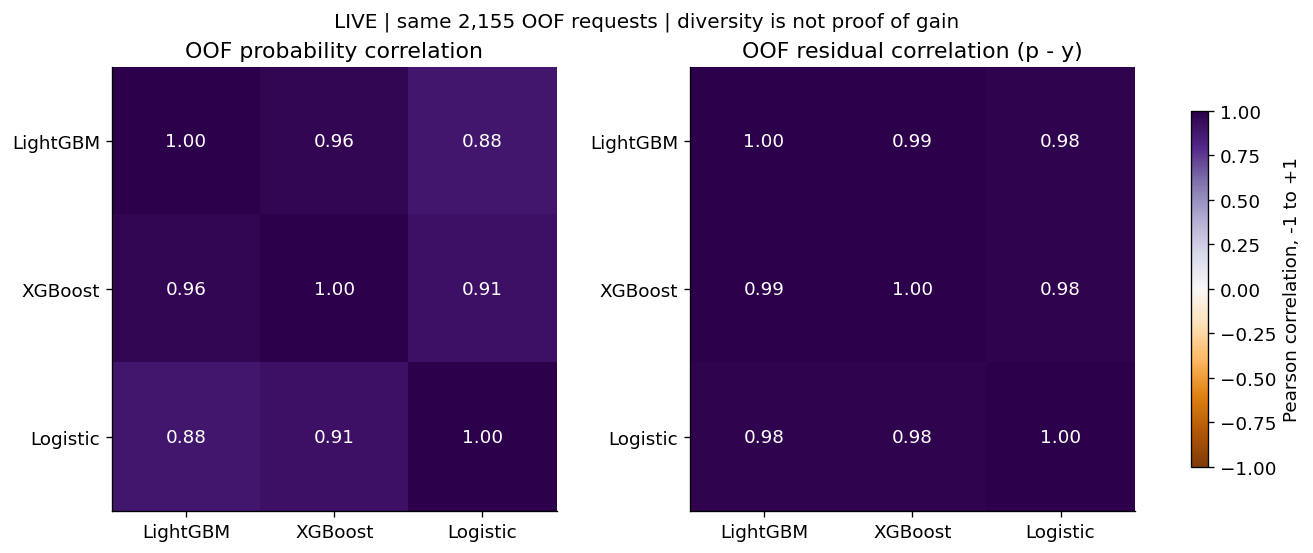

In [ ]:
correlation = oof[list(BASE)].corr()
residual_correlation = oof[list(BASE)].sub(oof[TARGET], axis=0).corr()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, table, title in [(axes[0], correlation, "OOF probability correlation"),
                         (axes[1], residual_correlation, "OOF residual correlation (p - y)")]:
    image = ax.imshow(table, vmin=-1, vmax=1, cmap="PuOr")
    ax.grid(False)
    ax.set_xticks(range(3), BASE)
    ax.set_yticks(range(3), BASE)
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            value = table.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > .6 else "#222222")
fig.colorbar(image, ax=axes, shrink=.8, label="Pearson correlation, -1 to +1")
fig.suptitle(f"{SOURCE} | same {len(oof):,} OOF requests | diversity is not proof of gain", fontsize=12)
fig.savefig(ARTIFACTS / "day5_diversity.png", **SAVE)
plt.show()

## 5. Apply the worth-it gate

The best single model is the one with the highest mean Average Precision over the three forward folds. An ensemble is accepted only if its AP gain is larger than that single model's fold standard deviation, its Brier does not worsen by more than 0.005 and its ECE by more than 0.01. These are fixed teaching rules, not a significance test: the standard deviation comes from only three overlapping periods. If several ensembles pass, the simplest wins (equal, then weighted, then stack), and an ensemble is never forced to win.

,candidate,mean_ap,fold_sd,mean_brier,mean_ece,lift_vs_single,passes_gate
0,LightGBM,0.3455,0.0435,0.0661,0.0231,-0.0462,False
1,XGBoost,0.3526,0.0290,0.0657,0.0228,-0.0390,False
2,Logistic,0.3917,0.0298,0.0633,0.0188,0.0000,False
3,Equal,0.3717,0.0326,0.0643,0.0204,-0.0200,False
4,Weighted,0.3894,0.0291,0.0633,0.0177,-0.0022,False
5,Stack,0.3831,0.0295,0.0660,0.0311,-0.0085,False


KEEP SINGLE -> Logistic


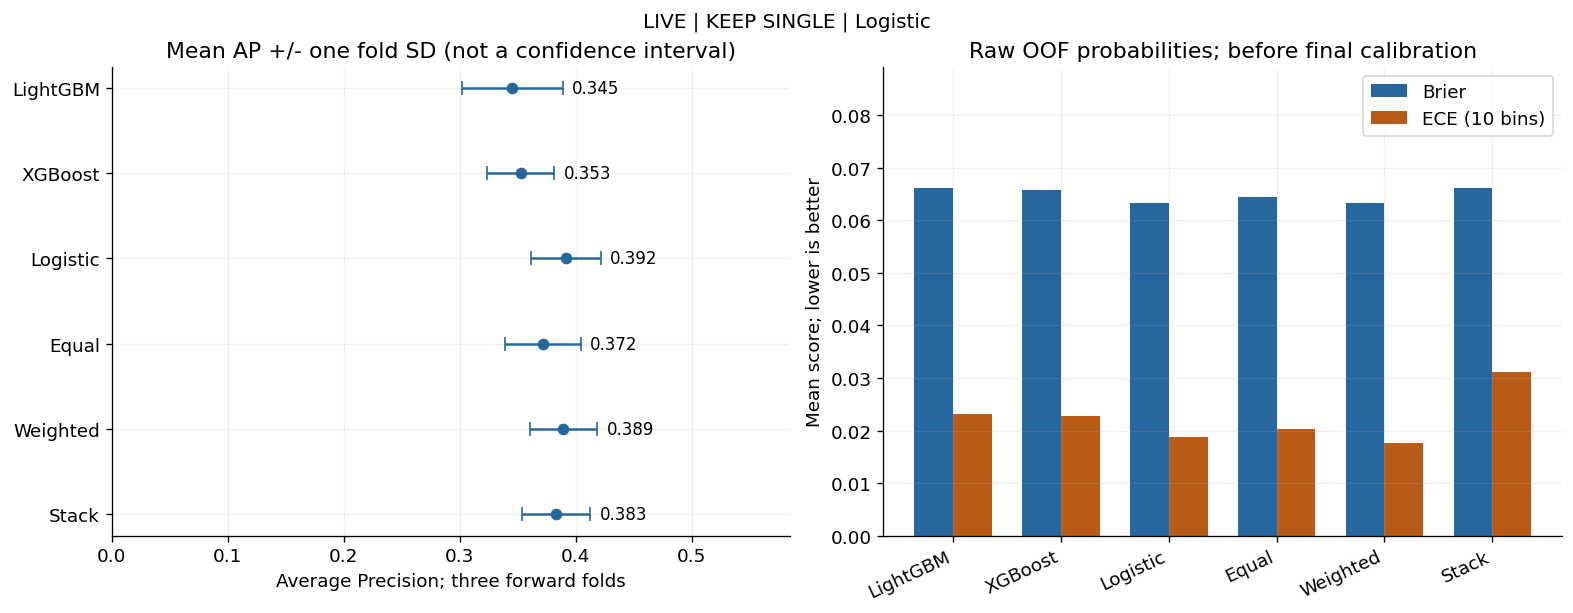

In [ ]:
comparison, gate = worth_it(fold_scores, config)
display(comparison.round(4))
print(gate["decision"], "->", gate["chosen"])

order = list(BASE + ENSEMBLES)
fig, (ax_ap, ax_cal) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for i, name in enumerate(order):
    row = comparison.set_index("candidate").loc[name]
    ax_ap.errorbar(row.mean_ap, i, xerr=row.fold_sd, fmt="o", color=BLUE, capsize=4)
    ax_ap.text(row.mean_ap + row.fold_sd + .008, i, f"{row.mean_ap:.3f}", va="center", fontsize=10)
ax_ap.set_yticks(range(6), order)
ax_ap.invert_yaxis()
ax_ap.set_xlim(0, min(1, comparison.mean_ap.max() + comparison.fold_sd.max() + .15))
ax_ap.set_title("Mean AP +/- one fold SD (not a confidence interval)")
ax_ap.set_xlabel("Average Precision; three forward folds")

x = np.arange(6)
ax_cal.bar(x - .18, comparison.mean_brier, .36, label="Brier", color=BLUE)
ax_cal.bar(x + .18, comparison.mean_ece, .36, label="ECE (10 bins)", color=ORANGE)
ax_cal.set_xticks(x, order, rotation=25, ha="right")
ax_cal.set_ylabel("Mean score; lower is better")
ax_cal.set_title("Raw OOF probabilities; before final calibration")
ax_cal.legend()
ax_cal.set_ylim(0, max(comparison.mean_brier.max(), comparison.mean_ece.max()) * 1.35)
fig.suptitle(f"{SOURCE} | {gate['decision']} | {gate['chosen']}", fontsize=12)
fig.savefig(ARTIFACTS / "day5_ensemble_comparison.png", **SAVE)
plt.show()

## 6. Freeze the OOF decision policy

Every distinct OOF score of the chosen model is tried as a threshold, looking for the lowest teaching loss `10 x FN + FP` that keeps every fold and the total within 12% capacity. Equal scores stay in one block. Loss units are fictional (not riyals, fees or grade deductions). The regional table is a descriptive OOF diagnostic with denominators and positive counts, not a fairness certificate, and challenge FPR cannot be computed without labels. The sensitivity table changes only the FN cost while the model, threshold and decisions stay fixed.

,threshold,tp,fp,fn,tn,flagged,flag_fraction,recall,precision,false_positive_rate,accuracy,loss_units,loss_units_per_10000,capacity_feasible,max_period_flag_fraction,rows,source
0,0.1689,84,161,95,1815,245,0.1137,0.4693,0.3429,0.0815,0.8812,1111.0,5155.4524,True,0.1175,2155,LIVE


,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,537,489,48,63,39,24,0.0798,0.5000,False,LIVE
1,western,533,486,47,71,50,21,0.1029,0.4468,False,LIVE
2,eastern,542,507,35,48,32,16,0.0631,0.4571,False,LIVE
3,other,543,494,49,63,40,23,0.0810,0.4694,False,LIVE


,false_negative_cost,false_positive_cost,fixed_threshold,loss_units
0,8,1,0.168922,921
1,10,1,0.168922,1111
2,12,1,0.168922,1301


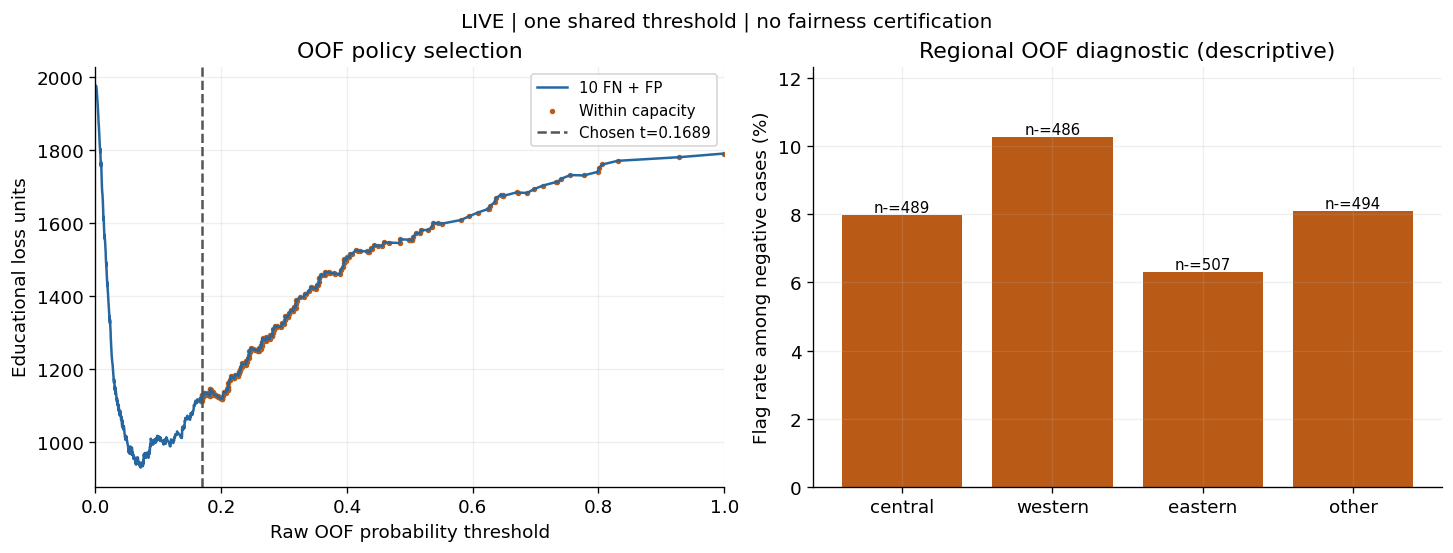

In [ ]:
policy = CostPolicy()
selected = selected_oof(oof, gate["chosen"])
sweep = threshold_sweep(selected, policy)
threshold_choice = select_threshold(sweep)
raw_threshold = float(threshold_choice["threshold"])
regional, regional_summary = region_audit(selected, raw_threshold)
period_capacity = period_audit(selected, raw_threshold, policy)
sensitivity = pd.DataFrame([{
    "false_negative_cost": cost, "false_positive_cost": 1, "fixed_threshold": raw_threshold,
    "loss_units": cost * int(threshold_choice["fn"]) + int(threshold_choice["fp"])} for cost in (8, 10, 12)])

display(pd.DataFrame([threshold_choice]).round(4))
display(regional.round(4))
display(sensitivity)

fig, (ax_loss, ax_reg) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
ax_loss.plot(sweep.threshold, sweep.loss_units, color=BLUE, label="10 FN + FP")
feasible = sweep[sweep.capacity_feasible]
ax_loss.scatter(feasible.threshold, feasible.loss_units, s=5, color=ORANGE, label="Within capacity")
ax_loss.axvline(raw_threshold, color="#555555", ls="--", label=f"Chosen t={raw_threshold:.4f}")
ax_loss.set(xlim=(0, 1), xlabel="Raw OOF probability threshold", ylabel="Educational loss units",
            title="OOF policy selection")
ax_loss.legend(fontsize=9)
ax_reg.bar(regional.region, regional.false_positive_rate * 100, color=ORANGE)
ax_reg.set(ylabel="Flag rate among negative cases (%)", title="Regional OOF diagnostic (descriptive)")
for i, row in regional.iterrows():
    ax_reg.text(i, row.false_positive_rate * 100, f"n-={row.negatives}", ha="center", va="bottom", fontsize=9)
ax_reg.margins(y=.2)
fig.suptitle(f"{SOURCE} | one shared threshold | no fairness certification", fontsize=12)
fig.savefig(ARTIFACTS / "day5_policy_regions.png", **SAVE)
plt.show()

## 7. Refit the chosen procedure and freeze calibration

The chosen learning procedure is refit on the eligible pool, and one sigmoid mapping is learned on the reserved calibration period only. The estimator is not retrained afterwards, because an old calibrator and threshold would no longer match it. The OOF threshold is carried to the calibrated scale through the monotone mapping. The reliability figure is a **calibration-fit diagnostic** on the very rows that taught the calibrator, so it is not independent evidence. Moving a threshold from OOF models to a refit model can change flag volume, which is why capacity is applied to the whole batch later. Day 4 SHAP explanations belong to the Day 4 model and are not automatically valid for a different final model.

,rows,positives,prevalence,roc_auc,average_precision,brier,log_loss,ece,bins,binning
raw_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.076473,0.266489,0.021121,10,"fixed width, [lower, upper); final bin includes 1"
sigmoid_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.078058,0.277296,0.034871,10,"fixed width, [lower, upper); final bin includes 1"


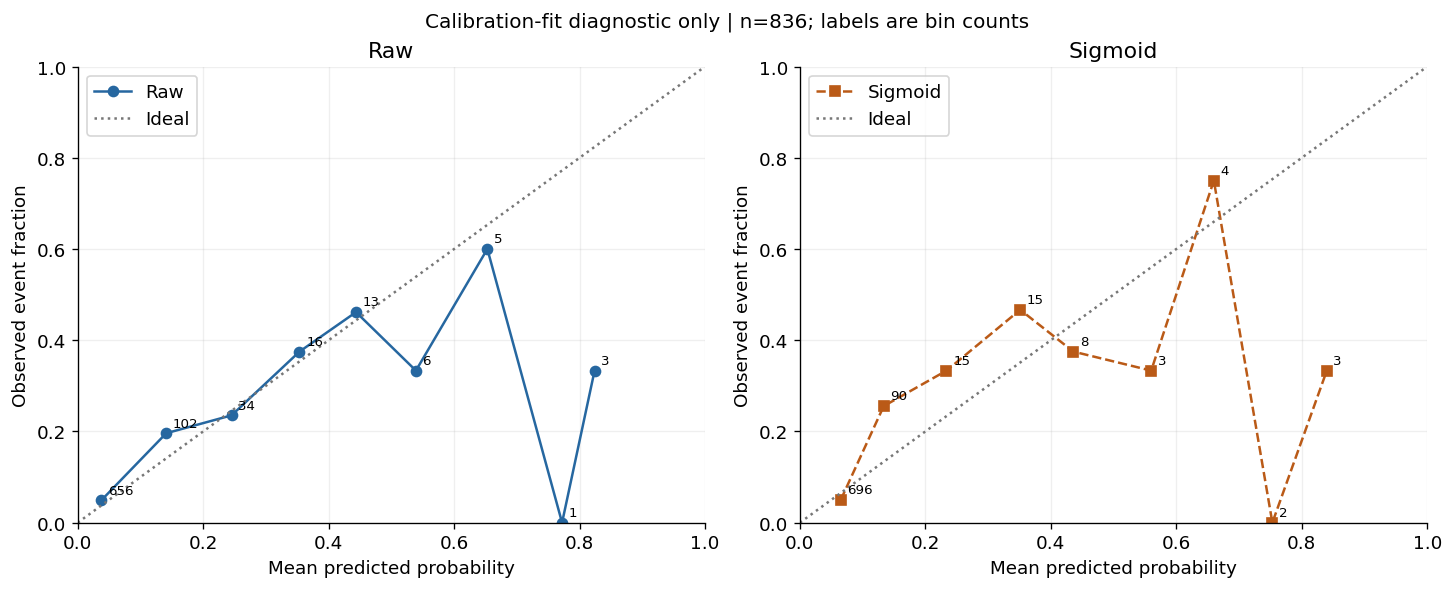

Final model and sigmoid frozen; transported threshold: 0.12225843144286948


In [ ]:
if SOURCE == "LIVE":
    final_model, mapping, calibration_predictions, final_provenance = fit_final(
        pool, calibration, contract, gate["chosen"], config)
    calibrated_threshold = transport_threshold(raw_threshold, mapping)
    final_model_manifest = export_model(final_model, mapping, contract, ARTIFACTS / "final_model")
    calibration_diagnostics = {
        name: probability_metrics(calibration_predictions[TARGET], calibration_predictions[column])
        for name, column in [("raw_fit_diagnostic", "raw_probability"), ("sigmoid_fit_diagnostic", "probability")]}
    bins = pd.concat([
        reliability_table(calibration_predictions[TARGET], calibration_predictions[column]).assign(series=name)
        for name, column in [("Raw", "raw_probability"), ("Sigmoid", "probability")]], ignore_index=True)
    display(pd.DataFrame(calibration_diagnostics).T.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    for ax, name, style, color in [(axes[0], "Raw", "o-", BLUE), (axes[1], "Sigmoid", "s--", ORANGE)]:
        table = bins[(bins.series == name) & (bins["count"] > 0)]
        ax.plot(table.mean_probability, table.observed_rate, style, label=name, color=color)
        for row in table.itertuples():
            ax.annotate(str(row.count),
                        (row.mean_probability, row.observed_rate), xytext=(4, 4),
                        textcoords="offset points", fontsize=8)
        ax.plot([0, 1], [0, 1], ":", color=GREY, label="Ideal")
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability",
               ylabel="Observed event fraction", title=name)
        ax.legend()
    fig.suptitle(f"Calibration-fit diagnostic only | n={len(calibration)}; labels are bin counts", fontsize=12)
    fig.savefig(ARTIFACTS / "day5_calibration_fit.png", **SAVE)
    plt.show()
    print("Final model and sigmoid frozen; transported threshold:", calibrated_threshold)
else:
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE: final fitting, inference and submission are skipped.")

## 8. Score every challenge request and apply capacity once

`inference.predict` returns each application ID with its calibrated probability, in request order. Probabilities may be computed in chunks, but all chunks are joined before the full-batch policy is applied once. Candidates are the requests above the transported threshold; if they exceed 12% of the 2,500-request batch, the highest probabilities are kept up to 300. An equal-score block is never split by identifier: if the whole boundary block does not fit, it is dropped and capacity stays partly unused. `decision = 1` is a simulated review flag and `decision = 0` is not an approval or a safety guarantee. Challenge AP, loss and FPR are not computed because labels do not exist.

,application_id,probability,decision
0,CH-000278,0.114104,0
1,CH-001412,0.120922,0
2,CH-001444,0.055587,0
3,CH-002174,0.053426,0
4,CH-002260,0.077174,0


,rows,capacity,threshold_eligible,flagged,removed_by_cap,boundary_score,within_capacity,tie_policy,batch_policy
0,2500,300,330,300,30,0.129908,True,retain entire equal-score blocks; drop boundar...,"threshold first, then probability-descending f..."


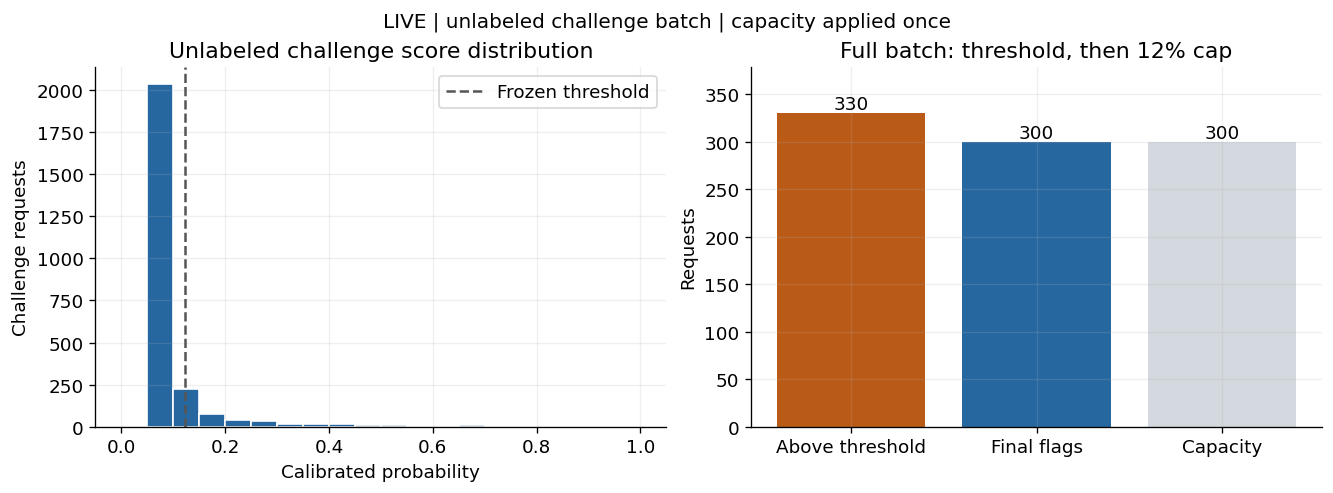

In [ ]:
if SOURCE == "LIVE":
    from inference import predict
    predictions = predict(challenge, ARTIFACTS / "final_model")
    submission, batch_audit = apply_batch_policy(predictions, calibrated_threshold, policy)
    validate_submission(submission, challenge, calibrated_threshold, policy)
    expected = map_probability(
        final_model.predict_proba(challenge[[f["name"] for f in contract["features"]]])[:, 1], mapping)
    assert np.allclose(predictions.probability, expected, rtol=0, atol=1e-12)
    display(submission.head())
    display(pd.DataFrame([batch_audit]))

    fig, (ax_dist, ax_cap) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    ax_dist.hist(predictions.probability, bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white")
    ax_dist.axvline(calibrated_threshold, color="#555555", ls="--", label="Frozen threshold")
    ax_dist.set(xlabel="Calibrated probability", ylabel="Challenge requests",
                title="Unlabeled challenge score distribution")
    ax_dist.legend()
    counts = [batch_audit["threshold_eligible"], batch_audit["flagged"], batch_audit["capacity"]]
    ax_cap.bar(["Above threshold", "Final flags", "Capacity"], counts, color=[ORANGE, BLUE, SAND])
    ax_cap.set(ylabel="Requests", title="Full batch: threshold, then 12% cap")
    for i, n in enumerate(counts):
        ax_cap.text(i, n, str(n), ha="center", va="bottom")
    ax_cap.margins(y=.15)
    fig.suptitle("LIVE | unlabeled challenge batch | capacity applied once", fontsize=12)
    fig.savefig(ARTIFACTS / "day5_challenge_capacity.png", **SAVE)
    plt.show()
else:
    print("No challenge predictions are produced from the educational example.")

## 9. Write the decision and assemble your evidence

In [ ]:
responses = {
    "ensemble_reason": (
        "I kept a single model, Logistic Regression. It had the best mean Average Precision across the three "
        "forward folds (0.392, fold SD 0.030), ahead of XGBoost (0.353) and LightGBM (0.346). No ensemble beat "
        "it: equal averaging scored 0.372 (-0.020), weighted averaging 0.389 (-0.002) and stacking 0.383 "
        "(-0.009), so none came close to the required gain of more than 0.030. Brier (0.0633 vs 0.0633) and ECE "
        "(0.0188 vs 0.0177) were also no better in a way that would justify the extra complexity. Gate result: "
        "KEEP SINGLE."),
    "validation_limits": (
        "The evidence is nested forward OOF: folds 2023Q1, 2023Q3 and 2024Q1, training far enough in the past "
        "for 90-day outcomes to mature, validation customers removed from training, and ensemble weights and "
        "the stacker learned on inner OOF only. The limits are that three periods overlap in their training "
        "history, so the fold SD (0.030) is descriptive and not a confidence interval, that the AP gaps between "
        "candidates are small, and that the same training data was used earlier in the course, so this is not "
        "an untouched final test."),
    "calibration_limits": (
        "The sigmoid was learned on a reserved period (July to September 2024, 836 rows, 78 positives) kept out "
        "of the fit pool, but its diagnostics are scored on those same rows, so they are fit diagnostics, not "
        "independent evidence. On them the sigmoid left ranking unchanged (AP 0.288, ROC-AUC 0.789) and did not "
        "improve calibration (Brier 0.0765 to 0.0781, ECE 0.0211 to 0.0349), which suggests the unweighted "
        "logistic scores were already reasonably calibrated. With only 78 positives the estimate is noisy, and "
        "no challenge labels exist to test it."),
    "capacity_fairness": (
        "Capacity was applied once to the whole 2,500-request batch: 330 requests were above the transported "
        "threshold (0.1223), the 300-request cap kept 300 and removed 30 (boundary score 0.1299), and no "
        "equal-score block was split. The regional OOF flag rate among negatives ranges from 6.3% (eastern) to "
        "10.3% (western), a gap of 3.98 percentage points, with 486 to 507 negatives per region. This is a "
        "descriptive diagnostic with no confidence interval and is not a fairness certificate; challenge FPR "
        "cannot be computed without labels."),
    "explanation_scope": (
        "The Day 4 explanations belong to the class-weighted LightGBM of Day 4. The final model is an "
        "unweighted Logistic Regression with a sigmoid calibrator, so those SHAP values and reason codes do not "
        "transfer to it. For the final model I would need to recheck its own coefficients or SHAP values, the "
        "calibration, and the review zone against the 12% capacity before explaining any individual decision."),
    "intended_use": (
        "This is a fictional training exercise on synthetic data. The flags simulate sending a request to "
        "review. It must not be used for real financing, to approve or reject an applicant, or as evidence "
        "about real people or regions."),
    "monitoring_plan": (
        "Track feature and score distributions against the training data for drift; the share of requests "
        "flagged per period against the 12% capacity; calibration (Brier, ECE and reliability) on each newly "
        "labelled period, recalibrating or retraining when it drifts; and the regional flag rate and recall. "
        "Because the transported threshold can change flag volume after refitting, capacity must be checked on "
        "every new batch before use."),
    "executive_summary_ar": (
        "اخترنا نموذج Logistic Regression منفرداً لأنه حقق أعلى متوسط Average Precision (0.392) عبر الطيات الأمامية "
        "الثلاث، ولم يتجاوزه أي تجميع بالقدر المطلوب (أكثر من 0.030). عُيّرت الاحتمالات بتحويل sigmoid، وطُبقت "
        "سعة 12% مرة واحدة على دفعة التحدي (300 إشارة من 2,500 طلب). البيانات اصطناعية والنتائج للتدريب فقط."),
    "executive_summary_en": (
        "We chose a single Logistic Regression because it had the best mean Average Precision (0.392) across "
        "three forward folds, and no ensemble beat it by more than the 0.030 fold SD. Probabilities were "
        "calibrated with a sigmoid and the 12% capacity was applied once to the challenge batch (300 flags of "
        "2,500 requests). The data are synthetic and the results are for training only."),
}
checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| Missing:", checkpoint["missing"])
print("Upload your previous daily ZIPs here if available:", ROOT)

READY_FOR_REVIEW | Missing: []
Upload your previous daily ZIPs here if available: /content/tamweel


## 10. Export and verify the project bundle

In [ ]:
def clean_json(value):
    if isinstance(value, dict):
        return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean_json(v) for v in value]
    if isinstance(value, np.generic):
        return clean_json(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


tables = {
    "day5_roles.csv": roles, "day5_oof_predictions.csv": oof, "day5_fold_scores.csv": fold_scores,
    "ensemble_comparison.csv": comparison, "day5_threshold_sweep.csv": sweep,
    "day5_region_audit.csv": regional, "day5_period_capacity.csv": period_capacity,
    "day5_cost_sensitivity.csv": sensitivity}
for name, table in tables.items():
    table.to_csv(ARTIFACTS / name, index=False)
correlation.to_csv(ARTIFACTS / "day5_probability_correlation.csv")
residual_correlation.to_csv(ARTIFACTS / "day5_residual_correlation.csv")

run = {
    "technical_status": "TECHNICAL_READY" if SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE",
    "source": SOURCE, "chosen": gate["chosen"], "decision": gate["decision"], "config": asdict(config),
    "learner_status": checkpoint["status"], "lab_revision": LAB_REVISION, "support_hashes": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION,
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - STARTED, 2),
    "challenge_labels_used": False, "automatic_grade": None}
json_payloads = {
    "day5_run.json": run, "day5_reflection.json": {"responses": responses, "checkpoint": checkpoint},
    "day5_oof_provenance.json": oof_provenance, "day5_ensemble_gate.json": gate}
for name, payload in json_payloads.items():
    write_json(ARTIFACTS / name, clean_json(payload))

if SOURCE != "LIVE":
    example_zip = ROOT / "day5_example_analysis.zip"
    with zipfile.ZipFile(example_zip, "w", zipfile.ZIP_DEFLATED) as archive:
        for name in [*tables, "day5_run.json", "day5_ensemble_gate.json", "day5_diversity.png",
                     "day5_ensemble_comparison.png", "day5_policy_regions.png"]:
            archive.write(ARTIFACTS / name, name)
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE: comparison only; no model, submission or project bundle exported.")
    display(FileLink(str(example_zip)))
else:
    submission.to_csv(SUBMISSION / "submission.csv", index=False)
    calibration_predictions.to_csv(ARTIFACTS / "day5_calibration_predictions.csv", index=False)
    bins.to_csv(ARTIFACTS / "day5_calibration_fit_bins.csv", index=False)
    final_policy = {"raw_oof_threshold": raw_threshold, "calibrated_threshold": calibrated_threshold,
                    "cost_policy": asdict(policy), "mapping": mapping, "batch_audit": batch_audit}
    final_metrics = {
        "gate": gate, "oof_threshold_selection": threshold_choice, "regional_oof": regional_summary,
        "calibration_fit_diagnostics": calibration_diagnostics, "challenge_metrics": None,
        "challenge_metrics_reason": "Labels unavailable; no AP/loss/FPR claimed.", "challenge_batch": batch_audit}
    write_json(ARTIFACTS / "final_policy.json", clean_json(final_policy))
    write_json(ARTIFACTS / "final_metrics.json", clean_json(final_metrics))
    write_json(ARTIFACTS / "day5_final_provenance.json", clean_json(final_provenance))

    reproduced = replay_submission(ROOT)
    assert np.allclose(reproduced.probability, submission.probability, rtol=0, atol=1e-12)
    assert np.array_equal(reproduced.decision, submission.decision)

    answer = lambda key: responses[key].strip() or "[Write your interpretation from your results here]"
    NL = chr(10)
    card = f"""# Model card | Tamweel Lite

## Status
{checkpoint['status']}. The quality of the reasoning still needs human review; this is not an automatic grade.

## Purpose and use
{answer('intended_use')}

Tamweel Lite data is synthetic; the target is a default event within 90 days of the application. The model uses the 22 features available at application time, with no identifiers, dates or target in the inputs. Training use only: no real financing decisions.

## Data and validation
Fit-and-selection pool: {len(pool)} applications. Calibration period: {len(calibration)} applications with {int(calibration[TARGET].sum())} positives, with its customers held out. Labels must be 90 days mature, and the nested forward OOF keeps customers separate at both levels. Comparison folds are 2023Q1, 2023Q3 and 2024Q1. Rows whose outcomes would not yet have matured are left out, and the most recent training data is not used automatically.

{answer('validation_limits')}

## Model selection
{gate['decision']} / {gate['chosen']}. Reference fold SD of AP: {gate['fold_sd_reference']:.6f}. Full numbers are in `artifacts/ensemble_comparison.csv` and `day5_fold_scores.csv`.

{answer('ensemble_reason')}

## Calibration
A sigmoid was learned on the reserved calibration sample. The plot and metrics are fit diagnostics on the rows that taught the calibrator, not independent evidence. No improvement is claimed for the unlabeled challenge set.

{answer('calibration_limits')}

## Policy, capacity and regions
Loss 10 FN + FP. Raw OOF threshold {raw_threshold:.17g}, transported threshold {calibrated_threshold:.17g}. Batch capacity {batch_audit['capacity']}; threshold candidates {batch_audit['threshold_eligible']}; final flags {batch_audit['flagged']}. Equal-score blocks are never split. 1 = a simulated review flag, 0 = flag not raised.

{answer('capacity_fairness')}

## Explanation scope
Day 4 explanations belong to the Day 4 model and are not attributed automatically to this version. A change of model, features or calibration requires rechecking them.

{answer('explanation_scope')}

## Monitoring and limitations
{answer('monitoring_plan')}

OOF evidence is used for selection, and three periods are not a significance test. The threshold's capacity effect can change when moved to a refitted model. There are no challenge labels, so no performance or fairness claim is made for it. The data does not represent real people or regions.

## Reproducibility
seed={config.seed}; trees={config.trees}; free CPU. Package versions are in `artifacts/environment.json` and source hashes in `artifacts/day5_run.json`. The model is in `artifacts/final_model`; `inference.predict` returns an ID and a probability, and the policy is applied after the whole batch is collected. `replay_final` reproduces the saved predictions and `rebuild_final` retrains from data. Do not retrain the model after the calibrator is frozen.

## Submission ownership
Complete the earlier days' evidence and the presentation, save the executed notebook, then record your repository SHA and tag in the private submission channel. The course support revision {LAB_REVISION} is not your submission SHA.
"""
    (REPORTS / "MODEL_CARD.md").write_text(card, encoding="utf-8")
    decision_text = (f"# Ensemble decision{NL}{NL}{gate['decision']}: {gate['chosen']}{NL}{NL}"
                     f"{answer('ensemble_reason')}{NL}{NL}{answer('validation_limits')}{NL}{NL}"
                     "Evidence: `artifacts/ensemble_comparison.csv` and `day5_ensemble_gate.json`. "
                     "The SD is descriptive, not a significance test.")
    (REPORTS / "ENSEMBLE_DECISION.md").write_text(decision_text + NL, encoding="utf-8")
    project_readme = (f"# Tamweel Lite | final project{NL}{NL}## Executive summary{NL}{answer('executive_summary_en')}{NL}{NL}"
                      f"## الملخص التنفيذي{NL}{answer('executive_summary_ar')}{NL}{NL}"
                      f"Decision: {gate['decision']} / {gate['chosen']}. Full-batch flags: {batch_audit['flagged']}/{len(challenge)}.{NL}{NL}"
                      "Read `reports/MODEL_CARD.md` and the policy in `artifacts/final_policy.json`. This bundle is for training; "
                      "it is not a final evaluation result or proof of submission. Merge your earlier daily evidence and save the "
                      "executed notebook and the presentation.")
    (ROOT / "PROJECT_README.md").write_text(project_readme + NL, encoding="utf-8")

    for day in range(1, 5):
        archive = ROOT / f"day{day}_artifacts.zip"
        if archive.exists():
            import_daily_evidence(archive, ROOT / "evidence" / f"day{day}")
    completeness = evidence_status(ROOT)
    full_ready = (checkpoint["status"] == "READY_FOR_REVIEW"
                  and all(r["status"] in ("READY_FOR_REVIEW", "PRESENT_REQUIRES_REVIEW") for r in completeness))
    full_status = "READY_FOR_HUMAN_REVIEW" if full_ready else "PROJECT_WORK_REQUIRED"
    write_json(ARTIFACTS / "day5_project_check.json",
               {"status": full_status, "items": completeness, "automatic_grade": None, "receipt": False})
    display(pd.DataFrame(completeness)[["item", "status"]])

    bundle_files = ["PROJECT_README.md", "reports/MODEL_CARD.md", "reports/ENSEMBLE_DECISION.md",
                    "submission/submission.csv", "requirements-colab.txt", "constraints.txt",
                    "data/data_contract.json", "data/data_manifest.json", "data/tamweel_train.csv",
                    "data/tamweel_challenge.csv", "presentation/FINAL_PRESENTATION_TEMPLATE.md",
                    "presentation/FINAL_PRESENTATION_GUIDE.md", *PREVIOUS_SUPPORT.keys(),
                    *[p for p in SUPPORT_HASHES if p.startswith("scripts/")]]
    artifact_names = [*tables, "day5_probability_correlation.csv", "day5_residual_correlation.csv",
                      "day5_run.json", "day5_reflection.json", "day5_oof_provenance.json",
                      "day5_ensemble_gate.json", "final_policy.json", "final_metrics.json",
                      "day5_final_provenance.json", "day5_calibration_predictions.csv",
                      "day5_calibration_fit_bins.csv", "day5_project_check.json", "environment.json",
                      "day5_diversity.png", "day5_ensemble_comparison.png", "day5_policy_regions.png",
                      "day5_calibration_fit.png", "day5_challenge_capacity.png"]
    bundle_files += ["artifacts/" + name for name in artifact_names]
    bundle_files += ["artifacts/final_model/" + name for name in [*final_model_manifest, "model_manifest.json"]]
    for folder in [ROOT / "evidence", ROOT / "notebooks"]:
        if folder.exists():
            bundle_files += [p.relative_to(ROOT).as_posix() for p in folder.rglob("*")
                             if p.is_file() and p.suffix in (".csv", ".json", ".png", ".md", ".npz", ".txt", ".ipynb")]
    if (ROOT / "presentation/final_presentation.pdf").is_file():
        bundle_files.append("presentation/final_presentation.pdf")

    manifest, bundle_path = create_bundle(ROOT, bundle_files, {
        "source": SOURCE, "lab_revision": LAB_REVISION, "day5_learner_status": checkpoint["status"],
        "project_status": full_status,
        "challenge_sha256": sha256((ROOT / "data/tamweel_challenge.csv").read_bytes()).hexdigest()})
    print("REPLAY_MATCH |", verify_bundle(bundle_path), "|", full_status)
    display(FileLink(str(bundle_path)))
    print("Save the executed notebook, finish the earlier daily evidence and the presentation, then upload the files to your project.")

,item,status
0,day1_learner_evidence,READY_FOR_REVIEW
1,day2_learner_evidence,READY_FOR_REVIEW
2,day3_learner_evidence,READY_FOR_REVIEW
3,day4_learner_evidence,READY_FOR_REVIEW
4,notebooks/01_baseline_boosting.ipynb,PRESENT_REQUIRES_REVIEW
5,notebooks/02_validation_tuning.ipynb,PRESENT_REQUIRES_REVIEW
6,notebooks/03_cost_sensitive_decision.ipynb,PRESENT_REQUIRES_REVIEW
7,notebooks/04_explain_calibrate.ipynb,PRESENT_REQUIRES_REVIEW
8,notebooks/05_final_model.ipynb,PRESENT_REQUIRES_REVIEW
9,presentation/final_presentation.pdf,PRESENT_REQUIRES_REVIEW


REPLAY_MATCH | {'status': 'BUNDLE_BYTES_VERIFIED', 'files': 123, 'sha256': 'e033d73970d40c36f0c85316d0579fce5d1d536652534506d28b0abf48661fb4'} | READY_FOR_HUMAN_REVIEW


/content/tamweel/submission/project_bundle.zip

Save the executed notebook, finish the earlier daily evidence and the presentation, then upload the files to your project.


###Notebook 99 · Final project self-check

In [1]:
import csv
import io
import json
import math
import re
import stat
import zipfile
from pathlib import PurePosixPath

MAX_ZIP = 100 * 1024**2
MAX_TOTAL = 350 * 1024**2
MAX_TEXT = 32 * 1024**2
# The lists below reflect the current course contract, not the legacy presentation workflow.
NOTEBOOKS = ['01_baseline_boosting',
 '02_validation_tuning',
 '03_cost_sensitive_decision',
 '04_explain_calibrate',
 '05_final_model']
REQUIRED = ['README.md',
 'requirements-colab.txt',
 'constraints.txt',
 'data/data_contract.json',
 'data/data_manifest.json',
 'data/tamweel_train.csv',
 'data/tamweel_challenge.csv',
 'tamweel/__init__.py',
 'tamweel/inference.py',
 'scripts/inference.py',
 'scripts/rebuild_final.py',
 'submission/submission.csv',
 'artifacts/final_model/model.json',
 'artifacts/final_model/model_manifest.json',
 'artifacts/day5_run.json',
 'artifacts/environment.json',
 'artifacts/day5_oof_predictions.csv',
 'artifacts/day5_fold_scores.csv',
 'artifacts/ensemble_comparison.csv',
 'artifacts/final_metrics.json',
 'artifacts/final_policy.json',
 'artifacts/day5_oof_provenance.json',
 'artifacts/day5_final_provenance.json',
 'artifacts/day5_ensemble_gate.json',
 'artifacts/day5_diversity.png',
 'artifacts/day5_ensemble_comparison.png',
 'artifacts/day5_policy_regions.png',
 'artifacts/day5_calibration_fit.png',
 'artifacts/day5_challenge_capacity.png',
 'reports/MODEL_CARD.md',
 'reports/ENSEMBLE_DECISION.md',
 'notebooks/01_baseline_boosting.ipynb',
 'notebooks/02_validation_tuning.ipynb',
 'notebooks/03_cost_sensitive_decision.ipynb',
 'notebooks/04_explain_calibrate.ipynb',
 'notebooks/05_final_model.ipynb',
 'notebooks/99_final_submission_check.ipynb']
DAILY = {1: ['day1_model_comparison.csv',
     'day1_comparison_predictions.csv',
     'day1_split_membership.csv',
     'day1_learning_curves.png',
     'day1_roc_pr.png'],
 2: ['validation_summary.csv',
     'leakage_audit.csv',
     'fold_audit.csv',
     'optuna_results.csv',
     'best_params.json',
     'day2_validation_comparison.png'],
 3: ['threshold_metrics.json',
     'threshold_sweep.csv',
     'day3_oof_predictions.csv',
     'day3_region_audit.csv',
     'cost_curve.png'],
 4: ['calibration_metrics.json',
     'permutation_importance.csv',
     'day4_shap_metadata.json',
     'day4_stability_summary.json',
     'shap_beeswarm.png',
     'shap_waterfall.png',
     'reliability_curve.png']}
DAY_LABELS = {
    1: 'الأول|الاول|الأولى|الاولى', 2: 'الثاني', 3: 'الثالث',
    4: 'الرابع', 5: 'الخامس',
}
PLACEHOLDER = re.compile(
    r'^\s*(?:\[.*\]|\.{2,}|…|TODO\b.*|TBD\b.*|n/?a|(?:your answer|write your answer|اكتب(?:ي)?\s+إجابتك|ضع\s+إجابتك).*)\s*$',
    re.I,
)
PRIVATE_NAME = re.compile(
    r'(?i)^(?:\.env(?:\.(?!example$|sample$|template$).+)?|id_(?:rsa|ed25519)|'
    r'credentials\.json|challenge_labels(?:\.[^.]+)?|challenge_seeds(?:\.[^.]+)?)$'
)
SECRET_PATTERN = re.compile(
    r'(?<![A-Za-z0-9_])(?:gh[pousr]_[A-Za-z0-9]{30,}|github_pat_[A-Za-z0-9_]{50,}|'
    r'AIza[A-Za-z0-9_-]{35}|sk-(?:proj-)?[A-Za-z0-9_-]{32,})(?![A-Za-z0-9_])'
)

def review(snapshot):
    checks = []
    def add(status, item, fix):
        checks.append({'status': status, 'file': item, 'how_to_fix': fix})
    def test(item, fn):
        try:
            fn()
        except (ValueError, KeyError, TypeError, AttributeError, UnicodeError, OSError,
                RuntimeError, csv.Error, zipfile.BadZipFile, NotImplementedError) as error:
            add('FIX', item, str(error))
        else:
            add('OK', item, '')
    def require(condition, message):
        if not condition:
            raise ValueError(message)

    entries = {}
    total = 0
    for entry in snapshot.infolist():
        name = entry.orig_filename
        if '\\' in name or '\x00' in name or name.startswith('/') or re.match(r'^[A-Za-z]:', name):
            raise ValueError('Use a normal ZIP created from the project folder.')
        parts = name.rstrip('/').split('/')
        if any(part in {'', '.', '..'} for part in parts) or stat.S_ISLNK(entry.external_attr >> 16):
            raise ValueError('Remove invalid paths or symbolic links and create a new ZIP.')
        if entry.is_dir() or any(p in {'.git', '__MACOSX', '.ipynb_checkpoints', '__pycache__'} for p in parts):
            continue
        if parts[-1] == '.DS_Store':
            continue
        total += entry.file_size
        if total > MAX_TOTAL or len(entries) >= 10000:
            raise ValueError('ZIP is too large to inspect. Remove unrelated files and try again.')
        if name in entries:
            raise ValueError('ZIP contains duplicate file paths. Create a fresh ZIP.')
        entries[name] = entry
    if entries and all('/' in key for key in entries) and len({key.split('/')[0] for key in entries}) == 1:
        entries = {key.split('/', 1)[1]: value for key, value in entries.items()}
    if not entries:
        raise ValueError('The ZIP does not contain project files.')
    if 'README.md' not in entries and any(key.endswith('/README.md') for key in entries):
        add('REVIEW', 'ZIP root', 'If the results below show many missing files, ZIP the GitHub project root, not a parent folder.')
    def present(path):
        return path in entries and entries[path].file_size > 0
    def get_text(path):
        require(present(path), 'File missing or empty. Upload the original file to this path.')
        require(entries[path].file_size <= MAX_TEXT, 'File exceeds the review size limit; inspect it manually.')
        with snapshot.open(entries[path]) as stream:
            data = stream.read(MAX_TEXT + 1)
        require(len(data) <= MAX_TEXT, 'File exceeds the review size limit; inspect it manually.')
        return data.decode('utf-8-sig')
    def parse(path):
        def reject(_):
            raise ValueError('Invalid JSON: NaN and infinity are not allowed.')
        return json.loads(get_text(path), parse_constant=reject)

    for path in REQUIRED:
        if not present(path):
            add('FIX', path, 'Upload the original nonempty file from your Colab run or the extracted Day 5 bundle.')
        else:
            add('OK', path, '')
    for day, names in DAILY.items():
        for name in names:
            paths = (f'artifacts/{name}', f'evidence/day{day}/{name}')
            found = next((p for p in paths if present(p)), None)
            if found:
                add('OK', found, '')
            else:
                add('FIX', f'Day {day} / {name}', f'Upload the output to artifacts/ or evidence/day{day}/.')
    for day in range(1, 6):
        paths = (f'artifacts/day{day}_run.json', f'evidence/day{day}/day{day}_run.json')
        def run_record():
            path = next((p for p in paths if present(p)), paths[0])
            record = parse(path)
            require(record.get('technical_status') == 'TECHNICAL_READY', 'Run the lab again and export its completed FAST outputs.')
            require(not any(marker in json.dumps(record) for marker in ('EDUCATIONAL_EXAMPLE', 'EXAMPLE_ONLY', 'PRECOMPUTED')),
                    'Example or recovery files are not evidence of your own run.')
        test(f'Day {day} / run record', run_record)

    for name in NOTEBOOKS:
        path = f'notebooks/{name}.ipynb'
        def notebook():
            nb = parse(path)
            require(nb.get('nbformat') == 4, 'Save an original Colab IPYNB file.')
            cells = [c for c in nb['cells'] if c.get('cell_type') == 'code' and ''.join(c.get('source', [])).strip()]
            require(cells, 'No code cells found.')
            require(not any(o.get('output_type') == 'error' for c in cells for o in c.get('outputs', [])),
                    'Fix saved red errors, run again, and save the executed notebook.')
            require(any(c.get('outputs') for c in cells), 'Run the notebook and save the outputs before uploading.')
            require(all(type(c.get('execution_count')) is int and c['execution_count'] > 0 for c in cells),
                    'Some code cells were not run. Use Runtime → Run all and save the results.')
        test(path + ' (executed)', notebook)

    def answers():
        text = re.sub(r'(?m)<!--.*?-->|^\s*\x60{3}[^\n]*\n.*?^\s*\x60{3}[^\n]*$', '', get_text('README.md'), flags=re.S)
        lines = text.splitlines()
        heading = next((i for i, line in enumerate(lines) if re.match(
            r'^\s*#{1,6}\s+.*(?:daily\s+answers|الإجابات\s+اليومية|الاجابات\s+اليومية)', line, re.I)), None)
        require(heading is not None, 'Add the section Daily answers | الإجابات اليومية and answer Days 1–5.')
        level = len(lines[heading].lstrip().split()[0])
        found = {}
        active = None
        for line in lines[heading + 1:]:
            clean = re.sub(r'^[#*>|_\-\s]+', '', line).replace('**', '').replace('__', '')
            for day, label in DAY_LABELS.items():
                match = re.match(rf'(?i)(?:day[\s_-]*0?{day}|اليوم\s*(?:{label}|{day}|{chr(0x660+day)})|{day}[.)])(?=$|[\s:：|–—).\-])', clean)
                if match:
                    active = day
                    rest = clean[match.end():].strip(' :：|–—-)')
                    rest = re.sub(rf'^\|?\s*(?:اليوم\s+(?:{label})|Day\s+0?{day})[\s:：|–—-]*', '', rest, flags=re.I)
                    found.setdefault(day, []).append(rest)
                    break
            else:
                marker = re.match(r'^\s*(#{1,6})\s+', line)
                if marker:
                    active = None
                    if len(marker[1]) <= level:
                        break
                elif active and clean and not re.fullmatch(r'[\s|:\-]+', clean):
                    found[active].append(clean.strip(' |'))
        missing = [str(day) for day in DAY_LABELS
                   if not any(part and not PLACEHOLDER.fullmatch(part) and part not in {'-', '—', '…'}
                              for part in found.get(day, []))]
        if missing:
            add('REVIEW', 'README.md / Days ' + ', '.join(missing),
                'Check these answers manually if your format is different. Label each entry Day N or اليوم N and write your own answer.')
    test('README.md / daily answers', answers)

    def predictions():
        expected = {'application_id', 'probability', 'decision'}
        reader = csv.DictReader(io.StringIO(get_text('submission/submission.csv'), newline=''), strict=True)
        require(len(reader.fieldnames or []) == 3 and set(reader.fieldnames or []) == expected,
                'Use the generated CSV with application_id, probability and decision.')
        rows = list(reader)
        require(len(rows) == 2500, 'Expected 2,500 predictions. Export the full challenge batch from Day 5.')
        ids, flags = set(), 0
        for row in rows:
            require(set(row) == expected and all(v is not None for v in row.values()), 'A CSV row has the wrong number of fields.')
            key = row['application_id'].strip()
            require(key and key not in ids, 'A request ID is missing or duplicated. Re-export the file; do not edit it manually.')
            ids.add(key)
            try:
                value = float(row['probability'])
            except ValueError:
                raise ValueError('A probability is not numeric. Re-export the file.') from None
            require(math.isfinite(value) and 0 <= value <= 1, 'A probability is outside the range 0 to 1.')
            require(row['decision'].strip() in {'0', '1'}, 'Use the generated binary decision: 0 or 1.')
            flags += row['decision'].strip() == '1'
        require(flags <= 300, 'Review flags must not exceed 12% of the 2,500 requests (300).')
        challenge = csv.DictReader(io.StringIO(get_text('data/tamweel_challenge.csv'), newline=''))
        expected_ids = {str(row.get('application_id') or '').strip() for row in challenge}
        require(ids == expected_ids, 'Request IDs do not match the full official challenge batch.')
    test('submission/submission.csv (predictions)', predictions)

    for path in ('artifacts/final_policy.json', 'artifacts/final_metrics.json', 'artifacts/final_model/model.json',
                 'artifacts/final_model/model_manifest.json'):
        def final_json():
            obj = parse(path)
            require(isinstance(obj, dict) and obj, 'Re-export a valid, nonempty JSON file from Day 5.')
            if path.endswith('final_policy.json'):
                require(obj.get('cost_policy') == {'false_negative_cost': 10.0, 'false_positive_cost': 1.0, 'max_flag_fraction': .12},
                        'Rebuild the final policy with the course cost and review-cap settings.')
        test(path + ' (content)', final_json)

    skipped = False
    for path, entry in entries.items():
        if PRIVATE_NAME.fullmatch(PurePosixPath(path).name):
            add('FIX', path, 'Remove the private file before submission.')
            continue
        if PurePosixPath(path).suffix.lower() not in {'.md', '.ipynb', '.py', '.json', '.csv', '.txt', '.yml', '.yaml'}:
            continue
        if entry.file_size > MAX_TEXT:
            skipped = True
            continue
        try:
            if entry.file_size and SECRET_PATTERN.search(get_text(path)):
                add('REVIEW', path, 'Possible access key. Inspect privately; if real, revoke it and remove it. The value is not printed.')
        except (ValueError, OSError, RuntimeError, zipfile.BadZipFile, NotImplementedError):
            skipped = True
    if skipped:
        add('REVIEW', 'Security spot check', 'Some files could not be scanned. Inspect them manually for credentials and personal data.')
    return checks

def summarize(checks):
    fixes = sum(row['status'] == 'FIX' for row in checks)
    reviews = sum(row['status'] == 'REVIEW' for row in checks)
    status = 'NEEDS_WORK' if fixes else 'REVIEW_NOTES' if reviews else 'SELF_CHECK_COMPLETE'
    return {'status': status, 'files_to_fix': fixes, 'manual_review_notes': reviews, 'checks': checks}


In [2]:
# Paste your public GitHub repository link, or enter a path to a ZIP already in Colab Files.
PROJECT_URL = "https://github.com/dxi7/Tamweel-Credit-Risk-Analytics"
PROJECT_ZIP = ""

import io
import re
import urllib.request
from urllib.error import HTTPError, URLError
from urllib.parse import urlsplit
from pathlib import Path

def load_snapshot(url, local_path):
    url, local_path = url.strip(), local_path.strip()
    if url and local_path:
        raise ValueError('Choose one input: a public GitHub link or one project ZIP.')
    if not url and not local_path:
        from google.colab import files
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Upload exactly one complete project ZIP.')
        name, payload = next(iter(uploaded.items()))
        if not name.lower().endswith('.zip') or len(payload) > MAX_ZIP:
            raise ValueError('Choose one ZIP below 100 MiB.')
        return io.BytesIO(payload), 'Uploaded project ZIP'
    if local_path:
        path = Path(local_path)
        if path.suffix.lower() != '.zip' or not path.is_file():
            raise ValueError('Choose an existing .zip file in Colab Files.')
        if path.stat().st_size > MAX_ZIP:
            raise ValueError('Choose one ZIP below 100 MiB.')
        return path, 'Local project ZIP'
    if re.fullmatch(r'[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+', url):
        url = 'https://github.com/' + url
    parsed = urlsplit(url)
    match = re.fullmatch(r'/([A-Za-z0-9_.-]+)/([A-Za-z0-9_.-]+)/?', parsed.path)
    if parsed.scheme != 'https' or parsed.netloc.lower() not in {'github.com', 'www.github.com'} or not match:
        raise ValueError('Paste the GitHub repository link only: https://github.com/owner/repository')
    owner, repo = match.groups()
    repo = repo.removesuffix('.git')
    if any(part in {'', '.', '..'} for part in (owner, repo)):
        raise ValueError('Invalid GitHub account or repository name.')
    try:
        with urllib.request.urlopen(f'https://codeload.github.com/{owner}/{repo}/zip/HEAD', timeout=30) as response:
            payload = response.read(MAX_ZIP + 1)
    except (HTTPError, URLError, TimeoutError) as error:
        raise ValueError('Could not open the public GitHub snapshot. Check the link and visibility, or upload the complete ZIP.') from error
    if len(payload) > MAX_ZIP:
        raise ValueError('ZIP exceeds 100 MiB; remove unrelated large files and use a complete project ZIP.')
    return io.BytesIO(payload), f'{owner}/{repo} (default branch)'

try:
    source, label = load_snapshot(PROJECT_URL, PROJECT_ZIP)
    with zipfile.ZipFile(source) as snapshot:
        report = summarize(review(snapshot))
    report['source'] = label
except (ValueError, OSError, RuntimeError, zipfile.BadZipFile, NotImplementedError) as error:
    print('INPUT_ERROR | تعذر فتح المشروع:', error)
else:
    print(label)
    print(report['status'], '| files to fix:', report['files_to_fix'], '| manual notes:', report['manual_review_notes'])
    for row in report['checks']:
        if row['status'] != 'OK':
            print(f"{row['status']} | {row['file']} | {row['how_to_fix']}")
    if report['status'] == 'SELF_CHECK_COMPLETE':
        print('No missing items were found by the checks performed. This is not a grade or a submission receipt.')
    report_path = Path('tamweel_lite_self_check.json')
    report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    print('Download the report from Colab Files:', report_path)

dxi7/Tamweel-Credit-Risk-Analytics (default branch)
SELF_CHECK_COMPLETE | files to fix: 0 | manual notes: 0
No missing items were found by the checks performed. This is not a grade or a submission receipt.
Download the report from Colab Files: tamweel_lite_self_check.json
